# Deep Learning Breast Cancer Detection On CBIS-DDSM Dataset

**Selvakumar Varshini**

**CM3015 Machine Learning and Neural Network - Final Year Project**

This notebook implements a deep-learning pipeline for benign-malignant classification of full mammograms using the CBIS-DDSM mass subset. The project investigates custom CNN development, regularisation and hyperparameter optimisation, followed by transfer learning with VGG16 and ResNet50.

The experimentsal pipeline includes ptient-grouped data splitting, validation-based model and threshold selection, patient-level bootstrap analysis, held-out test evaluation, Grad-CAM interpretability and external evaluation on the INbreast dataset. A gradio interface is also implemeted as proof-of-concept demonstration of the final model.

## Experimental Pipeline

The project follows a controlled experimental pipeline from custom CNN development to transfer learning, final model selection and independent evaluation.

The main stages are:

1. Dataset preparation: CBIS-DDSM mass cases are consolidated at mammogram level and divided using a patient-grouped train–validation split while preserving the predefined held-out test set.

2. Baseline and model scaling: A baseline CNN is established before evaluating increased network capacity.

3. Regularisation ablation: Data augmentation, L2 regularisation and dropout are evaluated independently using the same scaled CNN architecture.

4. Hyperparameter optimisation: Hyperband is used to optimise the custom CNN and produce the final tuned configuration.

5. Transfer learning: ImageNet-pretrained VGG16 and ResNet50 models are trained using frozen-feature extraction followed by partial fine-tuning.

6. Validation and model selection: Models are compared primarily using AUC, with Youden's J used to select validation-based classification thresholds and patient-cluster bootstrap analysis used to quantify uncertainty.

7. Held-out evaluation: The selected model and threshold are fixed before evaluation on the untouched CBIS-DDSM test set.

8. Interpretability and external evaluation: Grad-CAM is used for qualitative interpretability, followed by external evaluation on INbreast without retraining or threshold recalibration.

9. Proof-of-concept interface: The final model is integrated into a Gradio interface for interactive prediction and Grad-CAM visualisation.

## 1 Setup and Reproducibility

The required libraries, random seeds and environment settings are configured to support consistent and reproducible experiments throughout the notebook.

In [1]:
#Imports
import os
import hashlib
import pandas as pd
import numpy as np
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
import random
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import kagglehub
from tensorflow.keras import layers, models
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score
from sklearn.metrics import (accuracy_score, roc_auc_score, confusion_matrix, classification_report, precision_score, recall_score)
from tensorflow.keras import layers, models, regularizers
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, CSVLogger
import warnings
warnings.filterwarnings("ignore")

A fixed random seed of 42 is applied to improve reproducibility across experiments.

In [2]:
#Seed assigning
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

## 2 Dataset Loading and Label Preparation

The CBIS-DDSM mass subset is loaded together with its case-description metadata. The original predefined development and test partitions are preserved, with the test set remaining separate throughout model development.

The metadata are subsequently mapped to the corresponding full mammogram images and consolidated at mammogram level to produce the binary benign-malignant classification dataset.

### 2.1 Environment and Dataset Access

Google Drive is mounted to provide persistent storage for the dataset and experimental models.  The CBIS-DDSM dataset directory is then located and its image and metadata folders are identified.

In [15]:
#Mount Drive to access the downloaded dataset
from google.colab import drive
drive.mount('/content/drive')

#Set path
path = "/content/drive/MyDrive/CBIS-DDSM/data"

#Define paths
jpeg_path = os.path.join(path, "jpeg")
csv_path = os.path.join(path, "csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2.2 Mass Case Metadata

The CBIS-DDSM mass case-description files are loaded for the predefined development and test sets. Only mass cases are included in this study, while calcifications cases are excluded from the experimental dataset.

In [9]:
#Load the CSV files
train_csv = pd.read_csv(
    os.path.join(csv_path, "mass_case_description_train_set.csv")
)

test_csv = pd.read_csv(
    os.path.join(csv_path, "mass_case_description_test_set.csv")
)

print(f"Train CSV rows: {len(train_csv)}")
print(f"Test CSV rows: {len(test_csv)}")

Train CSV rows: 1318
Test CSV rows: 378


#### Pathology Label Mapping

The origian pathology categories are inspected before being converted into binary labels. Malignant is mapped to 1, while Benign and Benign without callabcks are mapped to 0.

In [10]:
#Inspect pathology labels before mapping
print("Train pathology values:")
print(train_csv["pathology"].value_counts(dropna=False))

print("\nTest pathology values:")
print(test_csv["pathology"].value_counts(dropna=False))

Train pathology values:
pathology
MALIGNANT                  637
BENIGN                     577
BENIGN_WITHOUT_CALLBACK    104
Name: count, dtype: int64

Test pathology values:
pathology
BENIGN                     194
MALIGNANT                  147
BENIGN_WITHOUT_CALLBACK     37
Name: count, dtype: int64


In [11]:
#Create labels
label_map = {
    "MALIGNANT": 1,
    "BENIGN": 0,
    "BENIGN_WITHOUT_CALLBACK": 0
}

train_csv["label"] = train_csv["pathology"].map(label_map)
test_csv["label"] = test_csv["pathology"].map(label_map)

#Remove cases without a valid binary label
train_csv = train_csv.dropna(subset=["label"]).copy()
test_csv = test_csv.dropna(subset=["label"]).copy()

#Store labels as intergers
train_csv["label"] = train_csv["label"].astype(int)
test_csv["label"] = test_csv["label"].astype(int)

print("Train label distribution:")
print(train_csv["label"].value_counts())

print("\nTest label distribution:")
print(test_csv["label"].value_counts())

Train label distribution:
label
0    681
1    637
Name: count, dtype: int64

Test label distribution:
label
0    231
1    147
Name: count, dtype: int64


### 2.3 Full Mammogram Path Matching

The case-description metadata contain references to full mammograms, cropped images and ROI masks. As this project performs full-mammogram classification, only the full mammogram paths are retained.

The metadata paths are matched to their corresponding JPEG files to create a valid image path for each record. Mapping is verified before unmatched records are removed.

#### Path-Matching Verification

The datset directory structure is inspected to verify that metadata reference resolve uniquely to the intended full mammogram JPEG files before constructing the final image-path mapping.

In [12]:
#Build image lookup to match the image and label
jpeg_lookup = {}
folders_with_multiple_jpegs = []

#Iterate through all folders in the JPEG directory
for folder in os.listdir(jpeg_path):

    folder_path = os.path.join(jpeg_path, folder)

    if os.path.isdir(folder_path):

        files = sorted([
            f for f in os.listdir(folder_path)
            if f.lower().endswith(".jpg")
        ])

        if len(files) == 1:
            jpeg_lookup[folder] = os.path.join(folder_path, files[0])

        elif len(files) > 1:
            folders_with_multiple_jpegs.append(
                (folder, len(files))
            )

print(f"Total JPEG folders indexed: {len(jpeg_lookup)}")
print(f"Folders with multiple JPEGs: {len(folders_with_multiple_jpegs)}")

Total JPEG folders indexed: 3311
Folders with multiple JPEGs: 3463


In [13]:
#Inspect a few folders containing multiple JPEGs
count = 0

for folder in os.listdir(jpeg_path):

    folder_path = os.path.join(jpeg_path, folder)

    if os.path.isdir(folder_path):

        files = sorted([
            f for f in os.listdir(folder_path)
            if f.lower().endswith(".jpg")
        ])

        if len(files) > 1:
            print("\nFolder:", folder)
            print("Number of JPEGs:", len(files))
            print("Files:", files[:10])

            count += 1

            if count == 5:
                break


Folder: 1.3.6.1.4.1.9590.100.1.2.16568542011655175430071162144126831780
Number of JPEGs: 2
Files: ['1-111.jpg', '2-089.jpg']

Folder: 1.3.6.1.4.1.9590.100.1.2.116437756113164247142539498550746659420
Number of JPEGs: 2
Files: ['1-051.jpg', '2-203.jpg']

Folder: 1.3.6.1.4.1.9590.100.1.2.295670217913556255928452747763741622478
Number of JPEGs: 2
Files: ['1-213.jpg', '2-129.jpg']

Folder: 1.3.6.1.4.1.9590.100.1.2.292218970012537041238753511811549815964
Number of JPEGs: 2
Files: ['1-020.jpg', '2-298.jpg']

Folder: 1.3.6.1.4.1.9590.100.1.2.243328526311486984206651759443117883160
Number of JPEGs: 2
Files: ['1-131.jpg', '2-130.jpg']


In [14]:
row = train_csv.iloc[0]

csv_image_path = row["image file path"]

print("CSV path:")
print(csv_image_path)

print("\nPath components:")
parts = csv_image_path.split("/")

for part in parts:
    print(part)

print("\nMatching folders in jpeg_path:")

for part in parts:
    folder_path = os.path.join(jpeg_path, part)

    if os.path.isdir(folder_path):
        print("\nMATCH:", part)

        files = sorted([
            f for f in os.listdir(folder_path)
            if f.lower().endswith(".jpg")
        ])

        print("JPEG files:", files)

CSV path:
Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm

Path components:
Mass-Training_P_00001_LEFT_CC
1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994
1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515
000000.dcm

Matching folders in jpeg_path:

MATCH: 1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515
JPEG files: ['1-211.jpg']


In [15]:
row = train_csv.iloc[0]

print("FULL IMAGE:")
print(row["image file path"])

print("\nCROPPED IMAGE:")
print(row["cropped image file path"])

print("\nROI MASK:")
print(row["ROI mask file path"])

FULL IMAGE:
Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.422112722213189649807611434612228974994/1.3.6.1.4.1.9590.100.1.2.342386194811267636608694132590482924515/000000.dcm

CROPPED IMAGE:
Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.108268213011361124203859148071588939106/1.3.6.1.4.1.9590.100.1.2.296736403313792599626368780122205399650/000000.dcm

ROI MASK:
Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.108268213011361124203859148071588939106/1.3.6.1.4.1.9590.100.1.2.296736403313792599626368780122205399650/000001.dcm



#### Path-Matching Verification

The metadata-to-image mapping is verified across all development and test records to confirm that each full-mammogram reference resolves to a corresponding JPEG file.

In [16]:
#Function to find JPEG folder correspoing to a CBIS-DDSM mrta data
def find_matching_jpeg_folder(csv_image_path):
    if pd.isna(csv_image_path):
        return None, []

    #Split the metadata path into its individual components
    parts = str(csv_image_path).split("/")

    for part in parts:
        folder_path = os.path.join(jpeg_path, part)

        if os.path.isdir(folder_path):
            files = sorted([
                f for f in os.listdir(folder_path)
                if f.lower().endswith(".jpg")
            ])

            if files:
                return folder_path, files

    return None, []


#Combine the full-mammogram paths
all_full_paths = pd.concat([
    train_csv["image file path"],
    test_csv["image file path"]
])

#Track whether each metadata records and maps to a JPEG
no_match = 0
single_jpeg = 0
multiple_jpegs = 0

for csv_image_path in all_full_paths:

    folder, files = find_matching_jpeg_folder(csv_image_path)

    if folder is None:
        no_match += 1

    elif len(files) == 1:
        single_jpeg += 1

    else:
        multiple_jpegs += 1


print("Full-image records checked:", len(all_full_paths))
print("No matching JPEG:", no_match)
print("Exactly one JPEG:", single_jpeg)
print("Multiple JPEGs:", multiple_jpegs)

Full-image records checked: 1696
No matching JPEG: 0
Exactly one JPEG: 1696
Multiple JPEGs: 0


In [17]:
#Function to match a full-mammogram CSV path to its JPEG
def get_image_path(csv_image_path):

    if pd.isna(csv_image_path):
        return None

    parts = str(csv_image_path).split("/")

    for part in parts:
        folder_path = os.path.join(jpeg_path, part)

        if os.path.isdir(folder_path):
            files = sorted([
                f for f in os.listdir(folder_path)
                if f.lower().endswith(".jpg")
            ])

            if len(files) == 1:
                return os.path.join(folder_path, files[0])

    return None

#Map full mammogram paths only
train_csv["full_path"] = train_csv["image file path"].apply(get_image_path)
test_csv["full_path"] = test_csv["image file path"].apply(get_image_path)


#Check for unsuccessful mappings
print("Unmatched train rows:", train_csv["full_path"].isna().sum())
print("Unmatched test rows:", test_csv["full_path"].isna().sum())


#Remove unmatched rows, if any
train_csv = train_csv.dropna(subset=["full_path"]).copy()
test_csv = test_csv.dropna(subset=["full_path"]).copy()

print(f"Matched train rows: {len(train_csv)}")
print(f"Matched test rows: {len(test_csv)}")

Unmatched train rows: 0
Unmatched test rows: 0
Matched train rows: 1318
Matched test rows: 378


### 2.4 Mammogram-Level Consolidation

A single full mammogram can appear in multiple metadata rows when more than one mass is annotated in the same image. Repeated mammograms are therefore identified and consolidated to prevent the same image from being treated as multiple independent samples.

Where lesion-level labels conflict within the same mammogram, the image is assigned a malignant label if any associated mass is malignant.

In [18]:
#Check for repeated full mammograms and conflicting labels
train_duplicates = train_csv["full_path"].duplicated().sum()
test_duplicates = test_csv["full_path"].duplicated().sum()

train_conflicts = (
    train_csv.groupby("full_path")["label"].nunique() > 1
).sum()

test_conflicts = (
    test_csv.groupby("full_path")["label"].nunique() > 1
).sum()

print("Repeated train rows:", train_duplicates)
print("Repeated test rows:", test_duplicates)

print("Train images with conflicting labels:", train_conflicts)
print("Test images with conflicting labels:", test_conflicts)

Repeated train rows: 87
Repeated test rows: 17
Train images with conflicting labels: 6
Test images with conflicting labels: 2


In [19]:
#Verify image-level consolidation
print("Train rows:", len(train_csv))
print("Unique train images:", train_csv["full_path"].nunique())
print("Duplicate train images:", train_csv["full_path"].duplicated().sum())

print()

print("Test rows:", len(test_csv))
print("Unique test images:", test_csv["full_path"].nunique())
print("Duplicate test images:", test_csv["full_path"].duplicated().sum())

print()

print("Train label distribution:")
print(train_csv["label"].value_counts())

print("\nTest label distribution:")
print(test_csv["label"].value_counts())

Train rows: 1318
Unique train images: 1231
Duplicate train images: 87

Test rows: 378
Unique test images: 361
Duplicate test images: 17

Train label distribution:
label
0    681
1    637
Name: count, dtype: int64

Test label distribution:
label
0    231
1    147
Name: count, dtype: int64


In [20]:
#Consolidate lesion-level records into one record per full mammogram
def consolidate_mammograms(df):

    df = df.copy()
    image_labels = (
        df.groupby("full_path")["label"].max().rename("image_label")
    )

    #Keep one row per unique full mammogram
    df = df.drop_duplicates(
        subset=["full_path"],
        keep="first"
    ).copy()

    #Replace lesion-level label with image-level label
    df = df.drop(columns=["label"])
    df = df.merge(
        image_labels,
        on="full_path",
        how="left"
    )
    df = df.rename(
        columns={"image_label": "label"}
    )
    df["label"] = df["label"].astype(int)

    return df


train_csv = consolidate_mammograms(train_csv)
test_csv = consolidate_mammograms(test_csv)

In [21]:
print("Train rows:", len(train_csv))
print("Unique train images:", train_csv["full_path"].nunique())
print("Duplicate train images:", train_csv["full_path"].duplicated().sum())

print()

print("Test rows:", len(test_csv))
print("Unique test images:", test_csv["full_path"].nunique())
print("Duplicate test images:", test_csv["full_path"].duplicated().sum())

print()

print("Train label distribution:")
print(train_csv["label"].value_counts())

print("\nTest label distribution:")
print(test_csv["label"].value_counts())

Train rows: 1231
Unique train images: 1231
Duplicate train images: 0

Test rows: 361
Unique test images: 361
Duplicate test images: 0

Train label distribution:
label
0    629
1    602
Name: count, dtype: int64

Test label distribution:
label
0    216
1    145
Name: count, dtype: int64


#### Consolidation Verification

The consolidated development and test datasets are checked to confirm that each full mammogram appears once and has a single binary classification label.

In [22]:
#Check development-test separation after mammogram consolidation
#Patient overlap
train_patients = set(train_csv["patient_id"])
test_patients = set(test_csv["patient_id"])
patient_overlap = train_patients.intersection(test_patients)
print("Development patients:", len(train_patients))
print("Test patients:", len(test_patients))
print("Development-test patient overlap:", len(patient_overlap))


#Exact full-image path overlap
train_paths = set(train_csv["full_path"])
test_paths = set(test_csv["full_path"])
path_overlap = train_paths.intersection(test_paths)
print("\nDevelopment-test full-path overlap:", len(path_overlap))


#Original CBIS-DDSM image-path overlap
train_original_paths = set(train_csv["image file path"])
test_original_paths = set(test_csv["image file path"])
original_path_overlap = train_original_paths.intersection(test_original_paths)
print("Development-test original image-path overlap:", len(original_path_overlap))


#Confirm that each mammogram is associated with only one patient
train_patient_per_image = train_csv.groupby("full_path")["patient_id"].nunique()
test_patient_per_image = test_csv.groupby("full_path")["patient_id"].nunique()
print("\nTrain images associated with >1 patient:", (train_patient_per_image > 1).sum())
print("Test images associated with >1 patient:", (test_patient_per_image > 1).sum())

Development patients: 691
Test patients: 201
Development-test patient overlap: 0

Development-test full-path overlap: 0
Development-test original image-path overlap: 0

Train images associated with >1 patient: 0
Test images associated with >1 patient: 0


#### Image Content Integrity Check

Hashes are computed for each unique mammogram to detect identical image contents that may not be identifiable from file paths alone. This verifies that no duplicate image contents remain within either dataset and that no identical mammograms occur across the predefined development and test partitions.

In [23]:
def get_file_hash(file_path):

    hasher = hashlib.sha256()

    with open(file_path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            hasher.update(chunk)

    return hasher.hexdigest()


#Compute hashes for each unique mammogram
train_hashes = {path: get_file_hash(path) for path in train_csv["full_path"]}
test_hashes = {path: get_file_hash(path) for path in test_csv["full_path"]}

train_hash_values = list(train_hashes.values())
test_hash_values = list(test_hashes.values())


#Check for identical image contents within each dataset
print("Duplicate image contents within development:",
      len(train_hash_values) - len(set(train_hash_values)))

print("Duplicate image contents within test:",
      len(test_hash_values) - len(set(test_hash_values)))


#Check for identical image contents across development and test
hash_overlap = set(train_hash_values).intersection(set(test_hash_values))

print("Identical image contents across development and test:", len(hash_overlap))

Duplicate image contents within development: 0
Duplicate image contents within test: 0
Identical image contents across development and test: 0


## 3 Dataset Exploration and Patient-Grouped Splitting

The consolidated CBIS-DDSm dataset is examined befoe model development to understand its class distribution and patient structure. A patient-grouped train–validation split is then created to prevent mammograms from the same patient appearing across both partitions.

### 3.1 Sample Mammogram Visualisation

Representative benign and malignant mammograms are displayed to verify successful image loading and provide a visual overview of the two classification classes.

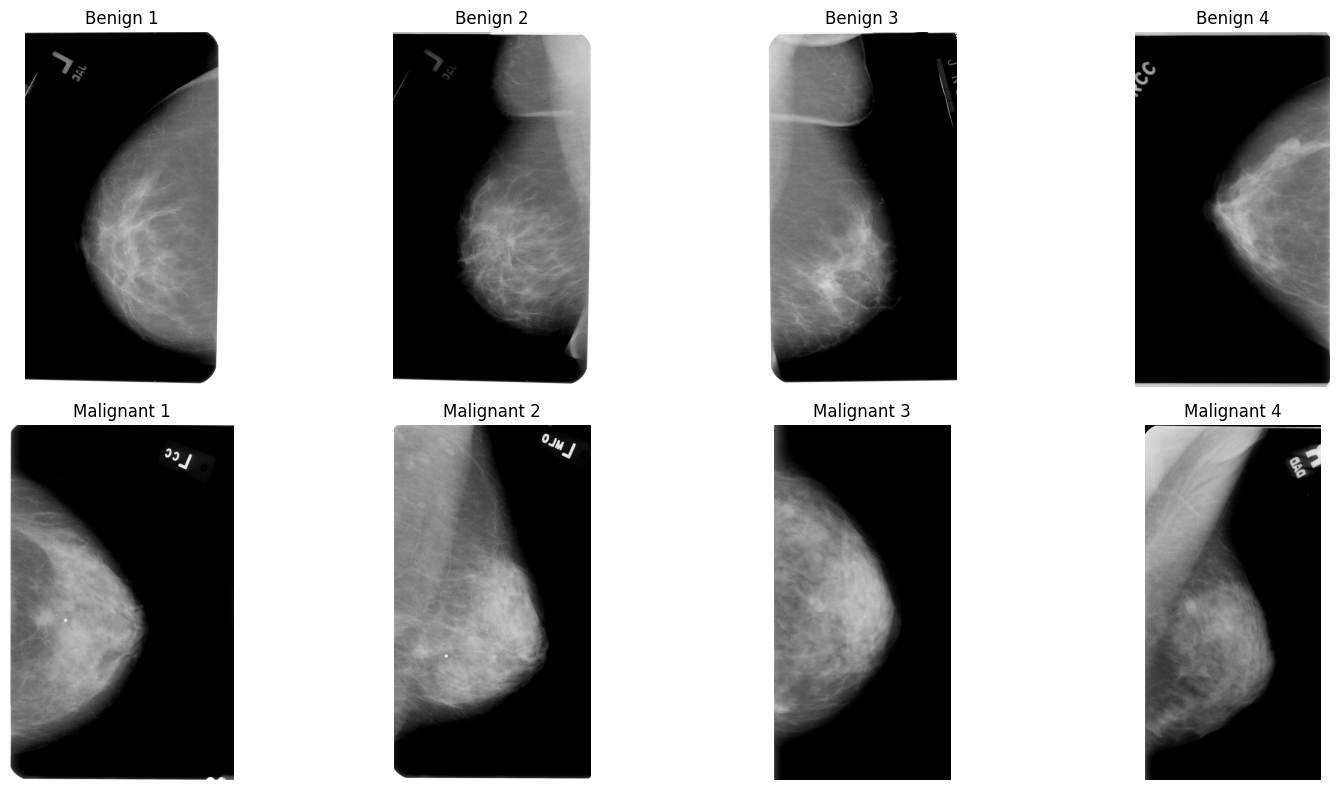

In [ ]:
#Visualise multiple benign and malignant images
n_samples = 4

fig, axes = plt.subplots(2, n_samples, figsize=(4*n_samples, 8))

for row, (label_val, label_name) in enumerate(zip([0, 1], ["Benign", "Malignant"])):
  samples = train_csv[train_csv["label"] == label_val].iloc[:n_samples]
  for col in range(n_samples):
    sample = samples.iloc[col]
    img = cv2.imread(sample["full_path"])
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    axes[row, col].imshow(img_gray, cmap="gray")
    axes[row, col].set_title(f"{label_name} {col+1}")
    axes[row, col].axis("off")

plt.tight_layout()
plt.show()

### 3.2 Patient-level Structure and Leakage Risk

The number of mammograms contributed by each patient is examined to assess the risk of data leakage during train-validation splitting. As multiple mammograms can originate from the same patient, a random image-level split could place related images across both partitions and produce overly optimistic validation results.

In [24]:
#Check for patient-level leakage risk between train/val split
print("Columns available:")
print(train_csv.columns.tolist())
print()

#CBIS-DDSM's standard column is 'patient_id' — confirm it's there
if 'patient_id' in train_csv.columns:
    n_rows = len(train_csv)
    n_unique_patients = train_csv['patient_id'].nunique()
    print(f"Total rows: {n_rows}")
    print(f"Unique patients: {n_unique_patients}")
    print(f"Rows per patient (avg): {n_rows / n_unique_patients:.2f}")

    #Show how many patients actually have more than one image/row
    counts = train_csv['patient_id'].value_counts()
    multi_image_patients = (counts > 1).sum()
    print(f"Patients with more than one image: {multi_image_patients} out of {n_unique_patients}")
else:
    print("No 'patient_id' column found — check column list above for the correct identifier.")

Columns available:
['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path', 'full_path', 'label']

Total rows: 1231
Unique patients: 691
Rows per patient (avg): 1.78
Patients with more than one image: 491 out of 691


### 3.3 Patient-Grouped Train–Validation Split

The predefined CBIS-DDSM test partition is retained as an untouched held-out test set. The development data is further divided into training and validation sets using StratidiedGroupKFold, with patient ID used as the grouping variable.

This preserves class balance while ensuring that mammograms from the same patient cannot appear in both the training and validation sets. A fixed random seed of 42 is used for reproducibility.

In [25]:
image_paths = train_csv["full_path"].values
labels = train_csv["label"].values.astype(np.int32)
patient_groups = train_csv["patient_id"].values

#Patient-grouped, stratified train/validation split
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    sgkf.split(
        image_paths,
        labels,
        groups=patient_groups
    )
)

X_train, X_val = image_paths[train_idx], image_paths[val_idx]
y_train, y_val = labels[train_idx], labels[val_idx]

#Preserve the official CBIS-DDSM test set
X_test = test_csv["full_path"].values
y_test = test_csv["label"].values.astype(np.int32)

In [62]:
#Validate train/validation split
print("Total development samples:", len(labels))
print("Total unique patients:", len(np.unique(patient_groups)))

print("\nTrain samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Test samples:", len(X_test))

print("\nTrain unique patients:",
      len(np.unique(patient_groups[train_idx])))

print("Validation unique patients:",
      len(np.unique(patient_groups[val_idx])))

print("\nPatient overlap:",
      len(
          set(patient_groups[train_idx]) &
          set(patient_groups[val_idx])
      ))

print("\nTrain class distribution:")
print(np.unique(y_train, return_counts=True))

print("\nValidation class distribution:")
print(np.unique(y_val, return_counts=True))

print("\nTest class distribution:")
print(np.unique(y_test, return_counts=True))

Total development samples: 1231
Total unique patients: 691

Train samples: 981
Validation samples: 250
Test samples: 361

Train unique patients: 553
Validation unique patients: 138

Patient overlap: 0

Train class distribution:
(array([0, 1], dtype=int32), array([502, 479]))

Validation class distribution:
(array([0, 1], dtype=int32), array([127, 123]))

Test class distribution:
(array([0, 1], dtype=int32), array([216, 145]))


In [27]:
#Function to get the class balance
def print_class_balance(name, y):
    benign = np.sum(y == 0)
    malignant = np.sum(y == 1)
    total = len(y)

    print(f"\n{name}:")
    print(f"  Total: {total}")
    print(f"  Benign: {benign} ({benign/total:.1%})")
    print(f"  Malignant: {malignant} ({malignant/total:.1%})")


print_class_balance("Train", y_train)
print_class_balance("Validation", y_val)
print_class_balance("Test", y_test)


Train:
  Total: 981
  Benign: 502 (51.2%)
  Malignant: 479 (48.8%)

Validation:
  Total: 250
  Benign: 127 (50.8%)
  Malignant: 123 (49.2%)

Test:
  Total: 361
  Benign: 216 (59.8%)
  Malignant: 145 (40.2%)


#### Patient Overlap Verification

Patient IDs are compared across the training, validation and held-out test sets to verify complete patient-level separation. Zero overlap confirms that no patient contributes mammograms to more than one partition, reducing the risk of patient-level data leakage.

In [28]:
#Check patient overlap across train, validation and test sets
train_patients = set(patient_groups[train_idx])
val_patients = set(patient_groups[val_idx])
test_patients = set(test_csv["patient_id"].values)

print("Patient overlap checks:")
print("Train vs Validation:", len(train_patients & val_patients))
print("Train vs Test:", len(train_patients & test_patients))
print("Validation vs Test:", len(val_patients & test_patients))

Patient overlap checks:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0


#### Class Distribution Across Data Partitions

The class distributions of the training, validation and held-out test sets are visualised to examine the balance between benign and malignant mammograms across each partition. This also verifies that the patient-grouped split maintains a reasonably similar class distribution between the training and validation sets.

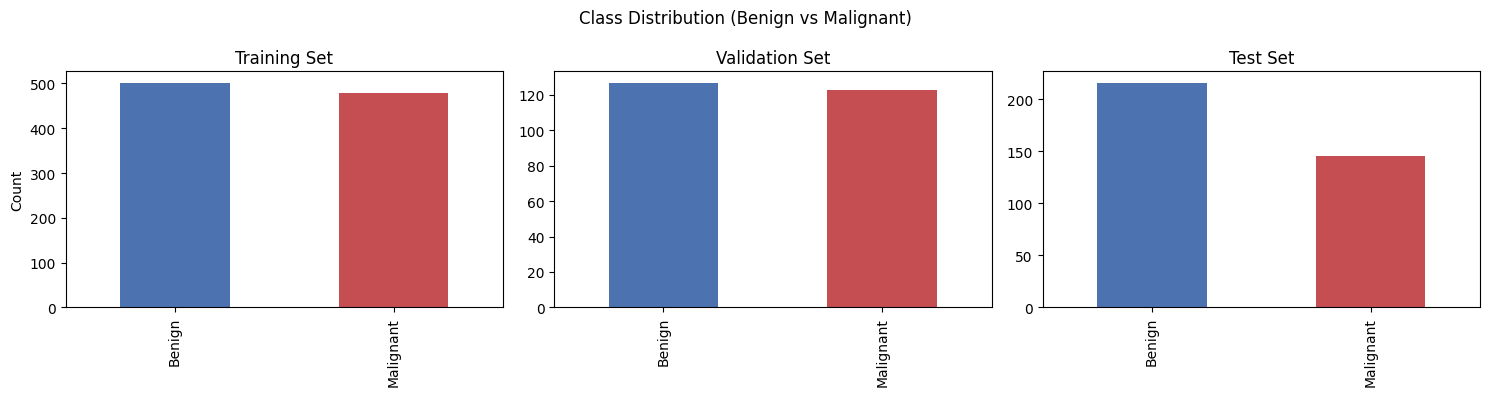

In [ ]:
#Class distribution across train, validation, and test sets
fig, axes = plt.subplots(1, 3, figsize=(15,4))

pd.Series(y_train).value_counts().rename({0:'Benign', 1:'Malignant'}).sort_index().plot(kind='bar', ax=axes[0], color=['#4C72B0','#C44E52'])
axes[0].set_title('Training Set')
axes[0].set_ylabel('Count')

pd.Series(y_val).value_counts().rename({0:'Benign', 1:'Malignant'}).sort_index().plot(kind='bar', ax=axes[1], color=['#4C72B0','#C44E52'])
axes[1].set_title('Validation Set')

pd.Series(y_test).value_counts().rename({0:'Benign', 1:'Malignant'}).sort_index().plot(kind='bar', ax=axes[2], color=['#4C72B0','#C44E52'])
axes[2].set_title('Test Set')

fig.suptitle('Class Distribution (Benign vs Malignant)')
plt.tight_layout()
plt.show()

#### Final Split Integrity Verification

A final set of integrity checks is performed before model development. The training, validation and test partitions are verified for patient and image-path overlap, duplicate mammograms and missing image files. Final sample counts are also confirmed to ensure that the datasets are complete and mutually exclusive.

In [29]:
#Final data-leakage and split-integrity checks
#Recover patient IDs for each split
train_patients = patient_groups[train_idx]
val_patients = patient_groups[val_idx]
test_patients = test_csv["patient_id"].values

# heck patient overlap between splits
train_val_patient_overlap = set(train_patients) & set(val_patients)
train_test_patient_overlap = set(train_patients) & set(test_patients)
val_test_patient_overlap = set(val_patients) & set(test_patients)

print("\nPATIENT OVERLAP")
print("Train, Validation:", len(train_val_patient_overlap))
print("Train, Test:", len(train_test_patient_overlap))
print("Validation, Test:", len(val_test_patient_overlap))

#Check full mammogram path overlap between splits
train_paths = set(X_train)
val_paths = set(X_val)
test_paths = set(X_test)

print("\nFULL IMAGE PATH OVERLAP")
print("Train, Validation:", len(train_paths & val_paths))
print("Train, Test:", len(train_paths & test_paths))
print("Validation, Test:", len(val_paths & test_paths))

#Check for duplicate mammograms within each split
print("\nDUPLICATES WITHIN SPLITS")
print("Train duplicates:", len(X_train) - len(set(X_train)))
print("Validation duplicates:", len(X_val) - len(set(X_val)))
print("Test duplicates:", len(X_test) - len(set(X_test)))

#Check that all image paths exist
missing_train = sum(not os.path.exists(path) for path in X_train)
missing_val = sum(not os.path.exists(path) for path in X_val)
missing_test = sum(not os.path.exists(path) for path in X_test)

print("\nMISSING IMAGE FILES")
print("Train:", missing_train)
print("Validation:", missing_val)
print("Test:", missing_test)

#Display final sample counts
print("\nSAMPLE COUNTS")
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))
print("Total:", len(X_train) + len(X_val) + len(X_test))

#Confirm that all leakage and integrity checks passed
checks = [
    len(train_val_patient_overlap) == 0,
    len(train_test_patient_overlap) == 0,
    len(val_test_patient_overlap) == 0,
    len(train_paths & val_paths) == 0,
    len(train_paths & test_paths) == 0,
    len(val_paths & test_paths) == 0,
    len(X_train) == len(set(X_train)),
    len(X_val) == len(set(X_val)),
    len(X_test) == len(set(X_test)),
    missing_train == 0,
    missing_val == 0,
    missing_test == 0
]

if all(checks):
    print("\nAll checks passed")
else:
    print("\nOne or more checks failed")


PATIENT OVERLAP
Train, Validation: 0
Train, Test: 0
Validation, Test: 0

FULL IMAGE PATH OVERLAP
Train, Validation: 0
Train, Test: 0
Validation, Test: 0

DUPLICATES WITHIN SPLITS
Train duplicates: 0
Validation duplicates: 0
Test duplicates: 0

MISSING IMAGE FILES
Train: 0
Validation: 0
Test: 0

SAMPLE COUNTS
Train: 981
Validation: 250
Test: 361
Total: 1592

All checks passed


## 4 Data Preprocessing and Input Pipelines

The verified image paths and binary labels are converted into TensorFlow input pipelines for model training and evaluation. All mammograms are resized to 224 x 224 pixels to provide a consistent input resolution across experiments.

### 4.1 Image Preprocessing

A TensorFlow tf.data pipeline is constructed to provide a consistent and efficient input process for all custom CNN experiments. Each JPEG mammogram is decoded as a three-channel image, resized to 224 x 224 pixels and converted to floating-point format. Pixel intensities are normalised to the range [0, 1], while labels are converted to floating-point values for binary classification.

The preprocessed images are cached to reduce repeated preprocessing across epochs. The training dataset is shuffled using the fixed random seed, while the validation and test datasets remain unshuffled to preserve a consistent evaluation order. All datasets are then batched using a batch size of 32 and prefetched using TensorFlow AUTOTUNE to improve input efficiency during training and evaluation.


In [67]:
#Build tf.data pipeline for custom CNN models
img_size = 224
batch_size = 32
AUTOTUNE = tf.data.AUTOTUNE

#Load and decode JPEG images
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    return image, label

#Resize and normalise images
def preprocess_image(image, label):
    image = tf.image.resize(
        image,
        (img_size, img_size)
    )
    image = tf.cast(image, tf.float32) / 255.0
    label = tf.cast(label, tf.float32)
    return image, label

#Build cached tf.data pipeline
def build_pipeline(paths, labels, shuffle=False):

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.map(
        preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    #Cache preprocessed images in RAM
    ds = ds.cache()

    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)

    return ds


#Build train, validation and test datasets
train_ds = build_pipeline(
    X_train,
    y_train,
    shuffle=True
)

val_ds = build_pipeline(
    X_val,
    y_val
)

test_ds = build_pipeline(
    X_test,
    y_test
)

print("Cached datasets built successfully.")

Cached datasets built successfully.


In [ ]:
for images, labels_batch in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels_batch.shape)
    print(
        f"Pixel range: "
        f"[{tf.reduce_min(images).numpy():.2f}, "
        f"{tf.reduce_max(images).numpy():.2f}]"
    )

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: [0.00, 1.00]


## 5 Custom CNN Development

The first experimental stage investigates CNNs trained from scratch. Model development begins with a simple unregularised baseline before progressively examining increased model capacity, individual regularisation strategies and hyperparameter optimisation. The same patient-grouped data partitions and evaluation framework are maintained across these experiments to support controlled comparison.

### 5.1 Baseline CNN
The baseline CNN establishes the reference architecture for the custom model experiments. It is trained from scratch without data augmentation, dropout or L2 regularisation, allowing subsequent architectural and regularisation changes to be evaluated against a common starting point.

The network contains three convolutional blocks with 32, 64 and 128 filters. Each convolution uses a 3 x 3 kernel with ReLU activation and is followed by 2 x 2 max pooling. The extracted feature maps are flattened and passed through a 128-unit dense layer, followed by a single sigmoid output unit that produces the predicted probability of malignancy.

The model is optimised using Adam with a learning rate of 0.001 and binary cross-entropy loss. Gradient clipping with a norm of 1.0 is applied during optimisation. Accuracy, AUC, sensitivity and precision are monitored during training.

In [33]:
#Build baseline CNN

#Set seed
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

def baseline_cnn():

    model = models.Sequential([

        layers.Input(shape=(img_size, img_size, 3)),

        #Feature extraction
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        #Classification
        layers.Flatten(),
        layers.Dense(128, activation='relu'),

        #Binary output
        layers.Dense(1, activation='sigmoid')

    ], name='Baseline_CNN')

    return model

baseline_model = baseline_cnn()
baseline_model.summary()

#Compile model
baseline_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001,
        clipnorm=1.0
    ),
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Recall(name='sensitivity'),
        tf.keras.metrics.Precision(name='precision')
    ]
)

print("Baseline model compiled")

Model: "Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

Baseline model compiled


#### Training Configuration and Callbacks

Two callbacks are used to control training and retain the strongest validation performance:

- EarlyStopping: Monitors validation AUC and stops training when no improvement is observed for 12 consecutive epochs. The weights from the epoch with the highest validation AUC are restored, reducing unnecessary training and limiting overfitting.
- ModelCheckpoint: Monitors validation AUC and saves the model whenever validation performance improves, ensuring that the best-performing model is retained for subsequent evaluation.

Using validation AUC for both callbacks keeps model selection consistent with AUC as the primary evaluation metric used throughout the experiments.

In [ ]:
#Callbacks
baseline_callbacks = [

    EarlyStopping(
        monitor='val_auc',
        patience=12,
        restore_best_weights=True,
        mode='max',
        verbose=1
    ),

    ModelCheckpoint(
        filepath='best_baseline_cnn.keras',
        monitor='val_auc',
        save_best_only=True,
        mode='max',
        verbose=1
    ),

    CSVLogger(
        'baseline_training_log.csv',
        append=False
    )
]

print("Callbacks defined")

Callbacks defined


#### Baseline Model Training

The baseline CNN is trained for a maximum of 50 epochs using the training dataset, with performance monitored on the validation set after each epoch. Early stopping may terminate training before the maximum epoch count if validation AUC does not improve for 7 consecutive epochs.

The training history is retained for subsequent analysis of training and validation performance across epochs.

In [ ]:
#Train
baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=baseline_callbacks,
    verbose=1
)
print("Baseline training complete")

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.4944 - auc: 0.5116 - loss: 0.7088 - precision: 0.4891 - sensitivity: 0.5265
Epoch 1: val_auc improved from None to 0.61670, saving model to best_baseline_cnn.keras

Epoch 1: finished saving model to best_baseline_cnn.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 100s 806ms/step - accuracy: 0.5423 - auc: 0.5650 - loss: 0.6913 - precision: 0.5304 - sensitivity: 0.5470 - val_accuracy: 0.5680 - val_auc: 0.6167 - val_loss: 0.7015 - val_precision: 0.5385 - val_sensitivity: 0.8537
Epoch 2/50
30/31 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.6262 - auc: 0.6842 - loss: 0.6493 - precision: 0.5798 - sensitivity: 0.7342
Epoch 2: val_auc improved from 0.61670 to 0.63629, saving model to best_baseline_cnn.keras

Epoch 2: finished saving model to best_baseline_cnn.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.6279 - auc: 0.6677 - loss: 0.6476 - precision: 0.6036 - sensitivity: 0.6931 - val_accuracy: 0.5760 - val_auc: 0.6363 - val_

#### Training and Validation Curves

Training and validation loss and AUC are visualised across epochs to examine the baseline model's learning behaviour and generalisation.

The loss curves show model convergence and help identify divergence between training and validation performance, which may indicate overfitting. The AUC curves shoe how discriminative performance develops during training and provide context for the validation AUC monitored by the early-stopping procedure.

Best epoch based on validation AUC: 2
Best validation AUC: 0.6363


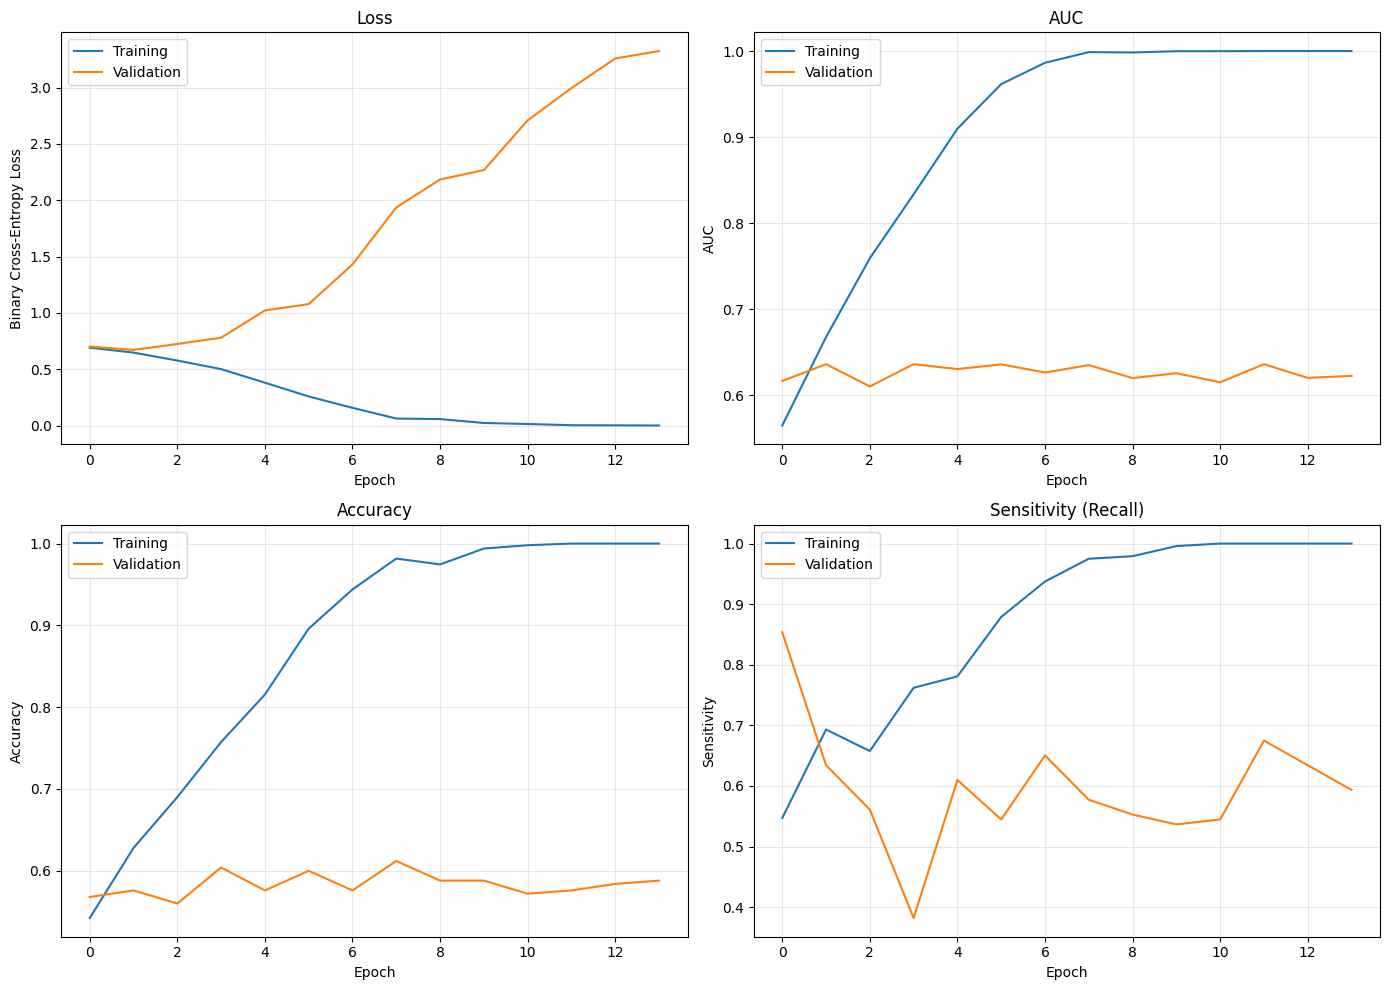

In [ ]:
#Traiing curves

#Find epoch with highest validation AUC
best_epoch = np.argmax(baseline_history.history['val_auc']) + 1
print(f"Best epoch based on validation AUC: {best_epoch}")
print(
    f"Best validation AUC: "
    f"{max(baseline_history.history['val_auc']):.4f}"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

#Loss
axes[0].plot(baseline_history.history['loss'], label='Training')
axes[0].plot(baseline_history.history['val_loss'], label='Validation')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

#AUC
axes[1].plot(baseline_history.history['auc'], label='Training')
axes[1].plot(baseline_history.history['val_auc'], label='Validation')
axes[1].set_title('AUC')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUC')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

#Accuracy
axes[2].plot(baseline_history.history['accuracy'], label='Training')
axes[2].plot(baseline_history.history['val_accuracy'], label='Validation')
axes[2].set_title('Accuracy')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Accuracy')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

#Sensitivity
axes[3].plot(baseline_history.history['sensitivity'], label='Training')
axes[3].plot(baseline_history.history['val_sensitivity'], label='Validation')
axes[3].set_title('Sensitivity (Recall)')
axes[3].set_xlabel('Epoch')
axes[3].set_ylabel('Sensitivity')
axes[3].legend()
axes[3].grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

The training curves show clear overfitting in the baseline CNN. Training loss decreases towards zero while training AUC and accuracy approach 1.0, whereas validation loss increases substantially and validation AUC remains around 0.65. A similar gap is visible for accuracy and sensitivity, with validation performance fluctuating while training performance continues to improve. This indicates that the unregularised baseline increasingly fits the training data without achieving corresponding improvements in generalisation.

### 5.2 Validation Evaluation Framework

A consistent validation procedure is used to evaluate each candidate model. Predicted probabilities are first used to calculate ROC AUC, which serves as the primary model-comparison metric.

Rather than applying the conventional fixed threshold of 0.5, an operating threshold is selected independently for each model using Youden's J statistic, defined as sensitivity + specificity - 1. The threshold that maximises this statistic on the validation set is selected, providing a data-driven balance between sensitivity and specificity.

Using the selected threshold, accuracy, sensitivity, specificity and precision are calculated together with the confusion matrix. Threshold selection is performed using validation data only; the final selected model and its validation-derived threshold are later locked before evaluation on the held-out test set.

In [42]:
#Evaluate model using the youden threshold
def evaluate_validation_model(model, val_ds, model_name):

    #Generate validation probabilities and true labels
    val_probs = model.predict(val_ds, verbose=0).flatten()
    val_true = np.concatenate([y.numpy() for _, y in val_ds]).astype(int)

    #Calculate ROC curve and select threshold using Youden's J
    fpr, tpr, thresholds = roc_curve(val_true, val_probs)
    youden_j = tpr - fpr
    best_idx = np.argmax(youden_j)
    threshold = thresholds[best_idx]

    #Generate predictions using the selected threshold
    val_pred = (val_probs >= threshold).astype(int)

    #Calculate confusion matrix
    cm = confusion_matrix(val_true, val_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    #Calculate evaluation metrics
    accuracy = accuracy_score(val_true, val_pred)
    auc = roc_auc_score(val_true, val_probs)
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    precision = precision_score(val_true, val_pred, zero_division=0)

    #Display results
    print(f"{model_name} - Validation Evaluation")
    print(f"Threshold:   {threshold:.4f}")
    print(f"Accuracy:    {accuracy:.4f}")
    print(f"AUC:         {auc:.4f}")
    print(f"Sensitivity: {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"Precision:   {precision:.4f}")
    print("\nConfusion Matrix:")
    print(cm)

    return {
        "threshold": threshold,
        "accuracy": accuracy,
        "auc": auc,
        "sensitivity": sensitivity,
        "specificity": specificity,
        "precision": precision,
        "confusion_matrix": cm,
        "y_true": val_true,
        "y_prob": val_probs,
        "y_pred": val_pred
    }

In [44]:
baseline_results = evaluate_validation_model(baseline_model, val_ds, "Baseline CNN")

Baseline CNN - Validation Evaluation
Threshold:   0.5620
Accuracy:    0.6320
AUC:         0.6367
Sensitivity: 0.5285
Specificity: 0.7323
Precision:   0.6566

Confusion Matrix:
[[93 34]
 [58 65]]


The baseline CNN achieved a validation AUC of 0.6367, indicating modest discrimination between benign and malignant mammograms. Using the validation-derived Youden threshold of 0.5620, the model achieved a sensitivity of 0.5285 and specificity of 0.7323, showing stronger identification of benign cases than malignant cases. These results establish the reference performance for the subsequent custom CNN experiments.

### 5.3 Scaled-Up CNN

The baseline architecture is expanded to investigate whether increased model capacity improves validation performance before regularisation is introduced. The original three convolutional blocks are retained, with an additional 256-filter convolutional block added to increase feature-extraction capacity.

The classification head is also expanded from a single 128-unit dense layer to two dense layers containing 256 and 128 units. No data augmentation, dropout or L2 regularisation is applied at this stage, allowing the effect of increased model capacity to be examined independently.

The scaled-up CNN uses the same input pipeline, optimiser, learning rate, loss function and evaluation framework as the baseline model.

In [46]:
#Design deeper model

#Set seed
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

def deep_cnn():

    model = models.Sequential([

        #Input
        layers.Input(shape=(img_size, img_size, 3)),

        #Convolutional Block 1
        layers.Conv2D(32, (3, 3),activation='relu'),
        layers.MaxPooling2D((2, 2)),

        #Convolutional Block 2
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        #Convolutional Block 3
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        #Additional convolutional block in the scaled CNN
        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        #Classification head
        layers.Flatten(),

        #Increased dense capacity
        layers.Dense(256, activation='relu'),
        layers.Dense(128, activation='relu'),

        #Binary output
        layers.Dense(1, activation='sigmoid')

    ], name='Deep_CNN')

    return model

deep_model = deep_cnn()
deep_model.summary()

#Compile model
deep_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001,
        clipnorm=1.0
    ),

    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Recall(name='sensitivity'),
        tf.keras.metrics.Precision(name='precision')
    ]
)

print("Deep CNN compiled")


Model: "Deep_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,858,881 (37.61 MB)

 Trainable params: 9,858,881 (37.61 MB)

 Non-trainable params: 0 (0.00 B)

Deep CNN compiled


#### Model Configuration and callabacks

In [ ]:
#Define Callbacks
deep_callbacks = [

    EarlyStopping(
        monitor='val_auc',
        patience=12,
        restore_best_weights=True,
        mode='max',
        verbose=1
    ),

    ModelCheckpoint(
        filepath='best_deep_cnn.keras',
        monitor='val_auc',
        save_best_only=True,
        mode='max',
        verbose=1
    ),

    CSVLogger(
        'deep_training_log.csv',
        append=False
    )
]

print("Callbacks defined")

Callbacks defined


#### Model Training

In [ ]:
#Train model
deep_history = deep_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=deep_callbacks,
    verbose=1
)

print("Deep CNN training complete")

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step - accuracy: 0.5100 - auc: 0.4969 - loss: 0.6974 - precision: 0.5205 - sensitivity: 0.7925
Epoch 1: val_auc improved from None to 0.59033, saving model to best_deep_cnn.keras

Epoch 1: finished saving model to best_deep_cnn.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 19s 398ms/step - accuracy: 0.5189 - auc: 0.5611 - loss: 0.6931 - precision: 0.5042 - sensitivity: 0.8727 - val_accuracy: 0.5640 - val_auc: 0.5903 - val_loss: 0.6851 - val_precision: 0.5522 - val_sensitivity: 0.6016
Epoch 2/50
30/31 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.5788 - auc: 0.5998 - loss: 0.6751 - precision: 0.5720 - sensitivity: 0.5095
Epoch 2: val_auc improved from 0.59033 to 0.60540, saving model to best_deep_cnn.keras

Epoch 2: finished saving model to best_deep_cnn.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 95ms/step - accuracy: 0.6086 - auc: 0.6452 - loss: 0.6583 - precision: 0.6072 - sensitivity: 0.5616 - val_accuracy: 0.5560 - val_auc: 0.6054 - val_loss: 0.6835 - va

#### Training curves

Best epoch based on validation AUC: 5
Best validation AUC: 0.6590


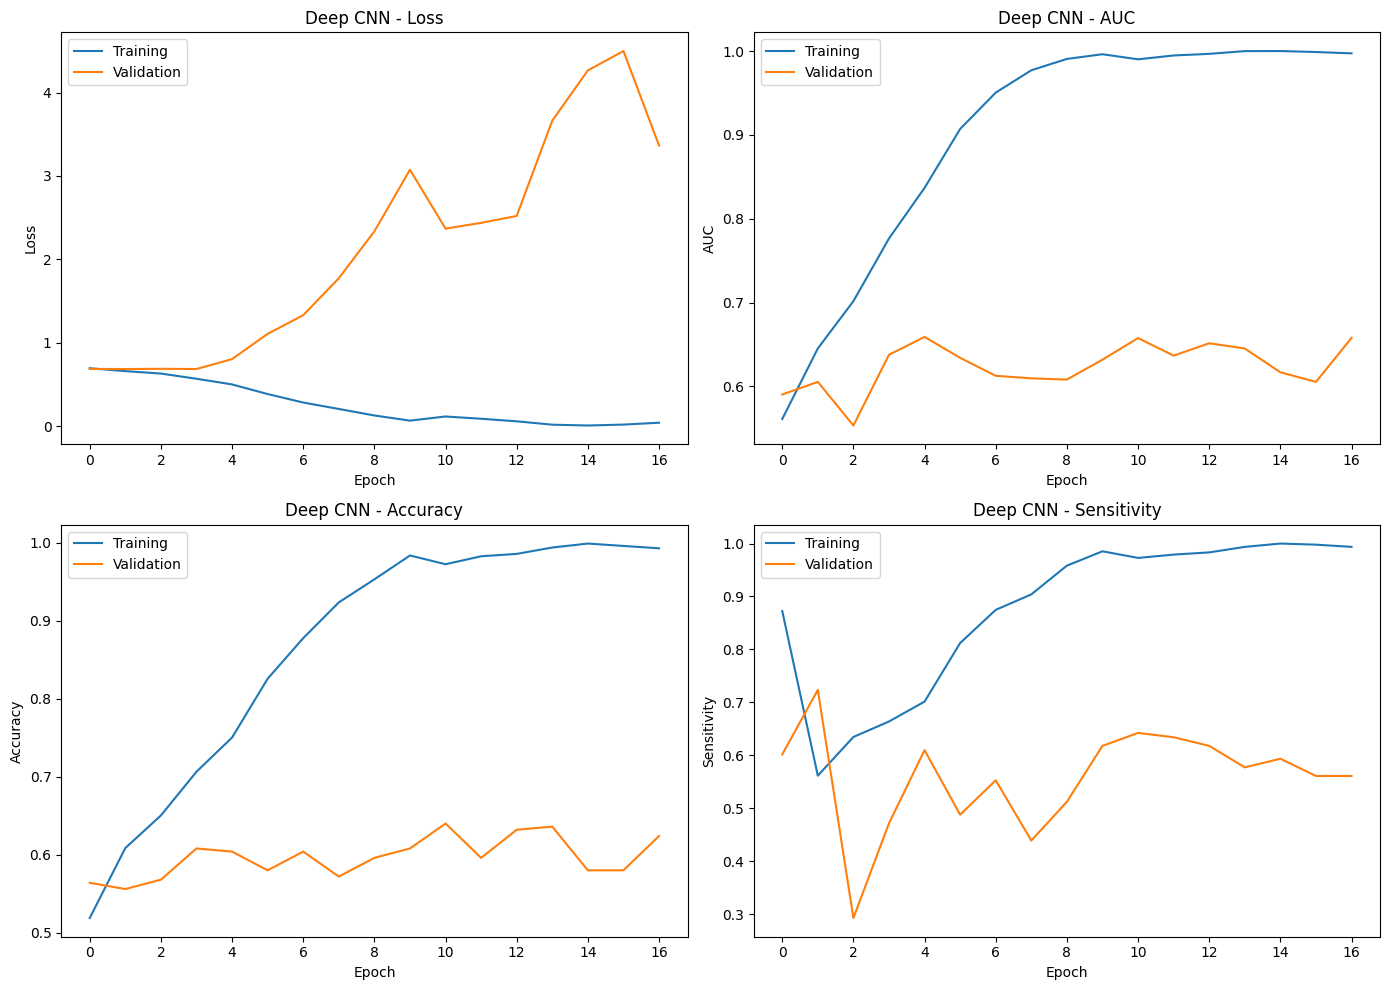

In [ ]:
#Best epoch according to validation AUC
best_epoch = np.argmax(deep_history.history['val_auc']) + 1
print(f"Best epoch based on validation AUC: {best_epoch}")
print(
    f"Best validation AUC: "
    f"{max(deep_history.history['val_auc']):.4f}"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#Loss
axes[0, 0].plot(deep_history.history['loss'], label='Training')
axes[0, 0].plot(deep_history.history['val_loss'], label='Validation')
axes[0, 0].set_title('Deep CNN - Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()

#AUC
axes[0, 1].plot(deep_history.history['auc'], label='Training')
axes[0, 1].plot(deep_history.history['val_auc'], label='Validation')
axes[0, 1].set_title('Deep CNN - AUC')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('AUC')
axes[0, 1].legend()

#Accuracy
axes[1, 0].plot(deep_history.history['accuracy'], label='Training')
axes[1, 0].plot(deep_history.history['val_accuracy'], label='Validation')
axes[1, 0].set_title('Deep CNN - Accuracy')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].legend()

#Sensitivity
axes[1, 1].plot(deep_history.history['sensitivity'], label='Training')
axes[1, 1].plot(deep_history.history['val_sensitivity'], label='Validation')
axes[1, 1].set_title('Deep CNN - Sensitivity')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Sensitivity')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

The scaled-up CNN continues to show substantial overfitting. Training loss approaches zero while training AUC and accuracy reach almost 1.0, whereas validation loss increases and validation performance remains considerably lower. Validation AUC fluctuates around 0.55 to 0.65 despite the continued improvement in training performance, with similar instability visible in validation accuracy and sensitivity. This indicates that increasing model capacity alone does not improve generalisation and motivates the subsequent investigation of regularisation techniques.

In [156]:
scaled_results = evaluate_validation_model(scaled_model, val_ds, "Scaled-Up CNN")

Scaled-Up CNN - Validation Evaluation
Threshold:   0.5481
Accuracy:    0.6520
AUC:         0.6594
Sensitivity: 0.5935
Specificity: 0.7087
Precision:   0.6636

Confusion Matrix:
[[90 37]
 [50 73]]


The scaled-up CNN achieved a validation AUC of 0.6594, compared with 0.6367 for the baseline, indicating a modest improvement in discrimination from increased model capacity. Sensitivity also increased from 0.5285 to 0.5935, while specificity decreased slightly from 0.7323 to 0.7087. Despite these improvements, the training curves continued to show substantial overfitting, suggesting that increasing capacity alone was insufficient to achieve strong generalisation.

### 5.4 Regularisation Ablation

Following the scaled-up CNN experiment, three regularisation strategies are investigated independently: data augmentation, L2 regularisation and dropout. Each technique is applied separately to the scaled-up architecture so that its effect on validation performance and generalisation can be assessed without combining multiple regularisation changes.

Data augmentation introduces controlled transformations to the training images, L2 regularisation penalises large model weights, and dropout randomly deactivates a proportion of activations during training. The individual experiments therefore provide a controlled comparison of how each regularisation strategy affects the same underlying CNN architecture.

#### 5.4.1 Data Augmentation
Data augmentation is applied during training to introduce controlled variation into the mammograms without altering the validation data. The augmentation pipeline includes horizontal flipping, small rotations, zoom, translation and contrast adjustments.

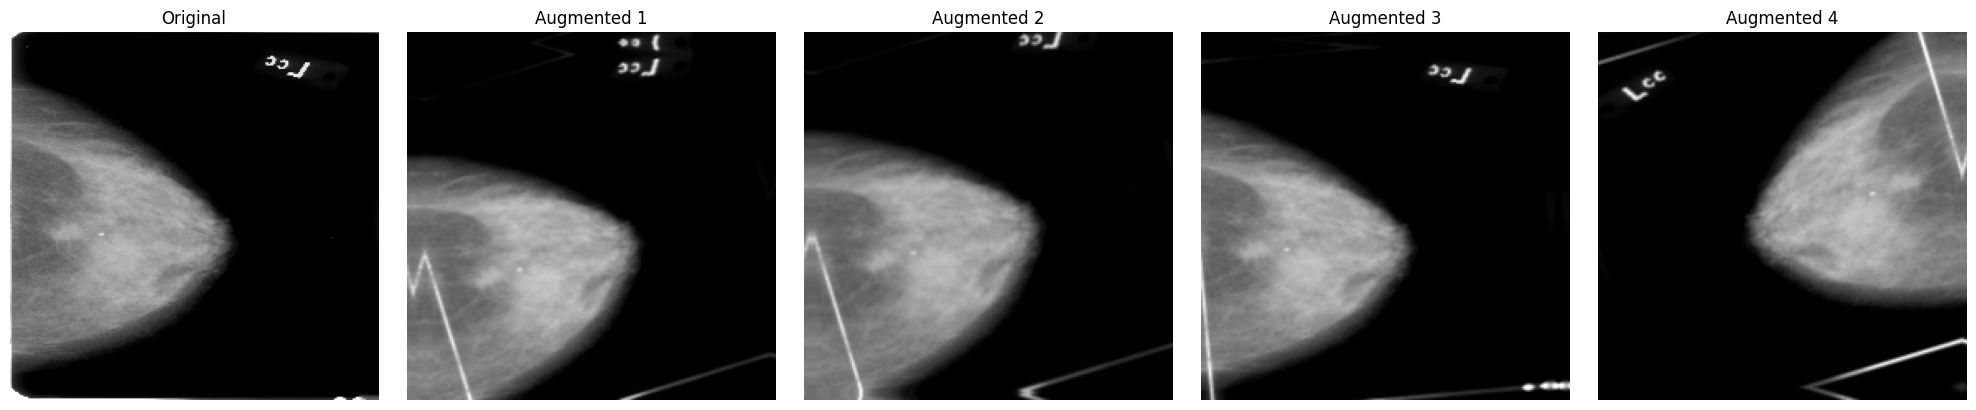

In [ ]:
#Use the same augmentation transformations as the model
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
    layers.RandomContrast(0.1)
], name='Augmentation')

#Pick one malignant training image
sample = train_csv[train_csv["label"] == 1].iloc[0]
img = cv2.imread(sample["full_path"])
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
#Resize to model input size
img_resized = tf.image.resize(img_rgb,(img_size, img_size))
# Add batch dimension
img_batch = tf.expand_dims(img_resized,axis=0)

#Show original + 4 augmentation
fig, axes = plt.subplots(1, 5,figsize=(20, 4))
axes[0].imshow(tf.cast(img_resized, tf.uint8))
axes[0].set_title("Original")
axes[0].axis("off")

for i in range(1, 5):
    augmented = data_augmentation(img_batch, training=True)
    axes[i].imshow(tf.cast(augmented[0], tf.uint8))
    axes[i].set_title(f"Augmented {i}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

##### Augmentation CNN

The scaled-up CNN architecture is retained, with the augmentation pipeline added before the convolutional layers. This keeps the underlying network unchanged so that the effect of training-time data augmentation can be evaluated independently.

In [53]:
#Set seeds
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

def augmentation_cnn():

    model = models.Sequential([

        #Input
        layers.Input(shape=(img_size, img_size, 3)),

        #Data augmentation
        data_augmentation,

        #Convolutional Block 1
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        #Convolutional Block 2
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        #Convolutional Block 3
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        #Additional convolutional block
        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        #Classification head
        layers.Flatten(),

        #Increased dense capacity
        layers.Dense(256, activation='relu'),
        layers.Dense(128, activation='relu'),

        #Binary output
        layers.Dense(1, activation='sigmoid')

    ], name='Augmentation_CNN')

    return model


augmentation_model = augmentation_cnn()
augmentation_model.summary()

#Compile model
augmentation_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001,
        clipnorm=1.0
    ),

    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Recall(name='sensitivity'),
        tf.keras.metrics.Precision(name='precision')
    ]
)

print("Augmentation-only CNN compiled successfully.")

Model: "Augmentation_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,858,881 (37.61 MB)

 Trainable params: 9,858,881 (37.61 MB)

 Non-trainable params: 0 (0.00 B)

Augmentation-only CNN compiled successfully.


#### Model configurations and Callbacks

In [ ]:
#Define Callbacks
augmentation_callbacks = [

    EarlyStopping(
        monitor='val_auc',
        patience=12,
        restore_best_weights=True,
        mode='max',
        verbose=1
    ),

    ModelCheckpoint(
        filepath=os.path.join(
            save_dir,
            'best_augmentation_cnn.keras'
        ),
        monitor='val_auc',
        save_best_only=True,
        mode='max',
        verbose=1
    ),

    CSVLogger(
        os.path.join(
            save_dir,
            'augmentation_training_log.csv'
        ),
        append=False
    )
]

print("Callbacks defined")

Callbacks defined


#Model Training

In [ ]:
augmentation_history = augmentation_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=augmentation_callbacks,
    verbose=1
)
print("Augmented CNN training complete")

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.4791 - auc: 0.4768 - loss: 0.6966 - precision: 0.4638 - sensitivity: 0.3678
Epoch 1: val_auc improved from None to 0.53214, saving model to /content/drive/MyDrive/CBIS-DDSM/best_augmentation_cnn.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_augmentation_cnn.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 28s 670ms/step - accuracy: 0.4995 - auc: 0.4880 - loss: 0.6956 - precision: 0.4855 - sensitivity: 0.4196 - val_accuracy: 0.5320 - val_auc: 0.5321 - val_loss: 0.6923 - val_precision: 0.5484 - val_sensitivity: 0.2764
Epoch 2/50
30/31 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.5379 - auc: 0.5170 - loss: 0.6912 - precision: 0.4974 - sensitivity: 0.1580
Epoch 2: val_auc improved from 0.53214 to 0.56050, saving model to /content/drive/MyDrive/CBIS-DDSM/best_augmentation_cnn.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_augmentation_cnn.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 9

#### Training curves

Best epoch based on validation AUC: 23
Best validation AUC: 0.6613


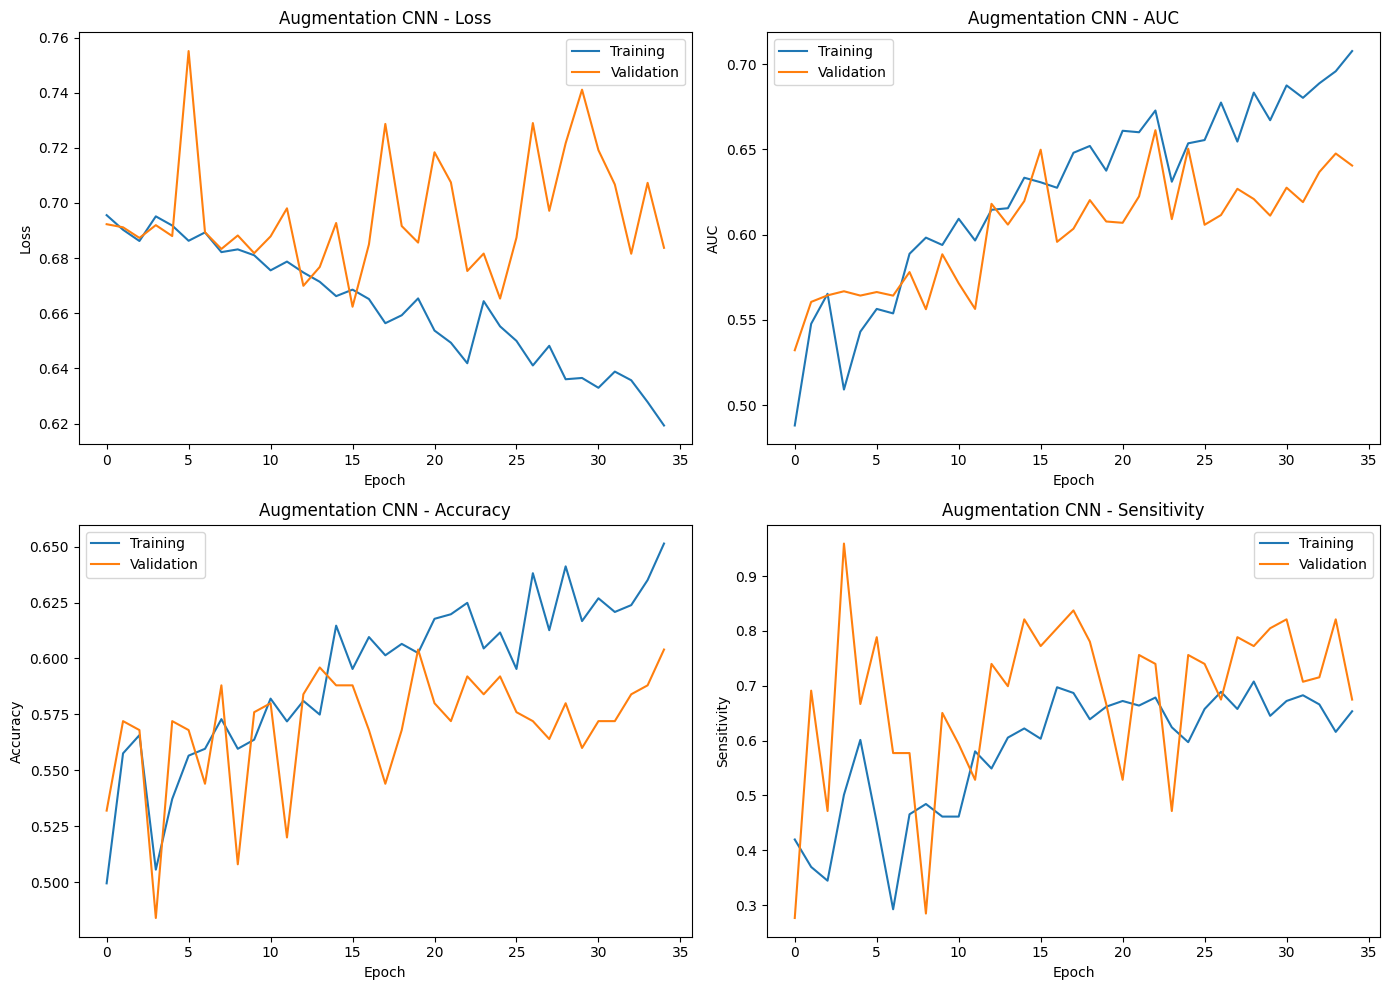

In [ ]:
#Best epoch according to validation AUC
best_epoch = np.argmax(augmentation_history.history['val_auc']) + 1
print(f"Best epoch based on validation AUC: {best_epoch}")
print(
    f"Best validation AUC: "
    f"{max(augmentation_history.history['val_auc']):.4f}"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#Loss
axes[0, 0].plot(augmentation_history.history['loss'], label='Training')
axes[0, 0].plot(augmentation_history.history['val_loss'], label='Validation')
axes[0, 0].set_title('Augmentation CNN - Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()

#AUC
axes[0, 1].plot(augmentation_history.history['auc'], label='Training')
axes[0, 1].plot(augmentation_history.history['val_auc'], label='Validation')
axes[0, 1].set_title('Augmentation CNN - AUC')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('AUC')
axes[0, 1].legend()

#Accuracy
axes[1, 0].plot(augmentation_history.history['accuracy'], label='Training')
axes[1, 0].plot(augmentation_history.history['val_accuracy'], label='Validation')
axes[1, 0].set_title('Augmentation CNN - Accuracy')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].legend()

#Sensitivity
axes[1, 1].plot(augmentation_history.history['sensitivity'], label='Training')
axes[1, 1].plot(augmentation_history.history['val_sensitivity'], label='Validation')
axes[1, 1].set_title('Augmentation CNN - Sensitivity')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Sensitivity')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

The augmentation CNN shows a substantially smaller training–validation gap than the unregularised models. Training loss decreases gradually rather than approaching zero, while training and validation AUC remain considerably closer throughout training. Although validation performance continues to fluctuate, the curves indicate that augmentation reduces the severe overfitting observed in the baseline and scaled-up CNNs.

In [158]:
augmentation_results = evaluate_validation_model(augmentation_model, val_ds, "Augmentation CNN")

Augmentation CNN - Validation Evaluation
Threshold:   0.5887
Accuracy:    0.6560
AUC:         0.6608
Sensitivity: 0.6423
Specificity: 0.6693
Precision:   0.6529

Confusion Matrix:
[[85 42]
 [44 79]]


The model achieved a validation AUC of 0.6608, which is similar to the scaled-up CNN's AUC of 0.6594. However, sensitivity increased from 0.5935 to 0.6423, while specificity decreased from 0.7087 to 0.6693. Therefore, augmentation improved generalisation behaviour and shifted the operating balance towards greater malignant-case detection, but did not produce a meaningful improvement in overall discrimination.

#### 5.4.2 L2 Regularisation

L2 regularisation is evaluated independently using the same scaled-up CNN architecture. A regularisation strength of 1 x 10⁻⁴ is applied to the convolutional and dense layers, penalising large weights during training while leaving the remaining architecture and training configuration unchanged.

This experiment isolates the effect of L2 regularisation without data augmentation or dropout.

In [56]:
#Set seeds
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

L2_STRENGTH = 1e-4

def l2_cnn():
    model = models.Sequential([
        layers.Input(shape=(img_size, img_size, 3)),

        #Convolutional Block 1
        layers.Conv2D(32, (3, 3), activation='relu',
                      kernel_regularizer=regularizers.l2(L2_STRENGTH)
        ),
        layers.MaxPooling2D((2, 2)),

        #Convolutional Block 2
        layers.Conv2D(64, (3, 3),  activation='relu',
                      kernel_regularizer=regularizers.l2(L2_STRENGTH)
        ),
        layers.MaxPooling2D((2, 2)),

        #Convolutional Block 3
        layers.Conv2D(128, (3, 3), activation='relu',
                      kernel_regularizer=regularizers.l2(L2_STRENGTH)
        ),
        layers.MaxPooling2D((2, 2)),

        #Additional convolutional block
        layers.Conv2D(256, (3, 3), activation='relu',
                      kernel_regularizer=regularizers.l2(L2_STRENGTH)
        ),
        layers.MaxPooling2D((2, 2)),

        #Classification head
        layers.Flatten(),

        #Increased dense capacity
        layers.Dense(256, activation='relu',
                     kernel_regularizer=regularizers.l2(L2_STRENGTH)
        ),

        layers.Dense(128, activation='relu',
                     kernel_regularizer=regularizers.l2(L2_STRENGTH)
        ),

        #Binary output
        layers.Dense(1, activation='sigmoid')

    ], name='L2_CNN')

    return model


l2_model = l2_cnn()
l2_model.summary()

#Compile model
l2_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001,
        clipnorm=1.0
    ),

    loss='binary_crossentropy',

    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Recall(name='sensitivity'),
        tf.keras.metrics.Precision(name='precision')
    ]
)

print("L2-only CNN compiled successfully.")

Model: "L2_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_15 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,858,881 (37.61 MB)

 Trainable params: 9,858,881 (37.61 MB)

 Non-trainable params: 0 (0.00 B)

L2-only CNN compiled successfully.


#### Model configurations and Callabcks

In [ ]:
#Define callbacks
l2_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_auc',
        mode='max',
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(save_dir, 'best_l2_cnn.keras'),
        monitor='val_auc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        os.path.join(save_dir, 'l2_training_log.csv'),
        append=False
    )
]

print("Callbacks defined")

Callbacks defined


#### Model training

In [ ]:
l2_history = l2_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=l2_callbacks,
    verbose=1
)
print("L2 CNN training complete")

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step - accuracy: 0.4751 - auc: 0.4518 - loss: 0.7818 - precision: 0.4746 - sensitivity: 0.4711
Epoch 1: val_auc improved from None to 0.50000, saving model to /content/drive/MyDrive/CBIS-DDSM/best_l2_cnn.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_l2_cnn.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 25s 470ms/step - accuracy: 0.4924 - auc: 0.4770 - loss: 0.7639 - precision: 0.4780 - sensitivity: 0.4301 - val_accuracy: 0.5080 - val_auc: 0.5000 - val_loss: 0.7371 - val_precision: 0.0000e+00 - val_sensitivity: 0.0000e+00
Epoch 2/50
30/31 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.5194 - auc: 0.5165 - loss: 0.7306 - precision: 0.3688 - sensitivity: 0.2227
Epoch 2: val_auc improved from 0.50000 to 0.56818, saving model to /content/drive/MyDrive/CBIS-DDSM/best_l2_cnn.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_l2_cnn.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 89ms/step - accuracy: 0.5178 - a

#### Training Curves

Best epoch based on validation AUC: 9
Best validation AUC: 0.6078


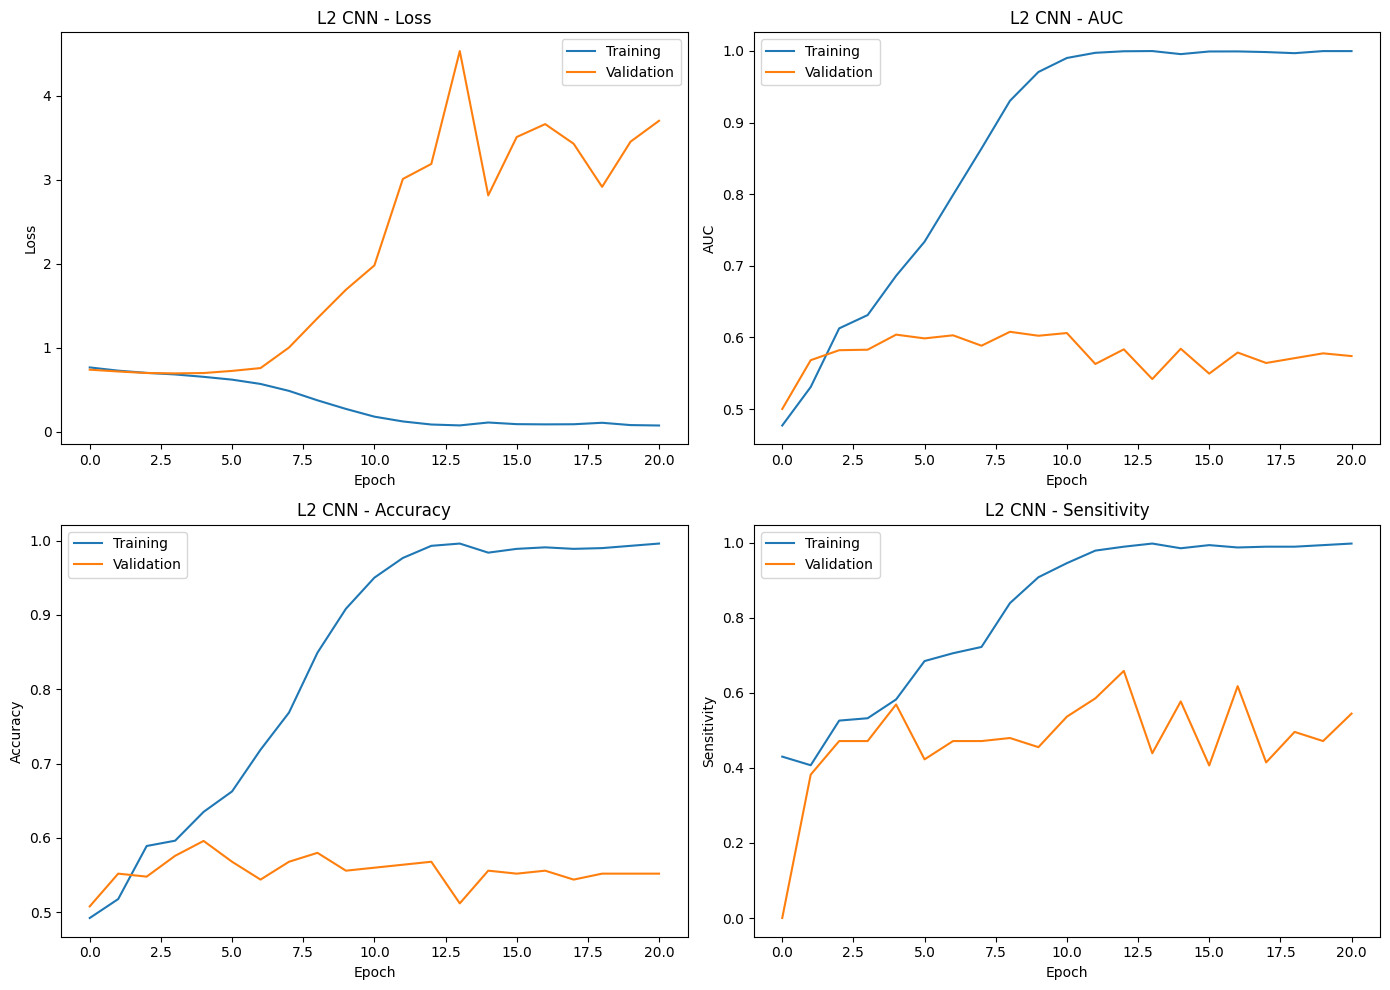

In [ ]:
#Best epoch according to validation AUC
best_epoch = np.argmax(l2_history.history['val_auc']) + 1

print(f"Best epoch based on validation AUC: {best_epoch}")
print(
    f"Best validation AUC: "
    f"{max(l2_history.history['val_auc']):.4f}"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#Loss
axes[0, 0].plot(l2_history.history['loss'], label='Training')
axes[0, 0].plot(l2_history.history['val_loss'], label='Validation')
axes[0, 0].set_title('L2 CNN - Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()

#AUC
axes[0, 1].plot(l2_history.history['auc'], label='Training')
axes[0, 1].plot(l2_history.history['val_auc'], label='Validation')
axes[0, 1].set_title('L2 CNN - AUC')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('AUC')
axes[0, 1].legend()

#Accuracy
axes[1, 0].plot(l2_history.history['accuracy'], label='Training')
axes[1, 0].plot(l2_history.history['val_accuracy'], label='Validation')
axes[1, 0].set_title('L2 CNN - Accuracy')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].legend()

#Sensitivity
axes[1, 1].plot(l2_history.history['sensitivity'], label='Training')
axes[1, 1].plot(l2_history.history['val_sensitivity'], label='Validation')
axes[1, 1].set_title('L2 CNN - Sensitivity')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Sensitivity')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

The L2-regularised CNN continues to show substantial overfitting. Training loss decreases towards zero and training AUC approaches 1.0, while validation loss increases and validation AUC remains substantially lower. This indicates that the applied L2 penalty was insufficient to control overfitting in the scaled-up architecture.

In [161]:
l2_results = evaluate_validation_model(l2_model, val_ds, "L2-Regularised CNN")

L2-Regularised CNN - Validation Evaluation
Threshold:   0.3884
Accuracy:    0.5920
AUC:         0.6086
Sensitivity: 0.5447
Specificity: 0.6378
Precision:   0.5929

Confusion Matrix:
[[81 46]
 [56 67]]


The model achieved a validation AUC of 0.6086, lower than both the scaled-up CNN and augmentation CNN. At the Youden threshold of 0.3884, sensitivity was 0.5447 and specificity was 0.6378. Therefore, L2 regularisation at the tested strength of 1 × 10⁻⁴ did not improve generalisation or discrimination relative to the unregularised scaled-up model.

#### 5.4.3 Dropout Regularisation

Dropout is evaluated independently using the same scaled-up CNN architecture. A dropout rate of 0.5 is applied after the dense layers, randomly deactivating 50% of activations during training to reduce reliance on individual learned features.

The remaining architecture and training configuration are unchanged, allowing the effect of dropout to be evaluated without data augmentation or L2 regularisation.

In [58]:
#Set seeds
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

def dropout_cnn():
    model = models.Sequential([
        layers.Input(shape=(img_size, img_size, 3)),

        #Convolutional Block 1
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        #Convolutional Block 2
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        #Convolutional Block 3
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        #Additional convolutional block
        layers.Conv2D(256, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        #Classification head
        layers.Flatten(),

        #Increased dense capacity
        layers.Dense(256, activation='relu'),
        layers.Dense(128, activation='relu'),

        #Dropout regularisation
        layers.Dropout(0.5),

        #Binary output
        layers.Dense(1, activation='sigmoid')

    ], name='Dropout_CNN')

    return model


dropout_model = dropout_cnn()
dropout_model.summary()

dropout_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001,
        clipnorm=1.0
    ),

    loss='binary_crossentropy',

    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Recall(name='sensitivity'),
        tf.keras.metrics.Precision(name='precision')
    ]
)

print("Dropout-only CNN compiled successfully.")


Model: "Dropout_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_19 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_20 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,858,881 (37.61 MB)

 Trainable params: 9,858,881 (37.61 MB)

 Non-trainable params: 0 (0.00 B)

Dropout-only CNN compiled successfully.


#### Model Configuration and Callbacks

In [ ]:
#Define callbacks
dropout_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_auc',
        mode='max',
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(
            save_dir,
            'best_dropout_cnn.keras'
        ),
        monitor='val_auc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        os.path.join(
            save_dir,
            'dropout_training_log.csv'
        ),
        append=False
    )
]

print("Callbacks defined")

Callbacks defined


#### Model Training

In [ ]:
dropout_history = dropout_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=dropout_callbacks,
    verbose=1
)
print("Dropout CNN training complete")

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.5033 - auc: 0.5035 - loss: 0.6954 - precision: 0.5062 - sensitivity: 0.7059
Epoch 1: val_auc improved from None to 0.60028, saving model to /content/drive/MyDrive/CBIS-DDSM/best_dropout_cnn.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_dropout_cnn.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 15s 300ms/step - accuracy: 0.5158 - auc: 0.5196 - loss: 0.6941 - precision: 0.5036 - sensitivity: 0.5804 - val_accuracy: 0.5960 - val_auc: 0.6003 - val_loss: 0.6895 - val_precision: 0.6170 - val_sensitivity: 0.4715
Epoch 2/50
30/31 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.5700 - auc: 0.5826 - loss: 0.6826 - precision: 0.5872 - sensitivity: 0.6020
Epoch 2: val_auc improved from 0.60028 to 0.60860, saving model to /content/drive/MyDrive/CBIS-DDSM/best_dropout_cnn.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_dropout_cnn.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy

#### Training curves

Best epoch based on validation AUC: 10
Best validation AUC: 0.6501


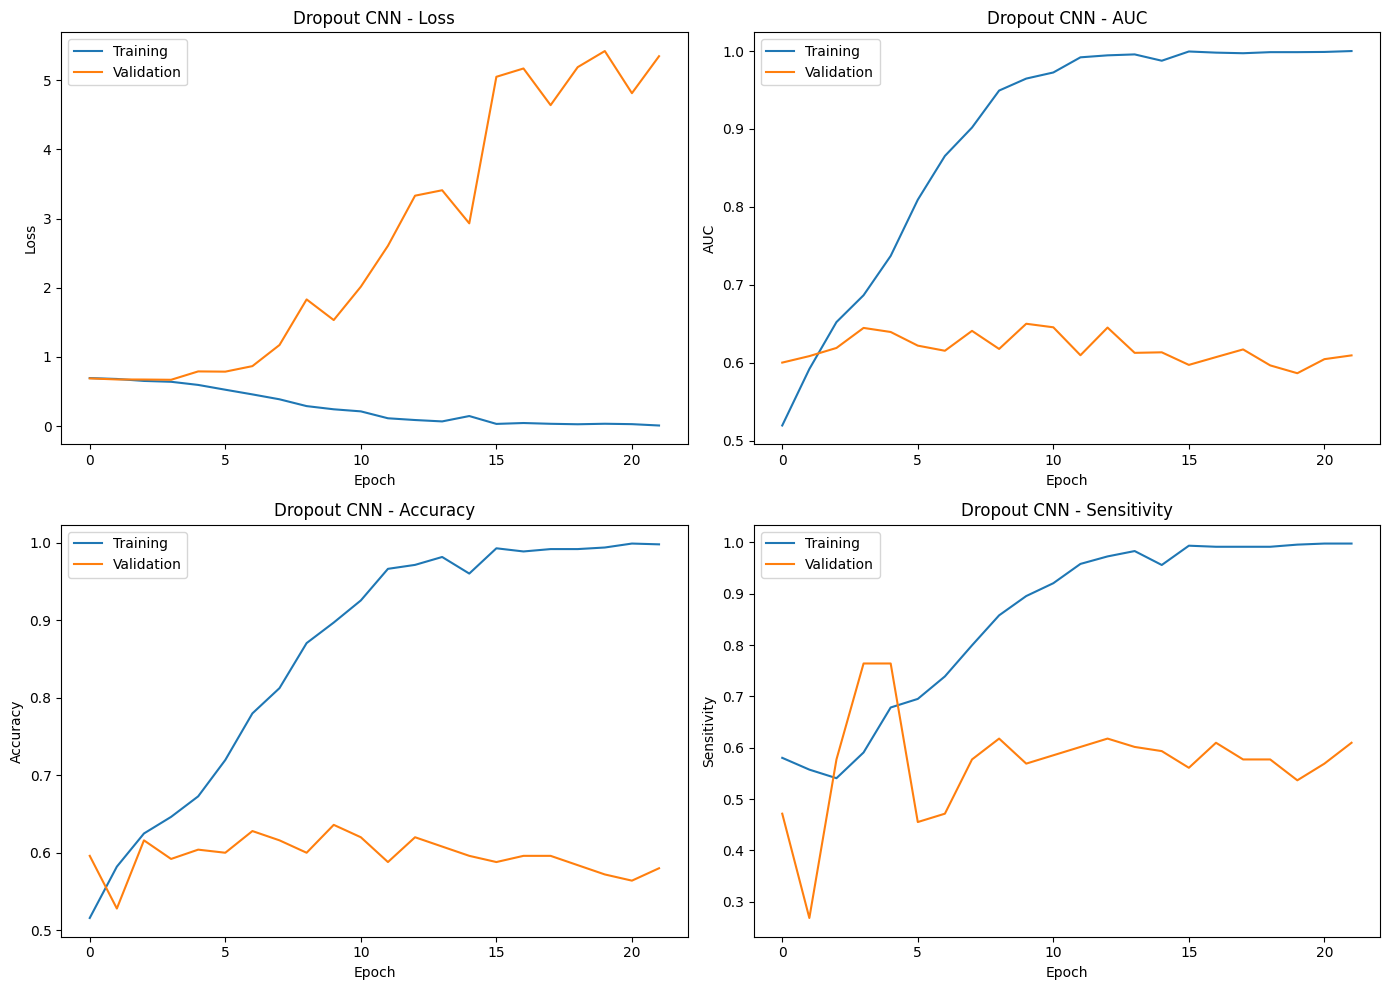

In [ ]:
#Best epoch according to validation AUC
best_epoch = np.argmax(dropout_history.history['val_auc']) + 1

print(f"Best epoch based on validation AUC: {best_epoch}")
print(
    f"Best validation AUC: "
    f"{max(dropout_history.history['val_auc']):.4f}"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#Loss
axes[0, 0].plot(dropout_history.history['loss'], label='Training')
axes[0, 0].plot(dropout_history.history['val_loss'], label='Validation')
axes[0, 0].set_title('Dropout CNN - Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()

#AUC
axes[0, 1].plot(dropout_history.history['auc'], label='Training')
axes[0, 1].plot(dropout_history.history['val_auc'], label='Validation')
axes[0, 1].set_title('Dropout CNN - AUC')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('AUC')
axes[0, 1].legend()

#Accuracy
axes[1, 0].plot(dropout_history.history['accuracy'], label='Training')
axes[1, 0].plot(dropout_history.history['val_accuracy'], label='Validation')
axes[1, 0].set_title('Dropout CNN - Accuracy')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].legend()

#Sensitivity
axes[1, 1].plot(dropout_history.history['sensitivity'], label='Training')
axes[1, 1].plot(dropout_history.history['val_sensitivity'], label='Validation')
axes[1, 1].set_title('Dropout CNN - Sensitivity')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Sensitivity')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

The dropout CNN continues to show substantial overfitting, with training loss approaching zero and training AUC approaching 1.0 while validation performance remains considerably lower. The large training–validation gap indicates that dropout at the tested rate of 0.5 was insufficient to prevent the scaled-up network from fitting the training data strongly.

In [163]:
dropout_results = evaluate_validation_model(dropout_model, val_ds, "Dropout CNN")

Dropout CNN - Validation Evaluation
Threshold:   0.5587
Accuracy:    0.6520
AUC:         0.6494
Sensitivity: 0.5691
Specificity: 0.7323
Precision:   0.6731

Confusion Matrix:
[[93 34]
 [53 70]]


The model achieved a validation AUC of 0.6494, slightly below the scaled-up CNN and augmentation CNN, but above the L2-regularised CNN. At the Youden threshold of 0.5587, sensitivity was 0.5691 and specificity was 0.7323. Therefore, dropout at the tested rate did not improve overall discrimination relative to the scaled-up CNN, although it retained relatively higher specificity.

### 5.5 Hyperparameter Optimisation with Hyperband

Following the individual regularisation experiments, Hyperband is used to systematically optimise selected hyperparameters for the final custom CNN. The search is performed using the scaled-up architecture and evaluates different dropout rates, L2 regularisation strengths and learning rates.

Validation AUC is used as the optimisation objective, maintaining consistency with the primary metric used for model comparison. This allows the final custom CNN configuration to be selected using validation performance rather than manually chosen hyperparameter values.

In [ ]:
!pip install -q keras-tuner
import keras_tuner as kt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 3.7 MB/s eta 0:00:00


#### Hyperparameter Search Space

The search space includes alternative dropout rates, L2 regularisation strengths and learning rates. A value of zero is included for dropout and L2 regularisation, allowing Hyperband to determine whether either technique should be retained rather than assuming that regularisation must improve performance.

In [60]:
#Set seeds
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

def build_hyperband_model(hp):

    #Hyperparameters to tune
    dropout_rate = hp.Choice('dropout_rate', values=[0.0, 0.2, 0.3, 0.4, 0.5])
    l2_strength = hp.Choice('l2_strength', values=[0.0, 1e-5, 1e-4, 1e-3])
    learning_rate = hp.Choice('learning_rate', values=[1e-4, 5e-4, 1e-3])

    model = models.Sequential([

        #Input
        layers.Input(shape=(img_size, img_size, 3)),

        #Fixed augmentation policy
        data_augmentation,

        #Convolutional Block 1
        layers.Conv2D(32, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(l2_strength)),
        layers.MaxPooling2D((2, 2)),

        #Convolutional Block 2
        layers.Conv2D(64, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(l2_strength)),
        layers.MaxPooling2D((2, 2)),

        #Convolutional Block 3
        layers.Conv2D(128, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(l2_strength)),
        layers.MaxPooling2D((2, 2)),

        #Additional convolutional block
        layers.Conv2D(256, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(l2_strength)),
        layers.MaxPooling2D((2, 2)),

        #Classification head
        layers.Flatten(),
        layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(l2_strength)),
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(l2_strength)),

        #Tunable dropout
        layers.Dropout(dropout_rate),

        #Binary output
        layers.Dense(1, activation='sigmoid')

    ], name='Hyperband_CNN')

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate,
            clipnorm=1.0
        ),
        loss='binary_crossentropy',
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name='accuracy'),
            tf.keras.metrics.AUC(name='auc'),
            tf.keras.metrics.Recall(name='sensitivity'),
            tf.keras.metrics.Precision(name='precision')
        ]
    )

    return model

print("Model compiled")

Model compiled


In [ ]:
#Build one example model to verify the architecture
hp = kt.HyperParameters()
example_model = build_hyperband_model(hp)
example_model.summary()

Model: "Hyperband_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,858,881 (37.61 MB)

 Trainable params: 9,858,881 (37.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Directory for Hyperband results
hyperband_dir = os.path.join(
    save_dir,
    "hyperband_tuning"
)

#Create Hyperband tuner
tuner = kt.Hyperband(
    build_hyperband_model,

    objective=kt.Objective(
        "val_auc",
        direction="max"
    ),

    max_epochs=50,
    factor=3,

    directory=hyperband_dir,
    project_name="scaled_cnn_regularisation",

    overwrite=True,
    seed=SEED
)

print("Hyperband tuner created successfully.")

#Show the search space
tuner.search_space_summary()

Hyperband tuner created successfully.
Search space summary
Default search space size: 3
dropout_rate (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.2, 0.3, 0.4, 0.5], 'ordered': True}
l2_strength (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 1e-05, 0.0001, 0.001], 'ordered': True}
learning_rate (Choice)
{'default': 0.0001, 'conditions': [], 'values': [0.0001, 0.0005, 0.001], 'ordered': True}


#### Hyperband Search

The Hyperband tuner evaluates candidate configurations using validation AUC as the objective. Early stopping is applied during the search to limit unnecessary training when validation performance stops improving.

In [ ]:
#Early stopping for Hyperband trials
hyperband_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=8,
    restore_best_weights=True
)

#Run Hyperband search
tuner.search(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[hyperband_early_stopping],
    verbose=1
)

Trial 81 Complete [00h 00m 53s]
val_auc: 0.6011779308319092

Best val_auc So Far: 0.6724921464920044
Total elapsed time: 00h 32m 57s


#### Selected Hyperparameters

The highest-performing configuration identified by Hyperband is extracted for construction of the final custom CNN.

In [ ]:
#Get the best hyperparameters
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best Hyperparameters:")
print(f"Dropout rate: {best_hp.get('dropout_rate')}")
print(f"L2 strength: {best_hp.get('l2_strength')}")
print(f"Learning rate: {best_hp.get('learning_rate')}")

Best Hyperparameters:
Dropout rate: 0.4
L2 strength: 0.0
Learning rate: 0.0005


Hyperband selected a dropout rate of 0.4, no L2 regularisation and a learning rate of 5 x 10⁻⁴. The selection of an L2 strength of zero is consistent with the preceding ablation experiment, where the manually tested L2 configuration did not improve validation performance.

In [ ]:
#Show the best Hyperband trials
tuner.results_summary(num_trials=5)

Results summary
Results in /content/drive/MyDrive/CBIS-DDSM/hyperband_tuning/scaled_cnn_regularisation
Showing 5 best trials
Objective(name="val_auc", direction="max")

Trial 0050 summary
Hyperparameters:
dropout_rate: 0.4
l2_strength: 0.0
learning_rate: 0.0005
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 3
tuner/round: 3
tuner/trial_id: 0048
Score: 0.6724921464920044

Trial 0051 summary
Hyperparameters:
dropout_rate: 0.2
l2_strength: 0.0
learning_rate: 0.0005
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 3
tuner/round: 3
tuner/trial_id: 0047
Score: 0.6705076694488525

Trial 0074 summary
Hyperparameters:
dropout_rate: 0.0
l2_strength: 0.0
learning_rate: 0.0005
tuner/epochs: 17
tuner/initial_epoch: 0
tuner/bracket: 1
tuner/round: 0
Score: 0.6580244302749634

Trial 0072 summary
Hyperparameters:
dropout_rate: 0.0
l2_strength: 0.0001
learning_rate: 0.001
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 2
tuner/round: 2
tuner/trial_id: 0067
Score: 0.6530311703681

### 5.6 Final Tuned CNN

The final custom CNN is constructed using the hyperparameters selected by Hyperband. It retains the scaled-up architecture and training-time data augmentation, with a dropout rate of 0.4 and learning rate of 5 x 10⁻⁴. No L2 penalty is applied because Hyperband selected an L2 strength of zero.

This configuration represents the final outcome of the custom CNN development stage and is subsequently compared with the transfer-learning models.

In [61]:
#Set seeds
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

#Best hyperparameters selected by Hyperband
BEST_DROPOUT = 0.4
BEST_L2 = 0.0
BEST_LR = 5e-4

def final_tuned_cnn():

    model = models.Sequential([

        #Input
        layers.Input(shape=(img_size, img_size, 3)),

        #Fixed augmentation policy
        data_augmentation,

        #Convolutional Block 1
        layers.Conv2D(32, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(BEST_L2)),
        layers.MaxPooling2D((2, 2)),

        #Convolutional Block 2
        layers.Conv2D(64, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(BEST_L2)),
        layers.MaxPooling2D((2, 2)),

        #Convolutional Block 3
        layers.Conv2D(128, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(BEST_L2)),
        layers.MaxPooling2D((2, 2)),

        #Additional convolutional block
        layers.Conv2D(256, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(BEST_L2)),
        layers.MaxPooling2D((2, 2)),

        #Classification head
        layers.Flatten(),
        layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(BEST_L2)),
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(BEST_L2)),

        #Tuned dropout
        layers.Dropout(BEST_DROPOUT),

        #Binary output
        layers.Dense(1, activation='sigmoid')

    ], name='Final_Tuned_CNN')

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=BEST_LR,
            clipnorm=1.0
        ),
        loss='binary_crossentropy',
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name='accuracy'),
            tf.keras.metrics.AUC(name='auc'),
            tf.keras.metrics.Recall(name='sensitivity'),
            tf.keras.metrics.Precision(name='precision')
        ]
    )

    return model


#Build final tuned model
final_model = final_tuned_cnn()
final_model.summary()

Model: "Final_Tuned_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,858,881 (37.61 MB)

 Trainable params: 9,858,881 (37.61 MB)

 Non-trainable params: 0 (0.00 B)

#### Model Configuration and Callbacks

In [ ]:
#Define callbacks
final_tuned_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_auc',
        mode='max',
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(
            save_dir,
            'best_final_tuned_cnn.keras'
        ),
        monitor='val_auc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        os.path.join(
            save_dir,
            'final_tuned_cnn_training_log.csv'
        ),
        append=False
    )
]

print("Callbacks defined")

Callbacks defined


#### Model Training

In [ ]:
final_tuned_history = final_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=final_tuned_callbacks,
    verbose=1
)

print("Final Tuned CNN training complete")

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.5151 - auc: 0.4914 - loss: 0.7002 - precision: 0.5014 - sensitivity: 0.5614
Epoch 1: val_auc improved from None to 0.49606, saving model to /content/drive/MyDrive/CBIS-DDSM/best_final_tuned_cnn.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_final_tuned_cnn.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 98s 746ms/step - accuracy: 0.5097 - auc: 0.4986 - loss: 0.6965 - precision: 0.4965 - sensitivity: 0.2923 - val_accuracy: 0.5080 - val_auc: 0.4961 - val_loss: 0.6930 - val_precision: 0.0000e+00 - val_sensitivity: 0.0000e+00
Epoch 2/50
30/31 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.5165 - auc: 0.5136 - loss: 0.6926 - precision: 0.4418 - sensitivity: 0.1225
Epoch 2: val_auc improved from 0.49606 to 0.53153, saving model to /content/drive/MyDrive/CBIS-DDSM/best_final_tuned_cnn.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_final_tuned_cnn.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 

#### Training Curves

Best epoch based on validation AUC: 29
Best validation AUC: 0.6916


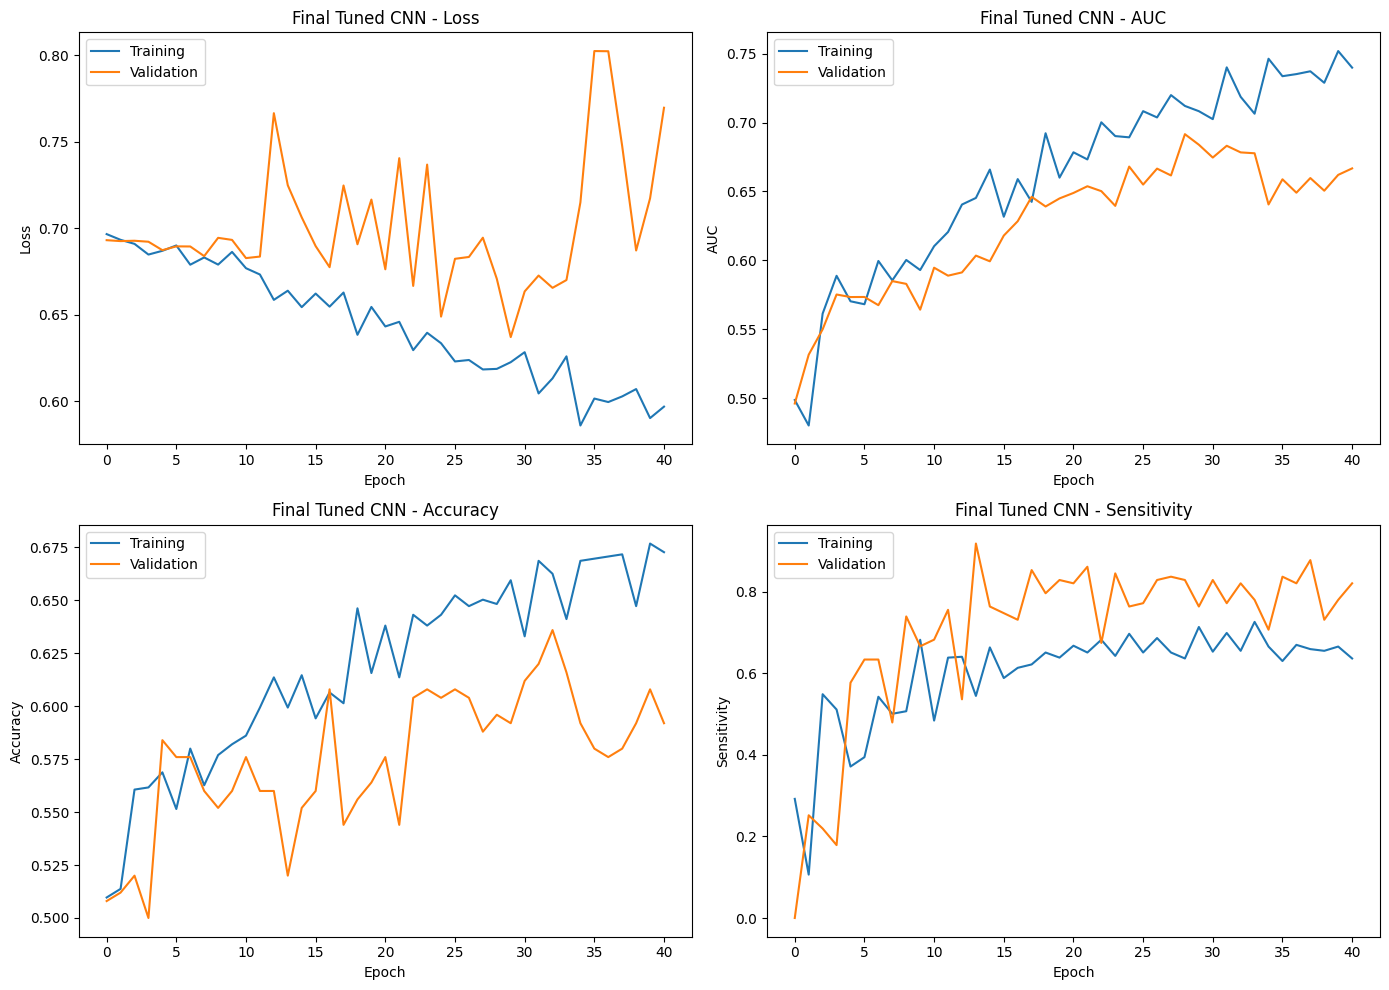

In [ ]:
#Best epoch according to validation AUC
best_epoch = np.argmax(
    final_tuned_history.history['val_auc']
) + 1

print(f"Best epoch based on validation AUC: {best_epoch}")
print(
    f"Best validation AUC: "
    f"{max(final_tuned_history.history['val_auc']):.4f}"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#Loss
axes[0, 0].plot(
    final_tuned_history.history['loss'],
    label='Training'
)
axes[0, 0].plot(
    final_tuned_history.history['val_loss'],
    label='Validation'
)
axes[0, 0].set_title('Final Tuned CNN - Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()

#AUC
axes[0, 1].plot(
    final_tuned_history.history['auc'],
    label='Training'
)
axes[0, 1].plot(
    final_tuned_history.history['val_auc'],
    label='Validation'
)
axes[0, 1].set_title('Final Tuned CNN - AUC')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('AUC')
axes[0, 1].legend()

#Accuracy
axes[1, 0].plot(
    final_tuned_history.history['accuracy'],
    label='Training'
)
axes[1, 0].plot(
    final_tuned_history.history['val_accuracy'],
    label='Validation'
)
axes[1, 0].set_title('Final Tuned CNN - Accuracy')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].legend()

#Sensitivity
axes[1, 1].plot(
    final_tuned_history.history['sensitivity'],
    label='Training'
)
axes[1, 1].plot(
    final_tuned_history.history['val_sensitivity'],
    label='Validation'
)
axes[1, 1].set_title('Final Tuned CNN - Sensitivity')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Sensitivity')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

The final tuned CNN shows improved generalisation compared with the earlier custom CNN configurations. Although a training–validation gap remains, training performance no longer approaches near-perfect AUC and accuracy, while validation AUC generally improves throughout training. This indicates that the tuned configuration, together with data augmentation, reduces the severe overfitting observed in several earlier models.

In [166]:
final_tuned_results = evaluate_validation_model(final_tuned_model, val_ds, "Final Tuned CNN")

Final Tuned CNN - Validation Evaluation
Threshold:   0.5890
Accuracy:    0.6560
AUC:         0.6918
Sensitivity: 0.7398
Specificity: 0.5748
Precision:   0.6276

Confusion Matrix:
[[73 54]
 [32 91]]


The final tuned CNN achieved the highest validation AUC among the custom models at 0.6918. At the validation-derived Youden threshold of 0.5890, sensitivity reached 0.7398, while specificity was 0.5748, indicating a greater tendency to correctly identify malignant cases at the expense of more false-positive predictions. Overall, hyperparameter optimisation produced the strongest custom CNN configuration and provides the final custom-model benchmark for comparison with transfer learning.

### 5.7 Custom CNN Validation Comparison

The validation results from all custom CNN configurations are summarised below using their individually selected Youden thresholds. This provides a direct comparison of the effects of increased model capacity, individual regularisation strategies and hyperparameter optimisation under the same validation framework.

In [89]:
#Custom CNN validation results

custom_cnn_table = pd.DataFrame([
    {
        'Model': model_name,
        'Threshold': result['threshold'],
        'Accuracy': result['accuracy'],
        'AUC': result['auc'],
        'Sensitivity': result['sensitivity'],
        'Specificity': result['specificity'],
        'Precision': result['precision']
    }
    for model_name, result in experiment_1_results
])

custom_cnn_table.round(4)

,Model,Threshold,Accuracy,AUC,Sensitivity,Specificity,Precision
0,Baseline CNN,0.5620,0.632,0.6367,0.5285,0.7323,0.6566
1,Scaled-Up CNN,0.5481,0.652,0.6594,0.5935,0.7087,0.6636
2,Augmentation CNN,0.5887,0.656,0.6608,0.6423,0.6693,0.6529
3,L2-Regularised CNN,0.3884,0.592,0.6086,0.5447,0.6378,0.5929
4,Dropout CNN,0.5587,0.652,0.6494,0.5691,0.7323,0.6731
5,Final Tuned CNN,0.5890,0.656,0.6918,0.7398,0.5748,0.6276


Overall, the final tuned CNN achieved the highest custom-model AUC of 0.6918 and the highest sensitivity of 0.7398. Augmentation produced similar AUC to the scaled-up CNN while improving sensitivity, whereas the tested L2 and dropout configurations did not improve discrimination over the scaled-up architecture.

### 5.8 Statistical Analysis of Custom CNNs

Validation performance is further assessed using patient-cluster bootstrap resampling to account for the fact that multiple mammograms may originate from the same patient. Patients, rather than individual images, are therefore sampled with replacement so that mammograms belonging to the same patient remain grouped during resampling.

A total of 2,000 bootstrap resamples are used to estimate 95% confidence intervals for validation AUC, sensitivity and specificity. AUC is calculated directly from predicted probabilities, while sensitivity and specificity are calculated using each model's fixed validation-derived Youden threshold.

In [92]:
experiment_1_results = [
    ('Baseline CNN', baseline_results),
    ('Scaled-Up CNN', scaled_results),
    ('Augmentation CNN', augmentation_results),
    ('L2-Regularised CNN', l2_results),
    ('Dropout CNN', dropout_results),
    ('Final Tuned CNN', final_tuned_results)
]

#### Patient-Cluster Bootstrap

Patient-level bootstrap resampling is used to estimate uncertainty in the validation metrics. Each bootstrap sample draws patients with replacement and retains all corresponding mammograms, preserving the clustered structure of the dataset.

In [94]:
#Patient-cluster bootstrap for AUC
def patient_cluster_bootstrap_auc(
    y_true,
    y_prob,
    patient_ids,
    n_bootstrap=2000,
    random_state=42
):
    #Convert inputs to arrays
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    patient_ids = np.asarray(patient_ids)

    #Get unique patients and initialise random generator
    unique_patients = np.unique(patient_ids)
    rng = np.random.default_rng(random_state)
    bootstrap_aucs = []

    for _ in range(n_bootstrap):

        sampled_patients = rng.choice(
            unique_patients,
            size=len(unique_patients),
            replace=True
        )

        sampled_indices = np.concatenate([
            np.where(patient_ids == patient)[0]
            for patient in sampled_patients
        ])

        y_boot = y_true[sampled_indices]
        prob_boot = y_prob[sampled_indices]

        if len(np.unique(y_boot)) < 2:
            continue

        #Calculate AUC
        bootstrap_aucs.append(
            roc_auc_score(y_boot, prob_boot)
        )

    #Convert bootstrap results to an array
    bootstrap_aucs = np.asarray(bootstrap_aucs)

    # Calculate 95% confidence interval
    lower, upper = np.percentile(
        bootstrap_aucs,
        [2.5, 97.5]
    )

    return lower, upper, bootstrap_aucs

#### Validation Patient Mapping

Validation predictions are associated with their corresponding patient IDs so that bootstrap resampling can be performed at patient level rather than mammogram level.

In [95]:
#Get patient IDs corresponding to the validation samples
val_patient_ids = patient_groups[val_idx]

print("Validation samples:", len(y_val))
print("Validation patient IDs:", len(val_patient_ids))
print("Unique validation patients:", len(np.unique(val_patient_ids)))

Validation samples: 250
Validation patient IDs: 250
Unique validation patients: 138


In [96]:
#Calculate patient-cluster bootstrap AUC confidence intervals
auc_ci_results = []

for model_name, result in experiment_1_results:

    lower, upper, _ = patient_cluster_bootstrap_auc(
        result['y_true'],
        result['y_prob'],
        val_patient_ids,
        n_bootstrap=2000,
        random_state=42
    )

    auc_ci_results.append({
        'Model': model_name,
        '95% CI Lower': lower,
        '95% CI Upper': upper
    })

#Create AUC confidence interval table
auc_ci_table = pd.DataFrame(auc_ci_results)

auc_ci_table.round(4)

,Model,95% CI Lower,95% CI Upper
0,Baseline CNN,0.5606,0.7143
1,Scaled-Up CNN,0.5824,0.7316
2,Augmentation CNN,0.5806,0.7395
3,L2-Regularised CNN,0.5299,0.6815
4,Dropout CNN,0.5716,0.7214
5,Final Tuned CNN,0.6173,0.7634


The final tuned CNN achieved the highest observed AUC among the custom models and a 95% bootstrap confidence interval of [0.6173, 0.7634]. However, its interval overlaps with those of the other custom CNN configurations, indicating substantial uncertainty in the relative differences between their validation AUCs. The L2-regularised CNN produced the lowest interval, consistent with its lower observed validation AUC.

#### Sensitivity and Specificity Confidence Intervals

Patient-cluster bootstrap resampling is also used to estimate 95% confidence intervals for sensitivity and specificity. Unlike AUC, these metrics depend on the classification threshold, so each model's fixed validation-derived Youden threshold is retained throughout the bootstrap procedure.

Patients are resampled with replacement, and all mammograms belonging to each sampled patient are retained. Sensitivity and specificity are then recalculated for each bootstrap sample using 2,000 resamples.

In [97]:
#Patient-cluster bootstrap for sensitivity and specificity
def patient_cluster_bootstrap_threshold_metrics(
    y_true,
    y_prob,
    patient_ids,
    threshold,
    n_bootstrap=2000,
    random_state=42
):
    #Convert inputs to arrays
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    patient_ids = np.asarray(patient_ids)

    #Get unique patients and initialise random generator
    unique_patients = np.unique(patient_ids)
    rng = np.random.default_rng(random_state)

    bootstrap_sensitivity = []
    bootstrap_specificity = []

    for _ in range(n_bootstrap):

        #Resample patients with replacement
        sampled_patients = rng.choice(
            unique_patients,
            size=len(unique_patients),
            replace=True
        )

        #Retrieve all mammogram indices belonging to sampled patients
        sampled_indices = np.concatenate([
            np.where(patient_ids == patient)[0]
            for patient in sampled_patients
        ])

        #Extract labels and probabilities for the bootstrap sample
        y_boot = y_true[sampled_indices]
        prob_boot = y_prob[sampled_indices]

        #Apply the fixed validation-derived threshold
        pred_boot = (prob_boot >= threshold).astype(int)

        #Calculate confusion matrix
        cm = confusion_matrix(y_boot, pred_boot, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()

        if (tp + fn) > 0:
            bootstrap_sensitivity.append(tp / (tp + fn))

        if (tn + fp) > 0:
            bootstrap_specificity.append(tn / (tn + fp))

    #Calculate 95% confidence intervals
    sensitivity_lower, sensitivity_upper = np.percentile(
        bootstrap_sensitivity, [2.5, 97.5]
    )

    specificity_lower, specificity_upper = np.percentile(
        bootstrap_specificity, [2.5, 97.5]
    )

    return (
        sensitivity_lower,
        sensitivity_upper,
        specificity_lower,
        specificity_upper
    )

In [98]:
#Calculate sensitivity and specificity confidence intervals
threshold_ci_results = []

for model_name, result in experiment_1_results:

    sens_lower, sens_upper, spec_lower, spec_upper = (
        patient_cluster_bootstrap_threshold_metrics(
            result['y_true'],
            result['y_prob'],
            val_patient_ids,
            result['threshold'],
            n_bootstrap=2000,
            random_state=42
        )
    )

    threshold_ci_results.append({
        'Model': model_name,
        'Sensitivity 95% CI Lower': sens_lower,
        'Sensitivity 95% CI Upper': sens_upper,
        'Specificity 95% CI Lower': spec_lower,
        'Specificity 95% CI Upper': spec_upper
    })

#Create confidence interval table
threshold_ci_table = pd.DataFrame(threshold_ci_results)
threshold_ci_table.round(4)

,Model,Sensitivity 95% CI Lower,Sensitivity 95% CI Upper,Specificity 95% CI Lower,Specificity 95% CI Upper
0,Baseline CNN,0.4297,0.6293,0.6467,0.8167
1,Scaled-Up CNN,0.4961,0.6929,0.6209,0.7911
2,Augmentation CNN,0.5391,0.7344,0.5772,0.7542
3,L2-Regularised CNN,0.4380,0.6379,0.5462,0.7308
4,Dropout CNN,0.4722,0.6667,0.6491,0.8087
5,Final Tuned CNN,0.6518,0.8220,0.4797,0.6717


The bootstrap intervals show different sensitivity–specificity trade-offs across the custom CNN configurations. The final tuned CNN achieved the highest sensitivity, with a 95% confidence interval of [0.6518, 0.8220], but its specificity interval was lower at [0.4797, 0.6717]. In contrast, the baseline and dropout CNNs showed higher specificity but lower sensitivity.

These results reinforce that the final tuned CNN shifts the operating balance towards malignant-case detection rather than improving both sensitivity and specificity simultaneously. The relatively wide and overlapping intervals also indicate uncertainty in the threshold-dependent performance estimates.

### 5.9 Final Custom CNN Results

The validation performance of all six custom CNN configurations is consolidated below together with their patient-cluster bootstrap 95% confidence intervals. AUC confidence intervals quantify uncertainty in discrimination, while sensitivity and specificity intervals describe uncertainty at each model's validation-derived Youden threshold.

This table provides the final summary of the custom CNN development stage before comparison with the transfer-learning models.

In [99]:
#Final validation results with 95% CIs

#Pair each model name with its validation results
experiment_1_results = [
    ('Baseline CNN', baseline_results),
    ('Scaled-Up CNN', scaled_results),
    ('Augmentation CNN', augmentation_results),
    ('L2-Regularised CNN', l2_results),
    ('Dropout CNN', dropout_results),
    ('Final Tuned CNN', final_tuned_results)
]

#Create validation results table
experiment_1_table = pd.DataFrame([
    {
        'Model': model_name,
        'Threshold': result['threshold'],
        'Accuracy': result['accuracy'],
        'AUC': result['auc'],
        'Sensitivity': result['sensitivity'],
        'Specificity': result['specificity'],
        'Precision': result['precision']
    }
    for model_name, result in experiment_1_results
])

#Add AUC confidence intervals
experiment_1_final_table = experiment_1_table.merge(
    auc_ci_table[
        ['Model', '95% CI Lower', '95% CI Upper']
    ],
    on='Model'
)

#Add sensitivity and specificity confidence intervals
experiment_1_final_table = experiment_1_final_table.merge(
    threshold_ci_table[
        [
            'Model',
            'Sensitivity 95% CI Lower',
            'Sensitivity 95% CI Upper',
            'Specificity 95% CI Lower',
            'Specificity 95% CI Upper'
        ]
    ],
    on='Model'
)

#Arrange final columns
experiment_1_final_table = experiment_1_final_table[
    [
        'Model',
        'Threshold',
        'Accuracy',
        'AUC',
        '95% CI Lower',
        '95% CI Upper',
        'Sensitivity',
        'Sensitivity 95% CI Lower',
        'Sensitivity 95% CI Upper',
        'Specificity',
        'Specificity 95% CI Lower',
        'Specificity 95% CI Upper',
        'Precision'
    ]
]

experiment_1_final_table.round(4)

,Model,Threshold,Accuracy,AUC,95% CI Lower,95% CI Upper,Sensitivity,Sensitivity 95% CI Lower,Sensitivity 95% CI Upper,Specificity,Specificity 95% CI Lower,Specificity 95% CI Upper,Precision
0,Baseline CNN,0.5620,0.632,0.6367,0.5606,0.7143,0.5285,0.4297,0.6293,0.7323,0.6467,0.8167,0.6566
1,Scaled-Up CNN,0.5481,0.652,0.6594,0.5824,0.7316,0.5935,0.4961,0.6929,0.7087,0.6209,0.7911,0.6636
2,Augmentation CNN,0.5887,0.656,0.6608,0.5806,0.7395,0.6423,0.5391,0.7344,0.6693,0.5772,0.7542,0.6529
3,L2-Regularised CNN,0.3884,0.592,0.6086,0.5299,0.6815,0.5447,0.4380,0.6379,0.6378,0.5462,0.7308,0.5929
4,Dropout CNN,0.5587,0.652,0.6494,0.5716,0.7214,0.5691,0.4722,0.6667,0.7323,0.6491,0.8087,0.6731
5,Final Tuned CNN,0.5890,0.656,0.6918,0.6173,0.7634,0.7398,0.6518,0.8220,0.5748,0.4797,0.6717,0.6276


The final tuned CNN achieved the strongest overall validation discrimination among the custom models, with the highest AUC of 0.6918 and a 95% confidence interval of [0.6173, 0.7634]. It also achieved the highest sensitivity at 0.7398 [0.6518, 0.8220], although this was accompanied by lower specificity of 0.5748 [0.4797, 0.6717].

Across the preceding experiments, increasing model capacity produced a modest improvement over the baseline, while the individual regularisation strategies did not consistently improve discrimination. Hyperparameter optimisation produced the strongest custom CNN configuration, which is therefore carried forward as the custom-model reference for comparison with transfer learning.

#### Paired AUC Comparison

Patient-cluster bootstrap resampling is used to compare the validation AUCs of selected model pairs. Both models are evaluated using the same resampled patients in each iteration, preserving the paired structure of their predictions while accounting for multiple mammograms from the same patient.

For each of 2,000 bootstrap resamples, the difference in AUC between the two models is calculated. The resulting distribution is used to estimate a 95% confidence interval for the paired AUC difference.

In [101]:
#Patient-cluster bootstrap for paired AUC difference
def paired_bootstrap_auc(y_true, prob_a, prob_b, patient_ids,
                         n_bootstrap=2000, random_state=42):

    y_true = np.asarray(y_true).astype(int)
    prob_a = np.asarray(prob_a).flatten()
    prob_b = np.asarray(prob_b).flatten()
    patient_ids = np.asarray(patient_ids)

    unique_patients = np.unique(patient_ids)
    rng = np.random.default_rng(random_state)
    auc_differences = []

    for _ in range(n_bootstrap):
        sampled_patients = rng.choice(
            unique_patients, size=len(unique_patients), replace=True
        )

        sampled_indices = np.concatenate([
            np.where(patient_ids == patient)[0]
            for patient in sampled_patients
        ])

        y_boot = y_true[sampled_indices]

        if len(np.unique(y_boot)) < 2:
            continue

        auc_a = roc_auc_score(y_boot, prob_a[sampled_indices])
        auc_b = roc_auc_score(y_boot, prob_b[sampled_indices])
        auc_differences.append(auc_b - auc_a)

    auc_differences = np.asarray(auc_differences)
    lower, upper = np.percentile(auc_differences, [2.5, 97.5])

    return lower, upper, auc_differences

In [102]:
#Paired AUC comparisons

#Map model names to validation results
results_by_model = dict(experiment_1_results)

comparisons = [
    ('Baseline CNN', 'Scaled-Up CNN'),
    ('Scaled-Up CNN', 'Augmentation CNN'),
    ('Scaled-Up CNN', 'L2-Regularised CNN'),
    ('Scaled-Up CNN', 'Dropout CNN'),
    ('Baseline CNN', 'Final Tuned CNN')
]

paired_auc_results = []

for model_a, model_b in comparisons:

    #Retrieve validation labels and probabilities
    y_true = np.asarray(
        results_by_model[model_a]['y_true']
    ).astype(int)

    prob_a = results_by_model[model_a]['y_prob']
    prob_b = results_by_model[model_b]['y_prob']

    #Calculate AUC
    auc_a = roc_auc_score(y_true, prob_a)
    auc_b = roc_auc_score(y_true, prob_b)

    #Calculate paired patient-cluster bootstrap CI
    lower, upper, differences = paired_bootstrap_auc(
        y_true,
        prob_a,
        prob_b,
        val_patient_ids
    )

    paired_auc_results.append({
        'Comparison': f'{model_a} → {model_b}',
        'AUC A': auc_a,
        'AUC B': auc_b,
        'Difference': auc_b - auc_a,
        '95% CI Lower': lower,
        '95% CI Upper': upper
    })

#Create comparison table
paired_auc_table = pd.DataFrame(paired_auc_results)
paired_auc_table.round(4)

,Comparison,AUC A,AUC B,Difference,95% CI Lower,95% CI Upper
0,Baseline CNN → Scaled-Up CNN,0.6367,0.6594,0.0227,-0.0542,0.0972
1,Scaled-Up CNN → Augmentation CNN,0.6594,0.6608,0.0014,-0.0822,0.0886
2,Scaled-Up CNN → L2-Regularised CNN,0.6594,0.6086,-0.0508,-0.1197,0.0169
3,Scaled-Up CNN → Dropout CNN,0.6594,0.6494,-0.0101,-0.0726,0.0507
4,Baseline CNN → Final Tuned CNN,0.6367,0.6918,0.0551,-0.0144,0.1212


The paired bootstrap comparisons show that none of the evaluated custom CNN modifications produced a statistically clear improvement in validation AUC, as all 95% confidence intervals for the paired AUC differences include zero.

The final tuned CNN showed the largest observed improvement over the baseline, with an AUC increase of 0.0551. However, its paired 95% confidence interval of [-0.0144, 0.1212] still included zero, indicating uncertainty around this improvement. Similarly, the small differences between the scaled-up CNN and the individual regularisation variants were not clearly distinguishable within the bootstrap uncertainty.

#### To complement the paired AUC confidence intervals, two-sided bootstrap p-values are calculated from the distribution of paired AUC differences.

In [103]:
#Calculate p-values for paired AUC comparisons
p_value_results = []

for model_a, model_b in comparisons:

    #Retrieve validation labels and probabilities
    y_true = np.asarray(
        results_by_model[model_a]['y_true']
    ).astype(int)

    prob_a = results_by_model[model_a]['y_prob']
    prob_b = results_by_model[model_b]['y_prob']

    #Perform paired patient-cluster bootstrap
    lower, upper, differences = paired_bootstrap_auc(
        y_true,
        prob_a,
        prob_b,
        val_patient_ids
    )

    #Calculate two-sided bootstrap p-value
    p_value = 2 * min(
        np.mean(differences <= 0),
        np.mean(differences >= 0)
    )
    p_value = min(p_value, 1.0)

    #Store comparison result
    p_value_results.append({
        'Comparison': f'{model_a} → {model_b}',
        'p-value': p_value
    })

#Create p-value table
p_value_table = pd.DataFrame(p_value_results)
p_value_table.round(4)

,Comparison,p-value
0,Baseline CNN → Scaled-Up CNN,0.592
1,Scaled-Up CNN → Augmentation CNN,0.979
2,Scaled-Up CNN → L2-Regularised CNN,0.124
3,Scaled-Up CNN → Dropout CNN,0.733
4,Baseline CNN → Final Tuned CNN,0.112


None of the paired custom CNN comparisons reached statistical significance at the 0.05 level, consistent with the 95% confidence intervals for the paired AUC differences all including zero. The final tuned CNN showed the largest observed improvement over the baseline, increasing AUC from 0.6367 to 0.6918, but this difference was not statistically significant.

Similarly, increasing model capacity and applying the individual regularisation strategies did not produce statistically significant changes in AUC. These results indicate that although the final tuned CNN achieved the highest observed validation AUC, the available validation data do not provide sufficient evidence that its discrimination was significantly better than the baseline.

In [104]:
#Final paired AUC comparison table

experiment_1_comparisons = paired_auc_table.merge(
    p_value_table, on='Comparison'
)

experiment_1_comparisons = experiment_1_comparisons.rename(columns={
    'AUC A': 'AUC Model A',
    'AUC B': 'AUC Model B',
    'Difference': 'AUC Difference'
})

experiment_1_comparisons.round(4)

,Comparison,AUC Model A,AUC Model B,AUC Difference,95% CI Lower,95% CI Upper,p-value
0,Baseline CNN → Scaled-Up CNN,0.6367,0.6594,0.0227,-0.0542,0.0972,0.592
1,Scaled-Up CNN → Augmentation CNN,0.6594,0.6608,0.0014,-0.0822,0.0886,0.979
2,Scaled-Up CNN → L2-Regularised CNN,0.6594,0.6086,-0.0508,-0.1197,0.0169,0.124
3,Scaled-Up CNN → Dropout CNN,0.6594,0.6494,-0.0101,-0.0726,0.0507,0.733
4,Baseline CNN → Final Tuned CNN,0.6367,0.6918,0.0551,-0.0144,0.1212,0.112


None of the paired custom CNN comparisons reached statistical significance at the 0.05 level, with all 95% confidence intervals for the AUC differences including zero. The final tuned CNN showed the largest observed improvement, increasing AUC from 0.6367 to 0.6918 relative to the baseline (AUC = 0.0551, 95% CI [-0.0144, 0.1212], p = 0.112).

The remaining architectural and regularisation comparisons similarly showed no statistically significant differences. Therefore, although the final tuned CNN achieved the highest observed validation AUC among the custom models, the paired analysis does not provide sufficient evidence that its AUC was significantly higher than the baseline.

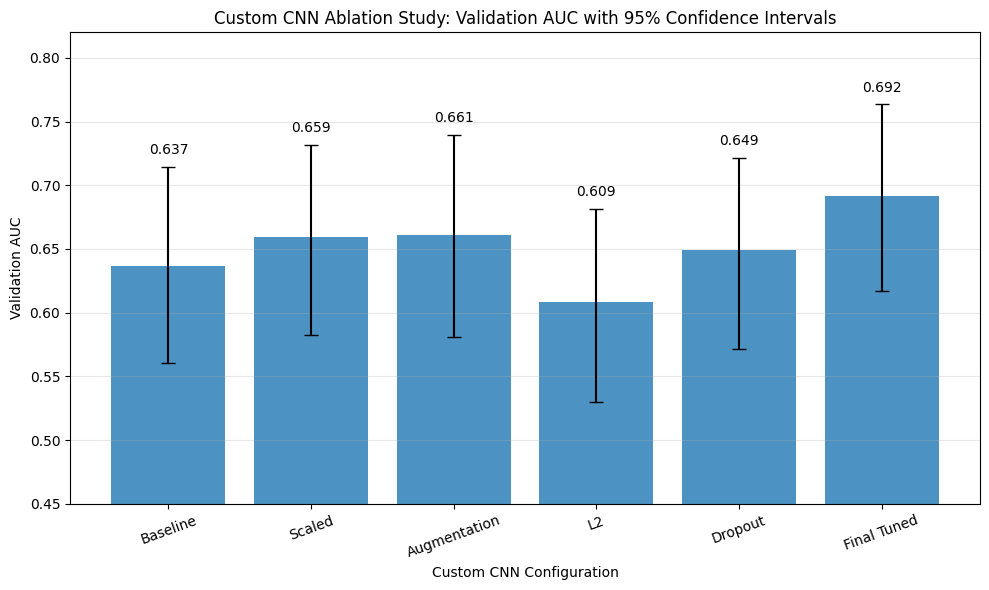

In [105]:
#AUC comparison with 95% confidence intervals

plot_data = experiment_1_final_table.copy()

models = ['Baseline', 'Scaled', 'Augmentation', 'L2', 'Dropout', 'Final Tuned']
auc = plot_data['AUC'].values
lower = auc - plot_data['95% CI Lower'].values
upper = plot_data['95% CI Upper'].values - auc

plt.figure(figsize=(10, 6))
bars = plt.bar(models, auc, yerr=[lower, upper], capsize=5, alpha=0.8)

#Display AUC values above confidence intervals
for bar, value, error in zip(bars, auc, upper):
    plt.text(bar.get_x() + bar.get_width()/2, value + error + 0.01,
             f'{value:.3f}', ha='center')

plt.ylabel('Validation AUC')
plt.xlabel('Custom CNN Configuration')
plt.title('Custom CNN Ablation Study: Validation AUC with 95% Confidence Intervals')
plt.ylim(0.45, 0.82)
plt.xticks(rotation=20)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

The final tuned CNN achieved the highest validation AUC of 0.6918, although the confidence intervals overlap across CNN configurations.

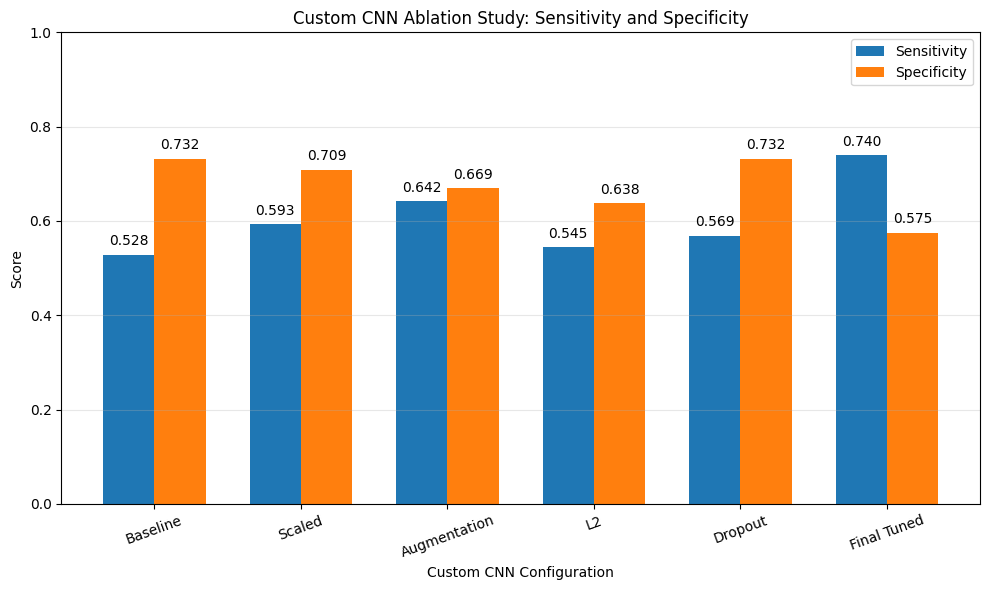

In [106]:
#Sensitivity and specificity comparison

plot_data = experiment_1_final_table.copy()

models = ['Baseline', 'Scaled', 'Augmentation', 'L2', 'Dropout', 'Final Tuned']
sensitivity = plot_data['Sensitivity'].values
specificity = plot_data['Specificity'].values

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 6))

sens_bars = plt.bar(x - width/2, sensitivity, width, label='Sensitivity')
spec_bars = plt.bar(x + width/2, specificity, width, label='Specificity')

#Display metric values above bars
for bars in [sens_bars, spec_bars]:
    for bar in bars:
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{bar.get_height():.3f}', ha='center')

plt.ylabel('Score')
plt.xlabel('Custom CNN Configuration')
plt.title('Custom CNN Ablation Study: Sensitivity and Specificity')
plt.xticks(x, models, rotation=20)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

The final tuned CNN achieved the highest sensitvity of 0.7398 but with lower specificty of 0.5748, demonstraing a shift toeards malignant-case detection.

## 6 Transfer Learning

The second experimental stage evaluates transfer learning using VGG16 and ResNet50 pretrained on ImageNet. Both models use the same patient-grouped training and validation partitions as the custom CNN experiments, while applying their architecture-specific preprocessing.

Each model is first trained with the pretrained convolutional base frozen before selected deeper layers are unfrozen for fine-tuning at a lower learning rate.

### 6.1 VGG16

VGG16 required Image-Net Specific input preprocessing rather than the [0, 1] normalisation used foe the custom CNNs. Images are therefore resized to 224 x 224 pixels and processed using the VGG16 preprocess_input function before being passed to the model.

In [107]:
#Import vgg processing
from tensorflow.keras.applications.vgg16 import preprocess_input

def preprocess_vgg16(image, label):

    image = tf.image.resize(image, (img_size, img_size))
    image = tf.cast(image, tf.float32)

    #VGG16 ImageNet preprocessing
    image = preprocess_input(image)
    label = tf.cast(label, tf.float32)

    return image, label

#### VGG16 Input Pipeline

A separate input pipeline is constructed for VGG16 using the architecture-specific preprocessing defined above. The training dataset is shuffled, while the validation dataset remains unshuffled for consistent evaluation.

In [108]:
#Make VGG16 pipeline
def build_vgg16_pipeline(paths, labels, shuffle=False):

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.map(preprocess_vgg16, num_parallel_calls=AUTOTUNE )
    ds = ds.cache()

    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)

    return ds

In [110]:
#Create datasets
vgg_train_ds = build_vgg16_pipeline(
    X_train,
    y_train,
    shuffle=True
)

vgg_val_ds = build_vgg16_pipeline(
    X_val,
    y_val
)

print("Cached VGG16 datasets created successfully.")

Cached VGG16 datasets created successfully.


#### VGG16 Model Architecture

VGG16 is initialised with ImageNet-pretrained weights and its convolutional backbone is initially frozen. A new classification head consisting of global average pooling, a 128-unit dense layer, dropout of 0.5 and a sigmoid output layer is added for binary classification.

The model is compiled using Adam with a learning rate of 1 x 10⁻⁴ and binary cross-entropy loss.

In [112]:
from tensorflow.keras.applications import VGG16

np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

vgg_base = VGG16(weights='imagenet', include_top=False,
                 input_shape=(img_size, img_size, 3))

#Freeze entire pretrained backbone
vgg_base.trainable = False

def build_vgg16_model():
    inputs = layers.Input(shape=(img_size, img_size, 3))
    x = vgg_base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    return tf.keras.Model(inputs, outputs, name='VGG16_Transfer_Learning')

vgg_model = build_vgg16_model()
vgg_model.summary()

#Compile model
vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=1.0),
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Recall(name='sensitivity'),
        tf.keras.metrics.Precision(name='precision')
    ]
)

print("VGG16 model compiled successfully.")

Model: "VGG16_Transfer_Learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

VGG16 model compiled successfully.


#### Model configurations and callabcks

In [ ]:
#Define callbacks
vgg_phase1_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor='val_auc',
        mode='max',
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(
            save_dir,
            'best_vgg16_phase1.keras'
        ),
        monitor='val_auc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        os.path.join(
            save_dir,
            'vgg16_phase1_training_log.csv'
        )
    )
]

print("VGG16 Phase 1 callbacks created.")

VGG16 Phase 1 callbacks created.


#### Phase 1 Model Training

In [ ]:
# Phase 1 training

vgg_phase1_history = vgg_model.fit(
    vgg_train_ds,
    validation_data=vgg_val_ds,
    epochs=50,
    callbacks=vgg_phase1_callbacks,
    verbose=1
)

print("VGG16 phase 1 training complete")

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step - accuracy: 0.5157 - auc: 0.5056 - loss: 1.4694 - precision: 0.5131 - sensitivity: 0.3663
Epoch 1: val_auc improved from None to 0.52084, saving model to /content/drive/MyDrive/CBIS-DDSM/best_vgg16_phase1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_vgg16_phase1.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 96s 871ms/step - accuracy: 0.5250 - auc: 0.5233 - loss: 1.3181 - precision: 0.5148 - sensitivity: 0.4718 - val_accuracy: 0.5240 - val_auc: 0.5208 - val_loss: 0.8060 - val_precision: 0.5130 - val_sensitivity: 0.6423
Epoch 2/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.5047 - auc: 0.5120 - loss: 1.1645 - precision: 0.4715 - sensitivity: 0.4984
Epoch 2: val_auc improved from 0.52084 to 0.56251, saving model to /content/drive/MyDrive/CBIS-DDSM/best_vgg16_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_vgg16_phase1.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 54s 221ms/step - a

#### Phase 2: Fine-Tuning

For the second training phase, the VGG16 backbone is partially unfrozen. Layers in convolutional blocks 4 and 5 are made trainable, while the earlier layers remain frozen to preserve lower-level pretrained features.

In [113]:
#Unfreeze VGG16 blocks 4 and 5
vgg_base.trainable = True

for layer in vgg_base.layers:
    if layer.name.startswith('block4') or layer.name.startswith('block5'):
        layer.trainable = True
    else:
        layer.trainable = False

print("VGG16 layer trainability:\n")

for layer in vgg_base.layers:
    print(f"{layer.name:20s} Trainable: {layer.trainable}")

VGG16 layer trainability:

input_layer_11       Trainable: False
block1_conv1         Trainable: False
block1_conv2         Trainable: False
block1_pool          Trainable: False
block2_conv1         Trainable: False
block2_conv2         Trainable: False
block2_pool          Trainable: False
block3_conv1         Trainable: False
block3_conv2         Trainable: False
block3_conv3         Trainable: False
block3_pool          Trainable: False
block4_conv1         Trainable: True
block4_conv2         Trainable: True
block4_conv3         Trainable: True
block4_pool          Trainable: True
block5_conv1         Trainable: True
block5_conv2         Trainable: True
block5_conv3         Trainable: True
block5_pool          Trainable: True


#### Compile Phase 2

In [ ]:
#Compie model for phase 2
vgg_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5,
        clipnorm=1.0
    ),

    loss='binary_crossentropy',

    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Recall(name='sensitivity'),
        tf.keras.metrics.Precision(name='precision')
    ]
)

print("VGG16 Phase 2 compiled successfully.")

VGG16 Phase 2 compiled successfully.


In [ ]:
vgg_model.summary()

print(
    "\nTrainable parameters:",
    sum(
        np.prod(v.shape)
        for v in vgg_model.trainable_weights
    )
)

print(
    "Non-trainable parameters:",
    sum(
        np.prod(v.shape)
        for v in vgg_model.non_trainable_weights
    )
)

Model: "VGG16_Transfer_Learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 13,044,993 (49.76 MB)

 Non-trainable params: 1,735,488 (6.62 MB)


Trainable parameters: 13044993
Non-trainable parameters: 1735488


#### Phase 2 Model Configurations and Callbacks

In [ ]:
#Define callabacks
gg_phase2_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_auc',
        mode='max',
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(
            save_dir,
            'best_vgg16_finetuned.keras'
        ),
        monitor='val_auc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        os.path.join(
            save_dir,
            'vgg16_phase2_training_log.csv'
        )
    )
]

print("VGG16 Phase 2 callbacks created.")

VGG16 Phase 2 callbacks created.


#### Phase 2 Model Training

In [ ]:
vgg_phase2_history = vgg_model.fit(
    vgg_train_ds,
    validation_data=vgg_val_ds,
    epochs=50,
    callbacks=vgg_phase2_callbacks,
    verbose=1
)

print("VGG16 phase 2 training complete")

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 397ms/step - accuracy: 0.8581 - auc: 0.9260 - loss: 0.3543 - precision: 0.8594 - sensitivity: 0.8472
Epoch 1: val_auc improved from None to 0.74384, saving model to /content/drive/MyDrive/CBIS-DDSM/best_vgg16_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_vgg16_finetuned.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 25s 611ms/step - accuracy: 0.8502 - auc: 0.9256 - loss: 0.3535 - precision: 0.8458 - sensitivity: 0.8476 - val_accuracy: 0.6640 - val_auc: 0.7438 - val_loss: 0.6882 - val_precision: 0.6291 - val_sensitivity: 0.7724
Epoch 2/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - accuracy: 0.8824 - auc: 0.9590 - loss: 0.2803 - precision: 0.8509 - sensitivity: 0.9064
Epoch 2: val_auc improved from 0.74384 to 0.77021, saving model to /content/drive/MyDrive/CBIS-DDSM/best_vgg16_finetuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_vgg16_finetuned.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 29s 33

#### Training Curves

In [ ]:
#Combine Phase 1 and Phase 2 histories

phase1_epochs = len(vgg_phase1_history.history['loss'])
phase2_epochs = len(vgg_phase2_history.history['loss'])

#Combine metrics
loss = (vgg_phase1_history.history['loss'] + vgg_phase2_history.history['loss'])
val_loss = (vgg_phase1_history.history['val_loss'] + vgg_phase2_history.history['val_loss'])
auc = (vgg_phase1_history.history['auc'] + vgg_phase2_history.history['auc'])
val_auc = (vgg_phase1_history.history['val_auc'] + vgg_phase2_history.history['val_auc'])
accuracy = (vgg_phase1_history.history['accuracy'] + vgg_phase2_history.history['accuracy'])
val_accuracy = (vgg_phase1_history.history['val_accuracy'] + vgg_phase2_history.history['val_accuracy'])
sensitivity = (vgg_phase1_history.history['sensitivity'] + vgg_phase2_history.history['sensitivity'])
val_sensitivity = (vgg_phase1_history.history['val_sensitivity'] + vgg_phase2_history.history['val_sensitivity'])

Phase 1 epochs: 50
Phase 2 epochs: 22
Best epoch based on validation AUC: 60
Best validation AUC: 0.7766


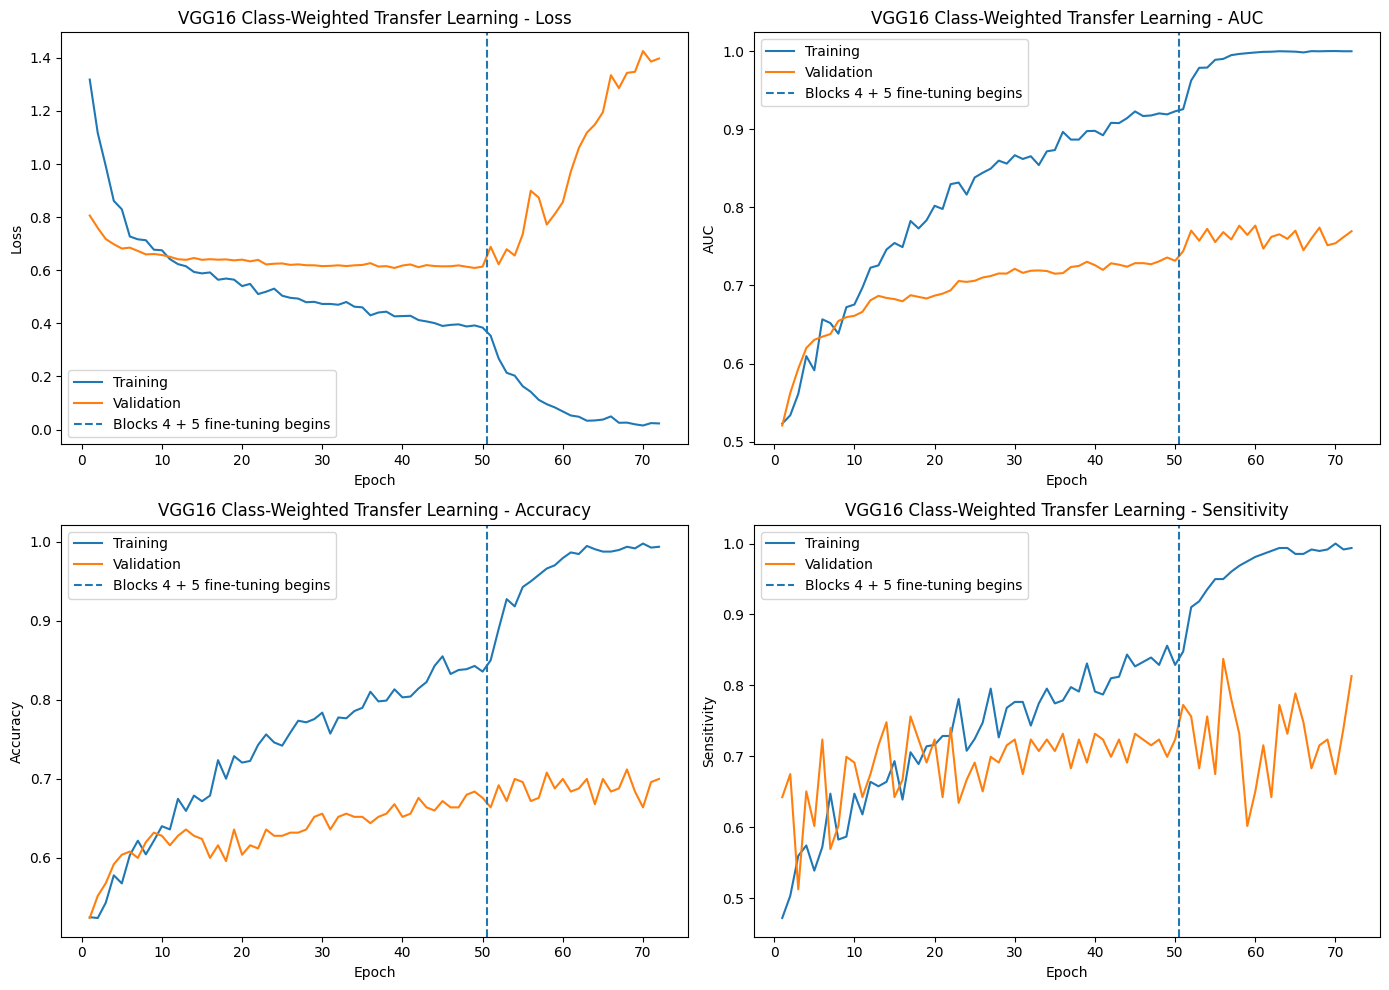

In [ ]:
# Epoch numbers
epochs = range(
    1,
    phase1_epochs + phase2_epochs + 1
)

#Phase 2 begins after Phase 1
fine_tune_start = phase1_epochs + 0.5

#Best epoch according to validation AUC
best_epoch = np.argmax(val_auc) + 1
print(f"Phase 1 epochs: {phase1_epochs}")
print(f"Phase 2 epochs: {phase2_epochs}")
print(f"Best epoch based on validation AUC: {best_epoch}")
print(f"Best validation AUC: {max(val_auc):.4f}")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#Loss
axes[0, 0].plot(epochs, loss, label='Training')
axes[0, 0].plot(epochs, val_loss, label='Validation')
axes[0, 0].axvline(
    fine_tune_start,
    linestyle='--',
    label='Blocks 4 + 5 fine-tuning begins'
)
axes[0, 0].set_title(
    'VGG16 Class-Weighted Transfer Learning - Loss'
)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()

#AUC
axes[0, 1].plot(epochs, auc, label='Training')
axes[0, 1].plot(epochs, val_auc, label='Validation')
axes[0, 1].axvline(
    fine_tune_start,
    linestyle='--',
    label='Blocks 4 + 5 fine-tuning begins'
)
axes[0, 1].set_title(
    'VGG16 Class-Weighted Transfer Learning - AUC'
)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('AUC')
axes[0, 1].legend()

#Accuracy
axes[1, 0].plot(epochs, accuracy, label='Training')
axes[1, 0].plot(epochs, val_accuracy, label='Validation')
axes[1, 0].axvline(
    fine_tune_start,
    linestyle='--',
    label='Blocks 4 + 5 fine-tuning begins'
)
axes[1, 0].set_title(
    'VGG16 Class-Weighted Transfer Learning - Accuracy'
)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].legend()

#Sensitivity
axes[1, 1].plot(
    epochs,
    sensitivity,
    label='Training'
)
axes[1, 1].plot(
    epochs,
    val_sensitivity,
    label='Validation'
)
axes[1, 1].axvline(
    fine_tune_start,
    linestyle='--',
    label='Blocks 4 + 5 fine-tuning begins'
)
axes[1, 1].set_title(
    'VGG16 Class-Weighted Transfer Learning - Sensitivity'
)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Sensitivity')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

The training curves show increasing overfitting, particularly after fine-tuning begins, as training performance continues to improve while validation performance remains comparatively stable. Nevertheless, fine-tuning produces a modest improvement in validation AUC, reaching its best value during the second training phase.

In [116]:
#Evaluate on validation set
vgg16_results = evaluate_validation_model(saved_vgg16_model, vgg_val_ds, 'VGG16')

VGG16 - Validation Evaluation
Threshold:   0.2823
Accuracy:    0.7160
AUC:         0.7792
Sensitivity: 0.7886
Specificity: 0.6457
Precision:   0.6831

Confusion Matrix:
[[82 45]
 [26 97]]


VGG16 achieved a validation AUC of 0.7792, substantially exceeding the custom CNN results. At the validation-derived Youden threshold of 0.2823, the model achieved a sensitivity of 0.7886 and specificity of 0.6457, demonstrating stronger malignant-case detection while maintaining moderate specificity.

### 6.2 ResNet50

ResNet50 is evaluated as the second ImageNet-pretrained transfer-learning architecture. Images are resized to 224 x 224 pixels and processed using the ResNet50-specific preprocess_input function.

#### ResNet50 Input Pipeline

A separate input pipeline applies the ResNet50-specific preprocessing to the same patient-grouped training and validation partitions. The training dataset is shuffled, while the validation dataset remains unshuffled for consistent evaluation.

In [64]:
from tensorflow.keras.applications.resnet50 import preprocess_input

def preprocess_resnet50(image, label):
    image = tf.image.resize(image, (img_size, img_size))
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)
    label = tf.cast(label,tf.float32)

    return image, label

In [65]:
def build_resnet50_pipeline(
    paths,
    labels,
    shuffle=False
):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.map(preprocess_resnet50, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()

    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)

    return ds

In [68]:
resnet_train_ds = build_resnet50_pipeline(
    X_train,
    y_train,
    shuffle=True
)

resnet_val_ds = build_resnet50_pipeline(
    X_val,
    y_val
)

print("Cached ResNet50 datasets built successfully.")

Cached ResNet50 datasets built successfully.


In [ ]:
for images, labels in resnet_train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:",
          tf.reduce_min(images).numpy(),
          tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: -123.68 151.061


#### ResNet50 Model Architecture

ResNet50 is initialised with ImageNet-pretrained weights and its convolutional backbone is frozen for the first training phase. The classification head consists of global average pooling, a 128-unit dense layer, dropout of 0.5 and a sigmoid output layer.

The model is compiled using Adam with a learning rate of 1 x 10⁻⁴ and binary cross-entropy loss.

In [69]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

#Set seed
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

resnet_base = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(img_size, img_size, 3)
)

#Freeze the entire pretrained backbone for Phase 1
resnet_base.trainable = False


def resnet50_model():
    inputs = layers.Input(shape=(img_size, img_size, 3))
    x = resnet_base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = models.Model(inputs, outputs, name='ResNet50_Transfer_Learning')

    return model


resnet_model = resnet50_model()
resnet_model.summary()

resnet_model.compile(
    optimizer=Adam(
        learning_rate=1e-4,
        clipnorm=1.0
    ),
    loss='binary_crossentropy',
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='sensitivity')
    ]
)

print("ResNet50 model compiled successfully.")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "ResNet50_Transfer_Learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

ResNet50 model compiled successfully.


#### Phase 1 Model Configurations and Callabcks

In [ ]:
#Define callbacks
resnet_phase1_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_auc',
        mode='max',
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(
            save_dir,
            'best_resnet50_phase1.keras'
        ),
        monitor='val_auc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        os.path.join(
            save_dir,
            'resnet50_phase1_training_log.csv'
        )
    )
]

print("ResNet50 Phase 1 callbacks created.")

ResNet50 Phase 1 callbacks created.


#### Phase 1 Model Training

In [ ]:
resnet_history_phase1 = resnet_model.fit(
    resnet_train_ds,
    validation_data=resnet_val_ds,
    epochs=50,
    callbacks=resnet_phase1_callbacks,
    verbose=1
)

print("ResNet50 Phase 1 training complete")

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 297ms/step - accuracy: 0.4606 - auc: 0.4616 - loss: 0.8475 - precision: 0.4533 - sensitivity: 0.4570
Epoch 1: val_auc improved from None to 0.60624, saving model to /content/drive/MyDrive/CBIS-DDSM/best_resnet50_phase1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_resnet50_phase1.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 112s 1s/step - accuracy: 0.4924 - auc: 0.4882 - loss: 0.8115 - precision: 0.4798 - sensitivity: 0.4718 - val_accuracy: 0.5720 - val_auc: 0.6062 - val_loss: 0.6735 - val_precision: 0.5702 - val_sensitivity: 0.5285
Epoch 2/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.5702 - auc: 0.5824 - loss: 0.7109 - precision: 0.5386 - sensitivity: 0.5550
Epoch 2: val_auc improved from 0.60624 to 0.66654, saving model to /content/drive/MyDrive/CBIS-DDSM/best_resnet50_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_resnet50_phase1.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 5s 178ms/

#### Phase 2: Fine-Tuning

In [ ]:
#Unfreeze blocks 4 and 5
resnet_base = resnet_model.get_layer('resnet50')
resnet_base.trainable = True

for layer in resnet_base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
    elif (
        layer.name.startswith('conv4_') or
        layer.name.startswith('conv5_')
    ):
        layer.trainable = True
    else:
        layer.trainable = False


In [ ]:
trainable_params = np.sum([
    np.prod(v.shape)
    for v in resnet_model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in resnet_model.non_trainable_weights
])

print(f"Trainable parameters: {trainable_params:,}")
print(f"Non-trainable parameters: {non_trainable_params:,}")
print("\nTrainable ResNet50 backbone layers:")

for layer in resnet_base.layers:
    if layer.trainable:
        print(layer.name)

Trainable parameters: 22,304,001
Non-trainable parameters: 1,546,112

Trainable ResNet50 backbone layers:
conv4_block1_1_conv
conv4_block1_1_relu
conv4_block1_2_conv
conv4_block1_2_relu
conv4_block1_0_conv
conv4_block1_3_conv
conv4_block1_add
conv4_block1_out
conv4_block2_1_conv
conv4_block2_1_relu
conv4_block2_2_conv
conv4_block2_2_relu
conv4_block2_3_conv
conv4_block2_add
conv4_block2_out
conv4_block3_1_conv
conv4_block3_1_relu
conv4_block3_2_conv
conv4_block3_2_relu
conv4_block3_3_conv
conv4_block3_add
conv4_block3_out
conv4_block4_1_conv
conv4_block4_1_relu
conv4_block4_2_conv
conv4_block4_2_relu
conv4_block4_3_conv
conv4_block4_add
conv4_block4_out
conv4_block5_1_conv
conv4_block5_1_relu
conv4_block5_2_conv
conv4_block5_2_relu
conv4_block5_3_conv
conv4_block5_add
conv4_block5_out
conv4_block6_1_conv
conv4_block6_1_relu
conv4_block6_2_conv
conv4_block6_2_relu
conv4_block6_3_conv
conv4_block6_add
conv4_block6_out
conv5_block1_1_conv
conv5_block1_1_relu
conv5_block1_2_conv
conv5_bloc

#### Compile Phase 2 Model

In [ ]:
#Compile pahse 2
resnet_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5,
        clipnorm=1.0
    ),

    loss='binary_crossentropy',

    metrics=[
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Recall(name='sensitivity'),
        tf.keras.metrics.Precision(name='precision')
    ]
)

print("ResNet50 Phase 2 compiled successfully.")

ResNet50 Phase 2 compiled successfully.


#### Phase 2 Model Configuration and Callbacks

In [ ]:
#Define callbacks
resnet_phase2_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_auc',
        mode='max',
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(
            save_dir,
            'best_resnet50_finetuned.keras'
        ),
        monitor='val_auc',
        mode='max',
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        os.path.join(
            save_dir,
            'resnet50_phase2_training_log.csv'
        )
    )
]

print("ResNet50 Phase 2 callbacks created.")

ResNet50 Phase 2 callbacks created.


#### Phase 2 Model Training

In [ ]:
resnet_history_phase2 = resnet_model.fit(
    resnet_train_ds,
    validation_data=resnet_val_ds,
    epochs=50,
    callbacks=resnet_phase2_callbacks,
    verbose=1
)

print("ResNet50 Phase 2 training complete")

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 608ms/step - accuracy: 0.7485 - auc: 0.8052 - loss: 0.5398 - precision: 0.7484 - sensitivity: 0.7552
Epoch 1: val_auc improved from None to 0.74845, saving model to /content/drive/MyDrive/CBIS-DDSM/best_resnet50_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_resnet50_finetuned.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 57s 959ms/step - accuracy: 0.7268 - auc: 0.8013 - loss: 0.5408 - precision: 0.7149 - sensitivity: 0.7328 - val_accuracy: 0.6840 - val_auc: 0.7484 - val_loss: 0.5890 - val_precision: 0.6833 - val_sensitivity: 0.6667
Epoch 2/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.8021 - auc: 0.8811 - loss: 0.4465 - precision: 0.8159 - sensitivity: 0.7979
Epoch 2: val_auc improved from 0.74845 to 0.75232, saving model to /content/drive/MyDrive/CBIS-DDSM/best_resnet50_finetuned.keras

Epoch 2: finished saving model to /content/drive/MyDrive/CBIS-DDSM/best_resnet50_finetuned.keras
31/31 ━━━━━━━━━━━━━━━

#### Training Curves

In [ ]:
#Combine Phase 1 and Phase 2 histories
phase1_epochs = len(resnet_history_phase1.history['loss'])
phase2_epochs = len(resnet_history_phase2.history['loss'])

#Combine metrics
loss = resnet_history_phase1.history['loss'] + resnet_history_phase2.history['loss']
val_loss = resnet_history_phase1.history['val_loss'] + resnet_history_phase2.history['val_loss']
auc = resnet_history_phase1.history['auc'] + resnet_history_phase2.history['auc']
val_auc = resnet_history_phase1.history['val_auc'] + resnet_history_phase2.history['val_auc']
accuracy = resnet_history_phase1.history['accuracy'] + resnet_history_phase2.history['accuracy']
val_accuracy = resnet_history_phase1.history['val_accuracy'] + resnet_history_phase2.history['val_accuracy']
sensitivity = resnet_history_phase1.history['sensitivity'] + resnet_history_phase2.history['sensitivity']
val_sensitivity = resnet_history_phase1.history['val_sensitivity'] + resnet_history_phase2.history['val_sensitivity']

Phase 1 epochs: 24
Phase 2 epochs: 16
Best epoch based on validation AUC: 28
Best validation AUC: 0.7863


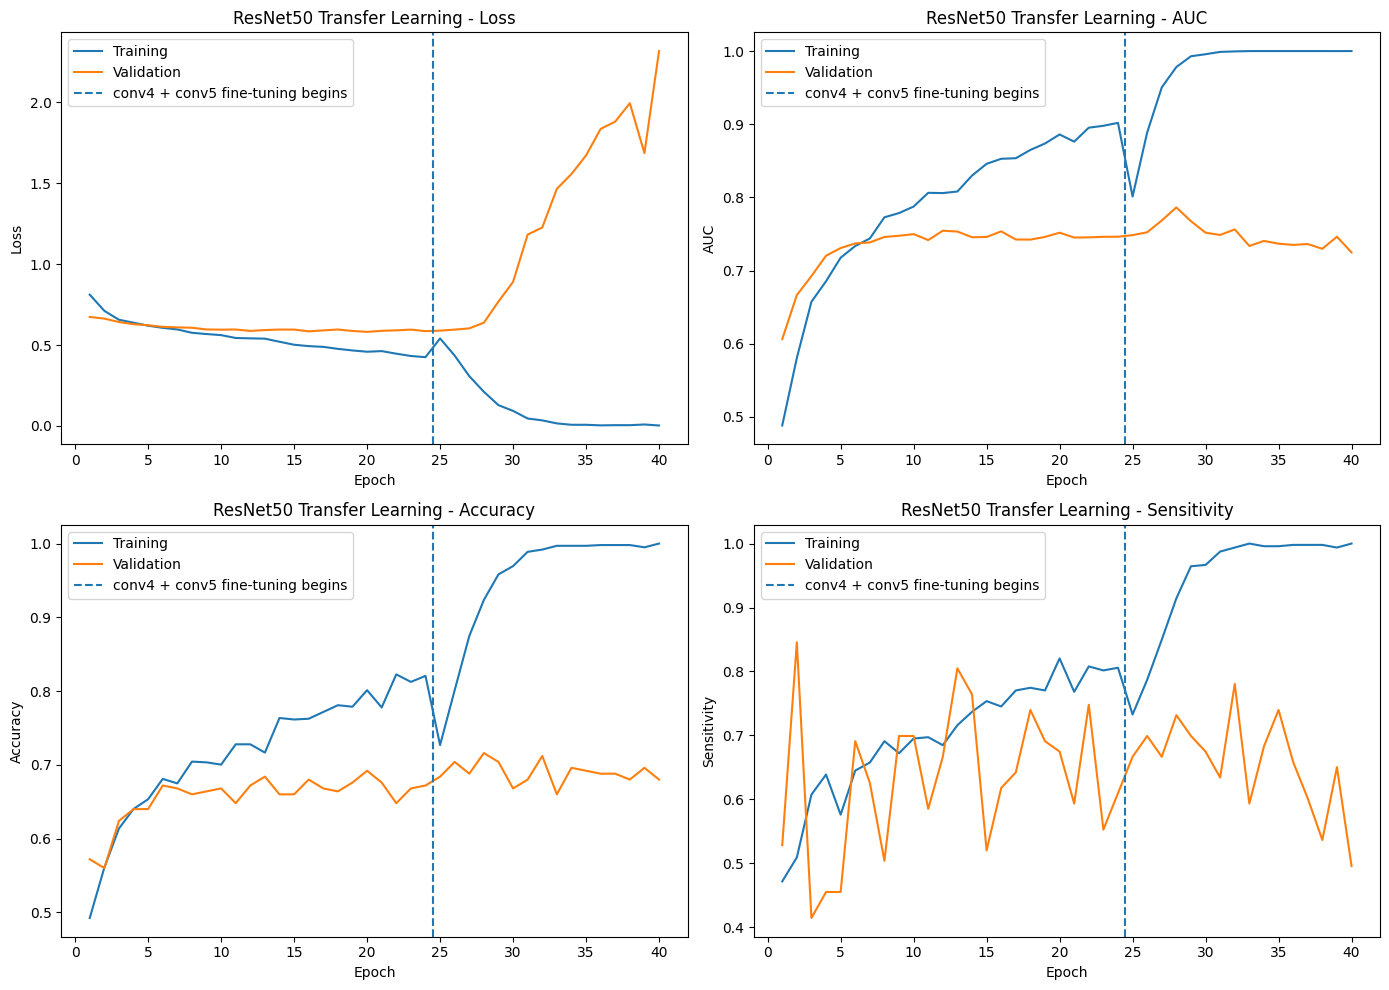

In [ ]:
#Epoch numbers
epochs = range(
    1,
    phase1_epochs + phase2_epochs + 1
)

#Phase 2 begins after Phase 1
fine_tune_start = phase1_epochs + 0.5

#Best epoch according to validation AUC
best_epoch = np.argmax(val_auc) + 1
print(f"Phase 1 epochs: {phase1_epochs}")
print(f"Phase 2 epochs: {phase2_epochs}")
print(f"Best epoch based on validation AUC: {best_epoch}")
print(f"Best validation AUC: {max(val_auc):.4f}")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

#Loss
axes[0, 0].plot(epochs, loss, label='Training')
axes[0, 0].plot(epochs, val_loss, label='Validation')
axes[0, 0].axvline(
    fine_tune_start,
    linestyle='--',
    label='conv4 + conv5 fine-tuning begins'
)
axes[0, 0].set_title(
    'ResNet50 Transfer Learning - Loss'
)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()

#AUC
axes[0, 1].plot(epochs, auc, label='Training')
axes[0, 1].plot(epochs, val_auc, label='Validation')
axes[0, 1].axvline(
    fine_tune_start,
    linestyle='--',
    label='conv4 + conv5 fine-tuning begins'
)
axes[0, 1].set_title(
    'ResNet50 Transfer Learning - AUC'
)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('AUC')
axes[0, 1].legend()

#Accuracy
axes[1, 0].plot(epochs, accuracy, label='Training')
axes[1, 0].plot(epochs, val_accuracy, label='Validation')
axes[1, 0].axvline(
    fine_tune_start,
    linestyle='--',
    label='conv4 + conv5 fine-tuning begins'
)
axes[1, 0].set_title(
    'ResNet50 Transfer Learning - Accuracy'
)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].legend()

#Sensitivity
axes[1, 1].plot(
    epochs,
    sensitivity,
    label='Training'
)
axes[1, 1].plot(
    epochs,
    val_sensitivity,
    label='Validation'
)
axes[1, 1].axvline(
    fine_tune_start,
    linestyle='--',
    label='conv4 + conv5 fine-tuning begins'
)
axes[1, 1].set_title(
    'ResNet50 Transfer Learning - Sensitivity'
)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Sensitivity')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

The training curves show increasing overfitting, particularly after fine-tuning begins, as training performance approaches near-perfect levels while validation performance does not improve consistently. Validation AUC reaches its highest value during early fine-tuning before subsequently declining.

In [121]:
#Evaluate ResNet50 on the validation set
resnet50_results = evaluate_validation_model(resnet50_model, resnet_val_ds, 'ResNet50')

ResNet50 - Validation Evaluation
Threshold:   0.4232
Accuracy:    0.7200
AUC:         0.7859
Sensitivity: 0.7805
Specificity: 0.6614
Precision:   0.6906

Confusion Matrix:
[[84 43]
 [27 96]]


ResNet50 achieved a validation AUC of 0.7859, the highest observed AUC across the evaluated models. At the validation-derived Youden threshold of 0.4232, the model achieved a sensitivity of 0.7805 and specificity of 0.6614, providing a relatively balanced operating point between malignant- and benign-case detection.

### 6.3 Transfer Learning Comparison

The validation results of VGG16 and ResNet50 are compared below using their individually selected Youden thresholds.

In [134]:
validation_results_2 = [
    ('VGG16', vgg16_results),
    ('ResNet50', resnet50_results)
]

validation_table_2 = pd.DataFrame([
    {
        'Model': model_name,
        'Threshold': result['threshold'],
        'Accuracy': result['accuracy'],
        'AUC': result['auc'],
        'Sensitivity': result['sensitivity'],
        'Specificity': result['specificity'],
        'Precision': result['precision']
    }
    for model_name, result in validation_results_2
])

display(validation_table_2.round(4))

,Model,Threshold,Accuracy,AUC,Sensitivity,Specificity,Precision
0,VGG16,0.2823,0.716,0.7792,0.7886,0.6457,0.6831
1,ResNet50,0.4232,0.720,0.7859,0.7805,0.6614,0.6906


ResNet50 achieved a slightly higher validation AUC and specificity, while VGG16 achieved slightly higher sensitivity. Overall, the two transfer-learning models produced very similar validation performance.

## 7 Final Validation Comparison and Statistical Analysis

The key models from the experimental pipeline are compared using the common validation set and their individually selected Youden thresholds. The comparison includes the baseline CNN, final tuned CNN, VGG16 and ResNet50, allowing the progression from the initial custom architecture through optimisation and transfer learning to be evaluated under the same validation framework.

In [132]:
validation_results_4 = [
    ('Baseline CNN', baseline_results),
    ('Final Tuned CNN', final_tuned_results),
    ('VGG16', vgg16_results),
    ('ResNet50', resnet50_results)
]

validation_table_4 = pd.DataFrame([
    {
        'Model': model_name,
        'Threshold': result['threshold'],
        'Accuracy': result['accuracy'],
        'AUC': result['auc'],
        'Sensitivity': result['sensitivity'],
        'Specificity': result['specificity'],
        'Precision': result['precision']
    }
    for model_name, result in validation_results_4
])

display(validation_table_4.round(4))

,Model,Threshold,Accuracy,AUC,Sensitivity,Specificity,Precision
0,Baseline CNN,0.5620,0.632,0.6367,0.5285,0.7323,0.6566
1,Final Tuned CNN,0.5890,0.656,0.6918,0.7398,0.5748,0.6276
2,VGG16,0.2823,0.716,0.7792,0.7886,0.6457,0.6831
3,ResNet50,0.4232,0.720,0.7859,0.7805,0.6614,0.6906


Both transfer-learning models achieved substantially higher validation AUCs than the custom CNNs. ResNet50 achieved the highest observed AUC of 0.7859, closely followed by VGG16 at 0.7792, while the final tuned CNN improved over the baseline from 0.6367 to 0.6918.

In [122]:
#Bootstrap AUC confidence intervals for selected models
selected_results = [
    ('Baseline CNN', baseline_results),
    ('Final Tuned CNN', final_tuned_results),
    ('VGG16', vgg16_results),
    ('ResNet50', resnet50_results)
]

bootstrap_results = []

for model_name, result in selected_results:
    lower, upper, _ = patient_cluster_bootstrap_auc(
        result['y_true'], result['y_prob'], val_patient_ids,
        n_bootstrap=2000, random_state=42
    )

    bootstrap_results.append({
        'Model': model_name,
        'AUC': result['auc'],
        '95% CI Lower': lower,
        '95% CI Upper': upper
    })

bootstrap_table = pd.DataFrame(bootstrap_results)
bootstrap_table.round(4)

,Model,AUC,95% CI Lower,95% CI Upper
0,Baseline CNN,0.6367,0.5606,0.7143
1,Final Tuned CNN,0.6918,0.6173,0.7634
2,VGG16,0.7792,0.7093,0.8403
3,ResNet50,0.7859,0.7204,0.8463


The transfer-learning models achieved the highest validation AUCs, with ResNet50 at 0.7859 [0.7204, 0.8463] and VGG16 at 0.7792 [0.7093, 0.8403]. The overlapping confidence intervals between VGG16 and ResNet50 indicate uncertainty around their small observed difference, which is examined further using paired bootstrap analysis.

In [123]:
#Bootstrap sensitivity and specificity confidence intervals
threshold_bootstrap_results = []

for model_name, result in selected_results:
    sens_lower, sens_upper, spec_lower, spec_upper = patient_cluster_bootstrap_threshold_metrics(
        result['y_true'], result['y_prob'], val_patient_ids, result['threshold'],
        n_bootstrap=2000, random_state=42
    )

    threshold_bootstrap_results.append({
        'Model': model_name,
        'Sensitivity 95% CI Lower': sens_lower,
        'Sensitivity 95% CI Upper': sens_upper,
        'Specificity 95% CI Lower': spec_lower,
        'Specificity 95% CI Upper': spec_upper
    })

threshold_bootstrap_table = pd.DataFrame(threshold_bootstrap_results)
threshold_bootstrap_table.round(4)

,Model,Sensitivity 95% CI Lower,Sensitivity 95% CI Upper,Specificity 95% CI Lower,Specificity 95% CI Upper
0,Baseline CNN,0.4297,0.6293,0.6467,0.8167
1,Final Tuned CNN,0.6518,0.8220,0.4797,0.6717
2,VGG16,0.7059,0.8678,0.5492,0.7360
3,ResNet50,0.7000,0.8585,0.5682,0.7479


VGG16 and ResNet50 achieved similar sensitivity and specificity intervals. Both transfer-learning models showed higher sensitivity than the baseline, while maintaining greater specificity than the final tuned CNN.

In [124]:
#Selected model validation results
selected_model_table = pd.DataFrame([
    {
        'Model': model_name,
        'Threshold': result['threshold'],
        'Accuracy': result['accuracy'],
        'AUC': result['auc'],
        'Sensitivity': result['sensitivity'],
        'Specificity': result['specificity'],
        'Precision': result['precision']
    }
    for model_name, result in selected_results
])

In [125]:
#Combine results with bootstrap confidence intervals
selected_model_final_table = selected_model_table.merge(
    bootstrap_table[['Model', '95% CI Lower', '95% CI Upper']],
    on='Model'
)

selected_model_final_table = selected_model_final_table.merge(
    threshold_bootstrap_table,
    on='Model'
)

display(selected_model_final_table.round(4))

,Model,Threshold,Accuracy,AUC,Sensitivity,Specificity,Precision,95% CI Lower,95% CI Upper,Sensitivity 95% CI Lower,Sensitivity 95% CI Upper,Specificity 95% CI Lower,Specificity 95% CI Upper
0,Baseline CNN,0.5620,0.632,0.6367,0.5285,0.7323,0.6566,0.5606,0.7143,0.4297,0.6293,0.6467,0.8167
1,Final Tuned CNN,0.5890,0.656,0.6918,0.7398,0.5748,0.6276,0.6173,0.7634,0.6518,0.8220,0.4797,0.6717
2,VGG16,0.2823,0.716,0.7792,0.7886,0.6457,0.6831,0.7093,0.8403,0.7059,0.8678,0.5492,0.7360
3,ResNet50,0.4232,0.720,0.7859,0.7805,0.6614,0.6906,0.7204,0.8463,0.7000,0.8585,0.5682,0.7479


The transfer-learning models achieved the strongest overall validation performance. ResNet50 produced the highest observed AUC of 0.7859, while VGG16 achieved slightly higher sensitivity. The small difference between the two models is examined further using paired bootstrap analysis.

In [126]:
#Paired AUC comparisons for selected models
selected_results_by_model = dict(selected_results)

comparisons = [
    ('Baseline CNN', 'Final Tuned CNN'),
    ('Baseline CNN', 'VGG16'),
    ('Baseline CNN', 'ResNet50'),
    ('Final Tuned CNN', 'VGG16'),
    ('Final Tuned CNN', 'ResNet50'),
    ('VGG16', 'ResNet50')
]

paired_results = []

for model_a, model_b in comparisons:
    y_true = np.asarray(selected_results_by_model[model_a]['y_true']).astype(int)
    prob_a = selected_results_by_model[model_a]['y_prob']
    prob_b = selected_results_by_model[model_b]['y_prob']

    lower, upper, differences = paired_bootstrap_auc(
        y_true, prob_a, prob_b, val_patient_ids
    )

    p_value = 2 * min(
        np.mean(differences <= 0),
        np.mean(differences >= 0)
    )

    paired_results.append({
        'Comparison': f'{model_a} → {model_b}',
        'AUC A': roc_auc_score(y_true, prob_a),
        'AUC B': roc_auc_score(y_true, prob_b),
        'Difference': roc_auc_score(y_true, prob_b) - roc_auc_score(y_true, prob_a),
        '95% CI Lower': lower,
        '95% CI Upper': upper,
        'p-value': min(p_value, 1.0)
    })

selected_paired_auc_table = pd.DataFrame(paired_results)
display(selected_paired_auc_table.round(4))

,Comparison,AUC A,AUC B,Difference,95% CI Lower,95% CI Upper,p-value
0,Baseline CNN → Final Tuned CNN,0.6367,0.6918,0.0551,-0.0144,0.1212,0.112
1,Baseline CNN → VGG16,0.6367,0.7792,0.1425,0.0653,0.2186,0.001
2,Baseline CNN → ResNet50,0.6367,0.7859,0.1492,0.0807,0.2157,0.000
3,Final Tuned CNN → VGG16,0.6918,0.7792,0.0874,0.0181,0.1610,0.013
4,Final Tuned CNN → ResNet50,0.6918,0.7859,0.0941,0.0294,0.1630,0.002
5,VGG16 → ResNet50,0.7792,0.7859,0.0067,-0.0379,0.0504,0.766


Both VGG16 and ResNet50 achieved significantly higher AUCs than the baseline and final tuned CNN (p < 0.05). However, the difference between VGG16 and ResNet50 was not statistically significant (ΔAUC = 0.0067, 95% CI [-0.0379, 0.0504], p = 0.766). Therefore, ResNet50 had the highest observed validation AUC, but there was no statistically significant evidence that it outperformed VGG16.

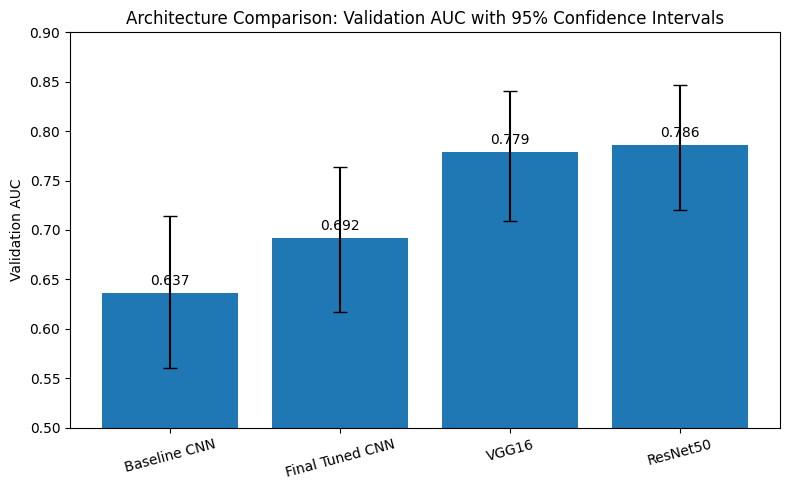

In [81]:
#Validation AUC with 95% CIs
models = experiment_2_final_table['Model']
aucs = experiment_2_final_table['AUC']
lower = aucs - experiment_2_final_table['95% CI Lower']
upper = experiment_2_final_table['95% CI Upper'] - aucs

plt.figure(figsize=(8, 5))
bars = plt.bar(models, aucs, yerr=[lower, upper], capsize=5)

plt.ylabel('Validation AUC')
plt.title('Architecture Comparison: Validation AUC with 95% Confidence Intervals')
plt.ylim(0.5, 0.9)
plt.xticks(rotation=15)

for bar, auc in zip(bars, aucs):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.008,
        f'{auc:.3f}',
        ha='center'
    )

plt.tight_layout()
plt.show()

Transfer learning achieved the highest validation AUCs, with ResNet50 slightly exceeding VGG16. Both substantially improved over custom CNNs.

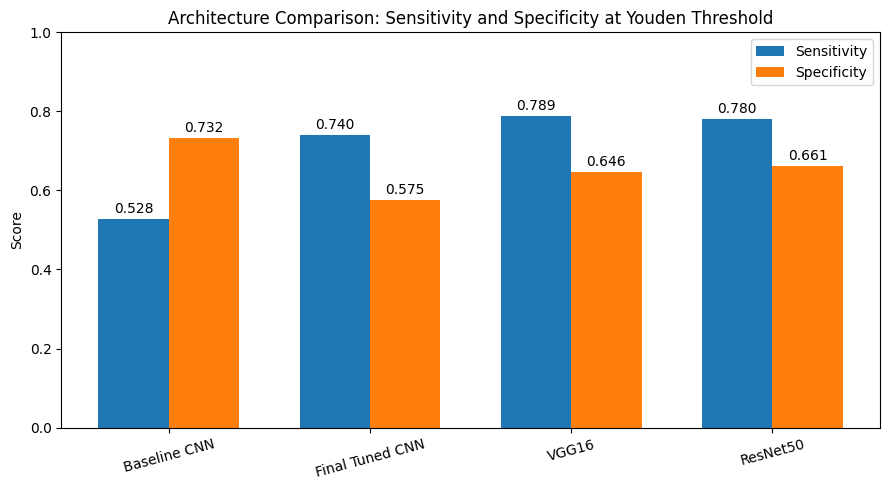

In [82]:
#Sensitivity and specificity comparison
x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))
bars1 = plt.bar(x - width/2, experiment_2_final_table['Sensitivity'], width, label='Sensitivity')
bars2 = plt.bar(x + width/2, experiment_2_final_table['Specificity'], width, label='Specificity')

plt.ylabel('Score')
plt.title('Architecture Comparison: Sensitivity and Specificity at Youden Threshold')
plt.xticks(x, models, rotation=15)
plt.ylim(0, 1)
plt.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.015,
                 f'{bar.get_height():.3f}', ha='center')

plt.tight_layout()
plt.show()

VGG16 and ResNet50 achieved similar sensitvity-specificity balances, while the final tuned CNN favoures sensitvity at the expense of specificty.

## Final Model Selection

AUC was used as the primary mmodel-selection metrix, with sensitvity consideres as a clinically important secondary metric. VGG16 and ResNet50 achieved similar validation performance, with no with no statistically significant differences identified between them. ResNet50 was therefore selected based on its slightly higher observed validation AUC of 0.7859.

At its validation-derived Yousen threshold of 0.4232, ResNet50 achieved a sensitvity of 0.7805 and specificty of 0.6614. The model configuration and decision threshol were then fixed before evaluation on the test held-out set.

## 8 Held-Out Test Evaluation

The selected ResNet50 is evaluated on the untouched CBIS-DDSM test set using the model configuration and decision threshold fixed during validation. The test images are processed using the same ResNet50-specific preprocessing pipeline, with shuffling disabled to preserve evaluation order.

In [50]:
resnet_test_ds = build_resnet50_pipeline(
    X_test,
    y_test,
    shuffle=False
)

print(f"Test images: {len(X_test)}")
print(resnet_test_ds)

Test images: 361
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))>


In [51]:
#Function to evaluate resnet50 model on test set
def evaluate_test_model(model, test_ds, threshold, model_name):
    y_prob = model.predict(test_ds, verbose=0).ravel()
    y_true = np.concatenate([y.numpy() for _, y in test_ds]).astype(int)
    y_pred = (y_prob >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    return {
        'model': model_name,
        'threshold': threshold,
        'accuracy': accuracy_score(y_true, y_pred),
        'auc': roc_auc_score(y_true, y_prob),
        'sensitivity': tp / (tp + fn),
        'specificity': tn / (tn + fp),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'confusion_matrix': cm,
        'classification_report': classification_report(
            y_true, y_pred, target_names=['Benign', 'Malignant']
        ),
        'y_true': y_true,
        'y_prob': y_prob,
        'y_pred': y_pred
    }

### 8.1 Test Set Performance

In [74]:
resnet_test_results = evaluate_test_model(
    resnet_final_model,
    resnet_test_ds,
    threshold=final_threshold,
    model_name='ResNet50'
)

print("ResNet50 Final Test Evaluation")
print(f"Threshold:   {resnet_test_results['threshold']:.4f}")
print(f"Accuracy:    {resnet_test_results['accuracy']:.4f}")
print(f"AUC:         {resnet_test_results['auc']:.4f}")
print(f"Sensitivity: {resnet_test_results['sensitivity']:.4f}")
print(f"Specificity: {resnet_test_results['specificity']:.4f}")
print(f"Precision:   {resnet_test_results['precision']:.4f}")

print("\nConfusion Matrix:")
print(resnet_test_results['confusion_matrix'])

print("\nClassification Report:")
print(resnet_test_results['classification_report'])

ResNet50 Final Test Evaluation
Threshold:   0.4232
Accuracy:    0.6399
AUC:         0.7064
Sensitivity: 0.7172
Specificity: 0.5880
Precision:   0.5389

Confusion Matrix:
[[127  89]
 [ 41 104]]

Classification Report:
              precision    recall  f1-score   support

      Benign     0.7560    0.5880    0.6615       216
   Malignant     0.5389    0.7172    0.6154       145

    accuracy                         0.6399       361
   macro avg     0.6474    0.6526    0.6384       361
weighted avg     0.6688    0.6399    0.6430       361



On the held-out test set, ResNet50 achieved an AUC of 0.7064 and accuracy of 0.6399. At the fixed validation-derived threshold of 0.4232, sensitivity was 0.7172 and specificity was 0.5880, showing reduced performance compared with validation.

### 8.2 Test Set Confidence Intervals

In [77]:
test_auc_ci, test_sens_ci, test_spec_ci = patient_cluster_bootstrap(
    resnet_test_results['y_true'],
    resnet_test_results['y_pred_prob'],
    test_patient_ids,
    final_threshold,
    n_boot=2000,
    seed=42
)

print("ResNet50 Final Test Results with 95% Patient-Cluster Bootstrap CIs")
print(f"AUC:         {resnet_test_results['auc']:.4f} "
      f"[{test_auc_ci[0]:.4f}, {test_auc_ci[1]:.4f}]")
print(f"Sensitivity: {resnet_test_results['sensitivity']:.4f} "
      f"[{test_sens_ci[0]:.4f}, {test_sens_ci[1]:.4f}]")
print(f"Specificity: {resnet_test_results['specificity']:.4f} "
      f"[{test_spec_ci[0]:.4f}, {test_spec_ci[1]:.4f}]")

ResNet50 Final Test Results with 95% Patient-Cluster Bootstrap CIs
AUC:         0.7064 [0.6401, 0.7670]
Sensitivity: 0.7172 [0.6305, 0.8039]
Specificity: 0.5880 [0.5110, 0.6636]


The bootstrap intervals show uncertainty around the held-out performance estimates, with AUC ranging from 0.6401 to 0.7670. Sensitivity remained higher than specificity at the fixed validation-derived threshold.

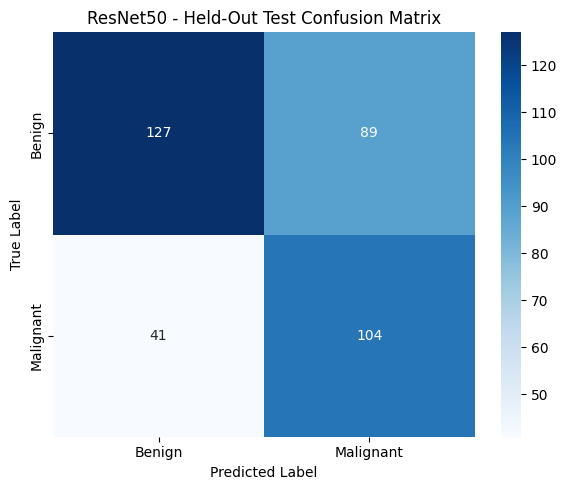

In [78]:
#Final ResNet50 test confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    resnet_test_results['confusion_matrix'],
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.title('ResNet50 - Held-Out Test Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

The model correctly classified 104 of 145 malignant cases and 127 of 216 benign cases, while producing 41 false negatives and 89 false positives. This is consistent with the higher test sensitivity than specificity.

## 9 Grad-CAM Interpretability Analysis

Grad-CAM is applied to the final ResNet50 to visualise image regions contributing to its malignancy predictions. This provides post-hoc interpretability and does not influence model selection or the fixed classification threshold.

In [83]:
resnet_final_model.summary()

Model: "ResNet50_Transfer_Learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 68,458,117 (261.15 MB)

 Trainable params: 22,304,001 (85.08 MB)

 Non-trainable params: 1,546,112 (5.90 MB)

 Optimizer params: 44,608,004 (170.17 MB)

In [84]:
resnet_base = resnet_final_model.get_layer('resnet50')

print(resnet_base.get_layer('conv5_block3_out').output.shape)

(None, 7, 7, 2048)


In [85]:
#Grad-CAM function
def make_gradcam_heatmap(image_batch, model):
    #Extract final convolution feature maps
    resnet_base = model.get_layer('resnet50')
    conv_model = tf.keras.Model(
        resnet_base.input,
        resnet_base.get_layer('conv5_block3_out').output
    )

    with tf.GradientTape() as tape:
        conv_output = conv_model(image_batch, training=False)
        #Pass feature maps through classification head
        x = model.get_layer('global_average_pooling2d_3')(conv_output)
        x = model.get_layer('dense_6')(x)
        x = model.get_layer('dropout_3')(x, training=False)
        prediction = model.get_layer('dense_7')(x)

    #Calculate importance of each feature map
    gradients = tape.gradient(prediction, conv_output)
    weights = tf.reduce_mean(gradients, axis=(1, 2))

    #Generate heatmap for Grad-cam
    heatmap = tf.reduce_sum(
        conv_output * weights[:, None, None, :],
        axis=-1
    )

    heatmap = tf.nn.relu(heatmap)
    heatmap /= tf.reduce_max(heatmap, axis=(1, 2), keepdims=True) + 1e-8

    return heatmap[0].numpy()

In [106]:
#Selected TP, TN, FP and FN examples for Grad-CAM analysis
y_true = resnet_test_results['y_true']
y_pred = resnet_test_results['y_pred']

gradcam_indices = {
    'True Positive': 13,
    'True Negative': 4,
    'False Positive': 35,
    'False Negative': 6
}

for name, idx in gradcam_indices.items():
    print(
        f"{name}: index={idx}, "
        f"true={y_true[idx]}, "
        f"probability={resnet_test_results['y_pred_prob'][idx]:.4f}"
    )

True Positive: index=13, true=1, probability=0.9926
True Negative: index=4, true=0, probability=0.0251
False Positive: index=35, true=0, probability=0.7311
False Negative: index=6, true=1, probability=0.3264


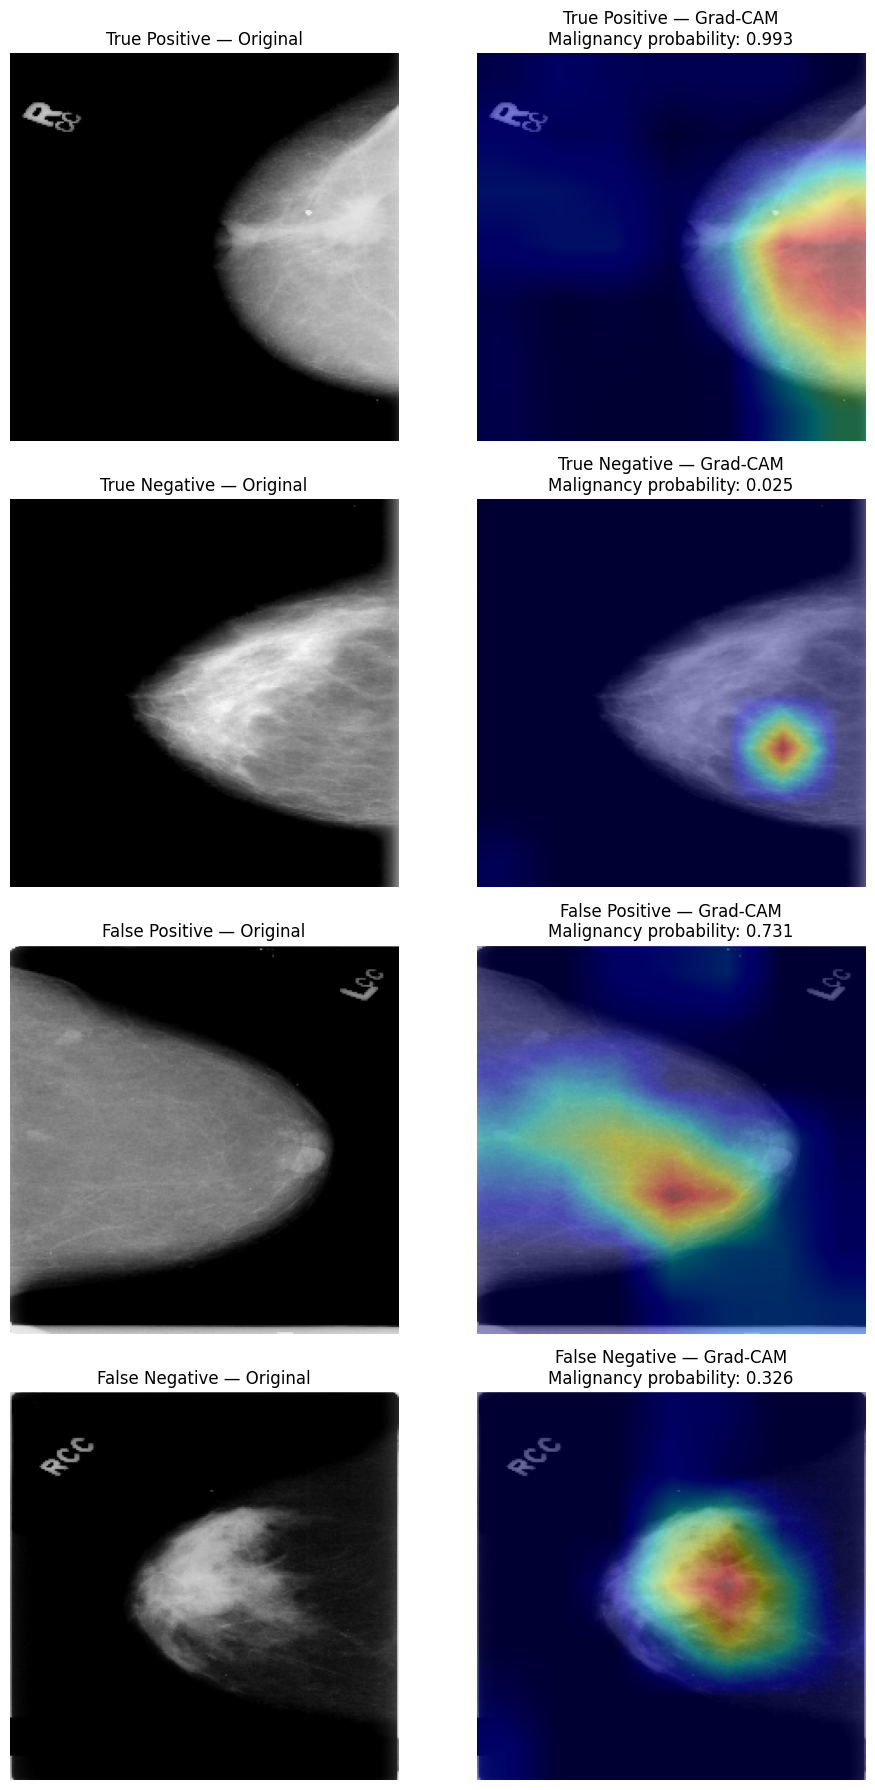

In [107]:
#Display Grad-CAM examples
fig, axes = plt.subplots(4, 2, figsize=(10, 18))

for row, (name, idx) in enumerate(gradcam_indices.items()):
    path = X_test[idx]

    #Original image
    image_bytes = tf.io.read_file(path)
    original = tf.image.decode_jpeg(image_bytes, channels=3)
    original = tf.image.resize(original, (224, 224))

    #ResNet50 input
    model_input = tf.keras.applications.resnet50.preprocess_input(
        tf.cast(original, tf.float32)
    )
    model_input = tf.expand_dims(model_input, axis=0)

    #Grad-CAM
    heatmap = make_gradcam_heatmap(model_input, resnet_final_model)

    #Resize heatmap for overlay
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis], (224, 224)
    ).numpy().squeeze()

    prob = resnet_test_results['y_pred_prob'][idx]

    axes[row, 0].imshow(original.numpy().astype('uint8'))
    axes[row, 0].set_title(f'{name} — Original')
    axes[row, 0].axis('off')

    axes[row, 1].imshow(original.numpy().astype('uint8'))
    axes[row, 1].imshow(
        heatmap_resized,
        cmap='jet',
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    axes[row, 1].set_title(
        f'{name} — Grad-CAM\nMalignancy probability: {prob:.3f}'
    )
    axes[row, 1].axis('off')

plt.tight_layout()
plt.show()

Grad-CAM visualisation showed that the final ResNet50 generally concentrated its activation within breast tissue across the selected examples, indicating that its predictions were associated primarily with anatomical image regions rather than the surrounding background. In the true-positive case, strong activation was observed within the breast alongside a high malignancy probability of 0.993, while the true-negative example also exhibited localised activation within breast tissue despite its low malignancy probability. Importantly, localisation alone did not correspond to correct classification. The false-positive case showed strong internal activation despite the image being benign, suggesting that benign tissue characteristics may have elicited features associated with malignancy. Conversely, the false-negative case exhibited substantial activation within the breast but remained below the classification threshold. These examples indicate that the model can attend to anatomically relevant regions while still incorrectly interpreting the features present within them. However, because Grad-CAM provides coarse post-hoc localisation and was not compared directly with lesion-level annotations, the highlighted regions cannot be interpreted as confirmed lesion localisation or as causal explanations of the predictions.

##10 External Evaluation: INbreast

The final ResNet50 is additionally evaluated on the independently sourced INbreast dataset to examine generalisation beyond CBIS-DDSM. The model is evaluated without retraining or threshold recalibration, retaining the validation-derived threshold of 0.4232.

In [37]:
import kagglehub

path = kagglehub.dataset_download("ramanathansp20/inbreast-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'inbreast-dataset' dataset.
Path to dataset files: /kaggle/input/inbreast-dataset


In [38]:
xls_path = f"{path}/INbreast Release 1.0/INbreast.xls"
inbreast_xls = pd.read_excel(xls_path)

print(inbreast_xls.columns.tolist())
print(inbreast_xls.head(10))

['Patient ID', 'Patient age', 'Laterality', 'View', 'Acquisition date', 'File Name', 'ACR', 'Bi-Rads', 'Mass ', 'Micros', 'Distortion', 'Asymmetry', 'Findings Notes (in Portuguese)', 'Other Notes', 'Lesion Annotation Status', 'Pectoral Muscle Annotation', 'Other Annotations']
  Patient ID Patient age Laterality View  Acquisition date   File Name ACR  \
0    removed     removed          R   CC          201001.0  22678622.0   4   
1    removed     removed          L   CC          201001.0  22678646.0   4   
2    removed     removed          R  MLO          201001.0  22678670.0   4   
3    removed     removed          L  MLO          201001.0  22678694.0   4   
4    removed     removed          R   CC          201001.0  22614074.0   2   
5    removed     removed          L   CC          201001.0  22614097.0   2   
6    removed     removed          R  MLO          201001.0  22614127.0   2   
7    removed     removed          L  MLO          201001.0  22614150.0   2   
8    removed     remo

### 10.1 INbreast Case Selection

Mammograms containing masses are identified from the INbreast metadata before applying the external-evaluation inclusion criteria.

In [39]:
#Select mammograms containing a mass
mass_cases = inbreast_xls[
    inbreast_xls['Mass '].astype(str).str.strip().str.upper().eq('X')
].copy()

print("Total mass mammograms:", len(mass_cases))
print("\nBI-RADS distribution:")
print(
    mass_cases['Bi-Rads']
    .astype(str)
    .str.strip()
    .value_counts()
    .sort_index()
)

Total mass mammograms: 108

BI-RADS distribution:
Bi-Rads
2     24
3     13
4a     7
4b     2
4c    11
5     43
6      8
Name: count, dtype: int64


In [40]:
#Create high-confidence mass subset for external evaluation
mass_cases['birads_clean'] = mass_cases['Bi-Rads'].astype(str).str.strip().str.lower()

inbreast_external = mass_cases[
    mass_cases['birads_clean'].isin(['2', '3', '5', '6'])
].copy()

inbreast_external['label'] = inbreast_external['birads_clean'].isin(['5', '6']).astype(int)

print("External validation images:", len(inbreast_external))
print("\nClass distribution:")
print(inbreast_external['label'].value_counts().sort_index())

External validation images: 88

Class distribution:
label
0    37
1    51
Name: count, dtype: int64


In [41]:
import os, glob

dicom_dir = f"{path}/INbreast Release 1.0/AllDICOMs"

dicom_lookup = {
    os.path.basename(f).split("_")[0]: f
    for f in glob.glob(os.path.join(dicom_dir, "*.dcm"))
}

inbreast_external['file_id'] = (
    inbreast_external['File Name']
    .astype(str)
    .str.replace('.0', '', regex=False)
)

inbreast_external['dicom_path'] = (
    inbreast_external['file_id'].map(dicom_lookup)
)

print("External validation rows:", len(inbreast_external))
print("Matched DICOMs:", inbreast_external['dicom_path'].notna().sum())
print("Missing DICOMs:", inbreast_external['dicom_path'].isna().sum())

print("\nMissing file IDs:")
print(
    inbreast_external.loc[
        inbreast_external['dicom_path'].isna(),
        'file_id'
    ].tolist()
)

External validation rows: 88
Matched DICOMs: 88
Missing DICOMs: 0

Missing file IDs:
[]


In [47]:
!pip install pydicom --quiet
import pydicom

In [42]:
#Function to load Inbreast-evaluation
def load_inbreast_dicom(dicom_path, size=224):
    dcm = pydicom.dcmread(dicom_path)
    img = dcm.pixel_array.astype(np.float32)

    #Handle inverted DICOMs
    if dcm.PhotometricInterpretation == 'MONOCHROME1':
        img = img.max() - img

    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    img = (img * 255).astype(np.uint8)

    #Match ResNet50's input
    img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    img = cv2.resize(img, (size, size))

    return img

### 10.2 INbreast Sample Visualisation

A random sample of the selected INbreast mammograms is visualised to inspect the external images and their assigned binary labels.

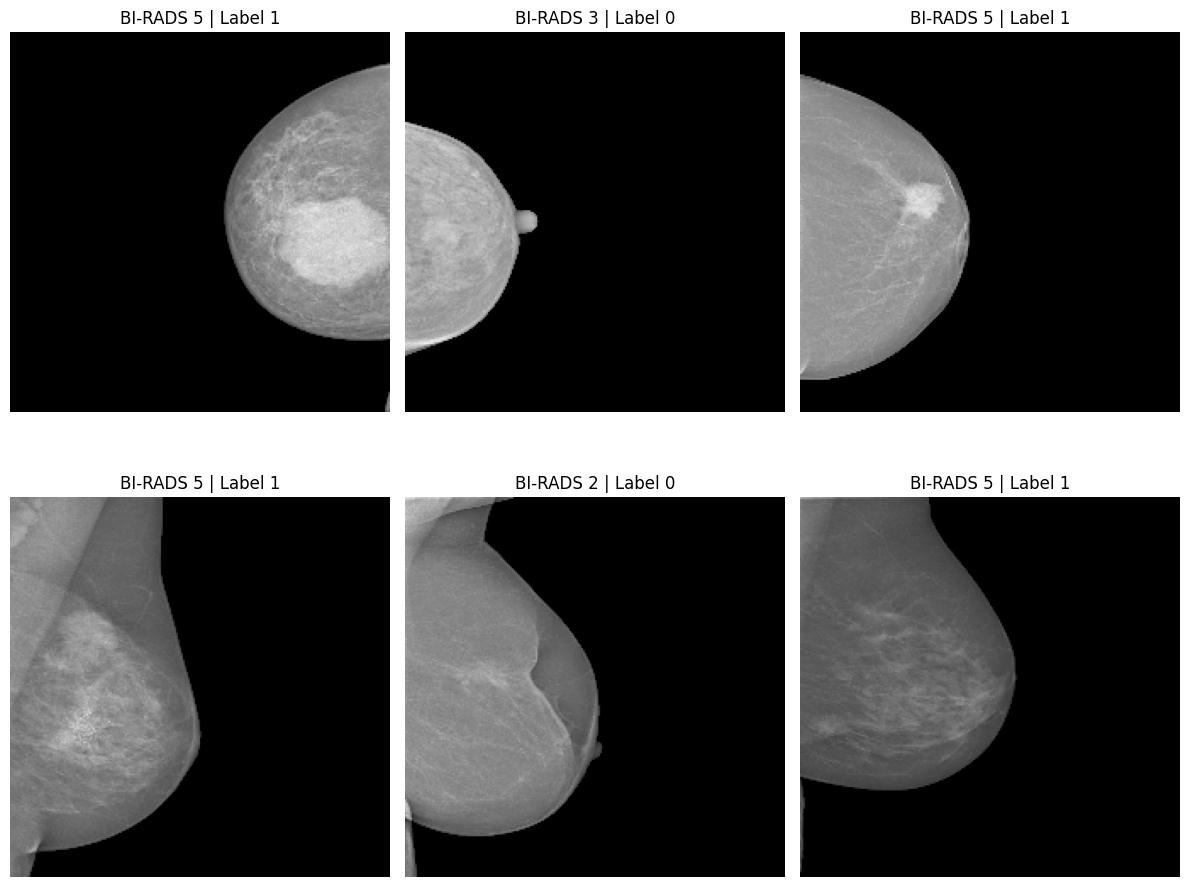

In [150]:
sample = inbreast_external.sample(6, random_state=42)
fig, axes = plt.subplots(2, 3, figsize=(12, 10))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    img = load_inbreast_dicom(row['dicom_path'])

    ax.imshow(img)
    ax.set_title(
        f"BI-RADS {row['birads_clean']} | "
        f"Label {row['label']}"
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

### 10.3 Patient Identification

Patient identifiers are extracted from the INbreast filenames to preserve patient-level grouping during bootstrap evaluation.

In [43]:
def get_inbreast_patient_id(dicom_path):
    filename = os.path.basename(dicom_path)
    parts = filename.split('_')
    return parts[1]

inbreast_external['patient_id'] = (
    inbreast_external['dicom_path'].apply(get_inbreast_patient_id)
)

print("Images:", len(inbreast_external))
print("Unique patients:", inbreast_external['patient_id'].nunique())

print("\nExample mappings:")
print(
    inbreast_external[
        ['file_id', 'patient_id', 'Laterality', 'View', 'birads_clean', 'label']
    ].head(10)
)

Images: 88
Unique patients: 42

Example mappings:
     file_id        patient_id Laterality View birads_clean  label
1   22678646  61b13c59bcba149e          L   CC            3      0
3   22678694  61b13c59bcba149e          L  MLO            3      0
4   22614074  6bd24a0a42c19ce1          R   CC            5      1
5   22614097  6bd24a0a42c19ce1          L   CC            2      0
6   22614127  6bd24a0a42c19ce1          R  MLO            5      1
7   22614150  6bd24a0a42c19ce1          L  MLO            2      0
16  22580192  5530d5782fc89dd7          R   CC            3      0
18  22580244  5530d5782fc89dd7          R  MLO            3      0
28  22670620  e15a16f87b4f9782          R   CC            2      0
30  22670673  e15a16f87b4f9782          R  MLO            2      0


In [48]:
X_inbreast = np.stack([
    load_inbreast_dicom(path)
    for path in inbreast_external['dicom_path']
])

y_inbreast = inbreast_external['label'].to_numpy().astype(int)

print("X_inbreast shape:", X_inbreast.shape)
print("y_inbreast shape:", y_inbreast.shape)
print("Benign:", np.sum(y_inbreast == 0))
print("Malignant:", np.sum(y_inbreast == 1))

X_inbreast shape: (88, 224, 224, 3)
y_inbreast shape: (88,)
Benign: 37
Malignant: 51


In [50]:
#Apply ResNet50 preprocessing
X_inbreast_resnet = tf.keras.applications.resnet50.preprocess_input(X_inbreast.copy())

inbreast_ds = (
    tf.data.Dataset.from_tensor_slices((X_inbreast_resnet, y_inbreast))
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

### 10.4 External Evaluation Results

The final ResNet50 is evaluated on INbreast using the fixed validation-derived threshold of 0.4232, without retraining or threshold recalibration.

In [53]:
#Evaluate ResNet50 on INbreast
inbreast_results = evaluate_test_model(
    resnet_final_model,
    inbreast_ds,
    threshold=final_threshold,
    model_name='ResNet50 - INbreast'
)

print(f"Threshold: {inbreast_results['threshold']:.4f}")
print(f"Accuracy: {inbreast_results['accuracy']:.4f}")
print(f"AUC: {inbreast_results['auc']:.4f}")
print(f"Sensitivity: {inbreast_results['sensitivity']:.4f}")
print(f"Specificity: {inbreast_results['specificity']:.4f}")
print(f"Precision: {inbreast_results['precision']:.4f}")

print("\nConfusion Matrix:")
print(inbreast_results['confusion_matrix'])

print("\nClassification Report:")
print(classification_report(
    inbreast_results['y_true'],
    inbreast_results['y_pred'],
    target_names=['Benign', 'Malignant'],
    digits=4
))

Threshold: 0.4232
Accuracy: 0.6250
AUC: 0.6131
Sensitivity: 0.9608
Specificity: 0.1622
Precision: 0.6125

Confusion Matrix:
[[ 6 31]
 [ 2 49]]

Classification Report:
              precision    recall  f1-score   support

      Benign     0.7500    0.1622    0.2667        37
   Malignant     0.6125    0.9608    0.7481        51

    accuracy                         0.6250        88
   macro avg     0.6813    0.5615    0.5074        88
weighted avg     0.6703    0.6250    0.5457        88



External evaluation produced an AUC of 0.6131, with high sensitivity but very low specificity. This indicates a strong tendency to classify INbreast cases as malignant and substantially weaker generalisation beyond CBIS-DDSM. The reduced AUC also suggests that this decline was not solely due to the transferred decision threshold, but reflected weaker discrimination on the external dataset.

### 10.5 External Evaluation Confidence Intervals

In [55]:
#Generate predictions for bootstrap analysis
y_true_inbreast = y_inbreast
y_prob_inbreast = resnet_final_model.predict(inbreast_ds, verbose=0).ravel()

In [59]:
# Extract patient IDs for patient-cluster bootstrap
inbreast_external['patient_id'] = (
    inbreast_external['File Name']
    .astype(str)
    .str.split('_')
    .str[0]
)

patient_ids_inbreast = inbreast_external['patient_id'].to_numpy()

print("Unique patients:", len(np.unique(patient_ids_inbreast)))

Unique patients: 88


In [61]:
#Patient-cluster bootstrap confidence intervals
auc_lower, auc_upper, _ = patient_cluster_bootstrap_auc(
    y_true_inbreast,
    y_prob_inbreast,
    patient_ids_inbreast,
    n_bootstrap=2000,
    random_state=42
)

sens_lower, sens_upper, spec_lower, spec_upper = (
    patient_cluster_bootstrap_threshold_metrics(
        y_true_inbreast,
        y_prob_inbreast,
        patient_ids_inbreast,
        final_threshold,
        n_bootstrap=2000,
        random_state=42
    )
)

print(
    f"AUC: {inbreast_results['auc']:.4f} "
    f"[{auc_lower:.4f}, {auc_upper:.4f}]"
)
print(
    f"Sensitivity: {inbreast_results['sensitivity']:.4f} "
    f"[{sens_lower:.4f}, {sens_upper:.4f}]"
)
print(
    f"Specificity: {inbreast_results['specificity']:.4f} "
    f"[{spec_lower:.4f}, {spec_upper:.4f}]"
)

AUC: 0.6131 [0.4870, 0.7318]
Sensitivity: 0.9608 [0.9000, 1.0000]
Specificity: 0.1622 [0.0488, 0.2903]


The wide confidence intervals reflect uncertainty in the relatively small external sample.Sensitvity remained consistently hifh, while the low specificity  interval reinforces the model's strong tendency towards malignant predictions on INbreast.

## 11 Gradio Proof-of-Concept

A simple Gradio interface is implemented as a proof-of-concept demonstration of the final ResNet50 model. The interface accepts an uploaded mammogram, applies the same preprocessing used during model evaluation and generates a malignancy probability using the fixed validation-derived threshold of 0.4232. The predicted class and confidence are displayed alongside a Grad-CAM visualisation to provide a qualitative indication of the image regions contributing to the prediction.

This interface is intended only to demonstrate how the developed model could be incorporated into an interactive application and is not designed for clinical use.

In [1]:
# Gradio demonstration interface
!pip install -q --upgrade gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 kB 2.6 MB/s eta 0:00:00


In [30]:
import gradio as gr

print("Gradio version:", gr.__version__)

Gradio version: 6.26.0


In [31]:
#Lock final model before held-out test evaluation
final_model_name = "ResNet50"
final_threshold = 0.42323553562164307

print(f"Final model: {final_model_name}")
print(f"Locked validation-selected threshold: {final_threshold:.6f}")

Final model: ResNet50
Locked validation-selected threshold: 0.423236


In [32]:
resnet_final_model = tf.keras.models.load_model(
    os.path.join(save_dir, 'best_resnet50_finetuned.keras')
)

print("Final ResNet50 checkpoint loaded.")

Final ResNet50 checkpoint loaded.


In [33]:
def make_gradcam_heatmap(image, model):
    base_model = model.get_layer("resnet50")

    grad_model = tf.keras.Model(
        inputs=base_model.input,
        outputs=[
            base_model.get_layer("conv5_block3_out").output,
            base_model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_output, base_output = grad_model(image)

        x = model.get_layer("global_average_pooling2d_3")(base_output)
        x = model.get_layer("dense_6")(x)
        x = model.get_layer("dropout_3")(x, training=False)
        prediction = model.get_layer("dense_7")(x)

        class_score = prediction[:, 0]

    gradients = tape.gradient(class_score, conv_output)

    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2)
    )

    heatmap = tf.reduce_sum(
        conv_output * weights[:, None, None, :],
        axis=-1
    )

    heatmap = tf.nn.relu(heatmap)

    heatmap = heatmap[0]

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    return heatmap.numpy()

In [84]:
image_bytes = tf.io.read_file(tp_path)
image = tf.image.decode_jpeg(image_bytes, channels=3)
image = tf.image.resize(image, (224, 224))
image = tf.cast(image, tf.float32)

model_input = tf.keras.applications.resnet50.preprocess_input(image)
model_input = tf.expand_dims(model_input, axis=0)

heatmap = make_gradcam_heatmap(
    model_input,
    resnet_final_model
)

print("Heatmap shape:", heatmap.shape)
print("Heatmap min:", heatmap.min())
print("Heatmap max:", heatmap.max())

Heatmap shape: (7, 7)
Heatmap min: 0.0
Heatmap max: 0.9999997


In [35]:
def gradio_predict(image_path):
    if image_path is None:
        return "No image uploaded", 0.0, None

    #Preprocess image
    image = tf.image.decode_jpeg(tf.io.read_file(image_path), channels=3)
    image = tf.image.resize(image, (224, 224))
    image = tf.cast(image, tf.float32)

    model_input = tf.keras.applications.resnet50.preprocess_input(image)
    model_input = tf.expand_dims(model_input, axis=0)

    #Generate prediction
    probability = float(resnet_final_model.predict(model_input, verbose=0)[0][0])
    prediction = "Malignant" if probability >= final_threshold else "Benign"

    #Generate Grad-CAM overlay
    heatmap = make_gradcam_heatmap(model_input, resnet_final_model)
    heatmap = tf.image.resize(heatmap[..., np.newaxis], (224, 224)).numpy().squeeze()

    original = image.numpy().astype("uint8")
    coloured_heatmap = (plt.get_cmap("jet")(heatmap)[..., :3] * 255).astype("uint8")
    overlay = np.clip(0.6 * original + 0.4 * coloured_heatmap, 0, 255).astype("uint8")

    #Restore original image dimensions
    height, width = cv2.imread(image_path).shape[:2]
    overlay = cv2.resize(overlay, (width, height), interpolation=cv2.INTER_CUBIC)

    return prediction, probability, overlay

In [36]:
custom_css = """
/* Overall page background */
body,
.gradio-container {
    background: #eaf4fb !important;
}

/* Main container */
.gradio-container {
    max-width: 1200px !important;
    margin: auto !important;
}

/* Header */
.header {
    text-align: center;
    padding: 25px 10px 15px 10px;
}

.header h1 {
    color: #174a73;
    margin-bottom: 8px;
}

.subtitle {
    color: #4f6f86;
    font-size: 16px;
}

/* Section headings */
.section-title {
    color: #174a73;
    font-size: 18px;
    font-weight: 600;
    margin-top: 15px;
    margin-bottom: 8px;
}

/* Keep image/upload areas dark */
.image-container {
    background: #111111 !important;
}

/* Analyse button */
#analyse-button {
    max-width: 350px;
    margin: 20px auto;
}
prediction_output = gr.Textbox(
    label="Classification",
    interactive=False,
    elem_id="prediction-box"
)

probability_output = gr.Number(
    label="Malignancy Probability",
    interactive=False,
    precision=4,
    elem_id="probability-box"
)
"""


with gr.Blocks(
    title="Breast Cancer Mammogram Classifier",
    css=custom_css
) as demo:

    #Header
    gr.HTML(
        """
        <div class="header">
            <h1>Breast Cancer Mammogram Classifier</h1>
            <div class="subtitle">
                Deep learning classification with Grad-CAM visualisation
            </div>
        </div>
        """
    )

    #Image analysis section
    gr.HTML(
        '<div class="section-title">Mammogram Analysis</div>'
    )

    with gr.Row(equal_height=True):

        image_input = gr.Image(
            type="filepath",
            label="Uploaded Mammogram",
            height=500,
            scale=1
        )

        gradcam_output = gr.Image(
            label="Grad-CAM Visualisation",
            height=500,
            scale=1
        )

    #Analyse button
    predict_button = gr.Button(
        "Analyse Mammogram",
        variant="primary",
        elem_id="analyse-button"
    )

    #Results section
    gr.HTML(
        '<div class="section-title">Prediction Results</div>'
    )

    with gr.Row():

        prediction_output = gr.Textbox(
            label="Classification",
            interactive=False
        )

        probability_output = gr.Number(
            label="Malignancy Probability",
            interactive=False,
            precision=4
        )


    #Prediction space
    predict_button.click(
        fn=gradio_predict,
        inputs=image_input,
        outputs=[
            prediction_output,
            probability_output,
            gradcam_output
        ]
    )


demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://70b83eeda0fc0956d4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
